In [1]:
%pip install numpy pandas matplotlib xarray netCDF4 scipy h5py utide

Note: you may need to restart the kernel to use updated packages.


In [4]:
"""
============================================================================
ReDAPT / EMEC Fall of Warness  --  Tidal resource & load-factor pipeline
Starter script (run inside VS Code, stage by stage).

UPDATED to match:
  - the now-UNZIPPED folder structure (each item is a folder of .nc / .mat)
  - the CONFIRMED variable schema from the two Dataset User Guidance docs
    (RDI Workhorse Sentinel 600 kHz, CF-1.8 NetCDF, QARTOD QC flags).
============================================================================

DATA RECAP
  - Type A ("NW"):  ADCP01_NW (SN 16159) + ADCP02_NW (SN 19139), summer 2014,
                    placed NW of the turbine (upstream on flood).
  - Type B ("TD7"): ADCPTD7_01 (SN 19139) + ADCPTD7_02 (SN 16159), autumn 2014,
                    placed NE / SW of the turbine.
  - Same two physical instruments, repositioned between campaigns.
  - FLOW data only (no turbine power) -> use the published MC7.1 measured curve
    and/or the Lewis (2021) standardised curve as the turbine transfer function.

REQUIREMENTS (pip):
  numpy pandas matplotlib xarray netCDF4 scipy h5py utide
============================================================================
"""

from pathlib import Path
import numpy as np
import pandas as pd

# ---------------------------------------------------------------------------
# CONFIG  (folders are already unzipped; each item below is a FOLDER of files)
# ---------------------------------------------------------------------------
TYPE_A_DIR = Path(r"C:\Users\Steven Tarigan\Tidal dissertation\Download\Field-Measurements PPA Type A")
TYPE_B_DIR = Path(r"C:\Users\Steven Tarigan\Tidal dissertation\Download\Field-Measurements PPA Type B")

# --- CONFIRMED NetCDF variable names (from the User Guidance) ---------------
VARS = dict(
    time="times",                 # days since 1900-01-01 00:00:00 UTC
    u="vel_geo_east",             # [nrecs, nbins]  Eastward velocity [m/s]
    v="vel_geo_north",            # [nrecs, nbins]  Northward velocity [m/s]
    w="vel_geo_up",               # [nrecs, nbins]  Vertical velocity [m/s]
    pressure="pressure",          # [nrecs]         depth from pressure [m]
    heading="heading", pitch="pitch", roll="roll",
    head_hab="head_hab",          # transducer head height above seabed [m]
    bin_dist="bin_dist",          # distance to first bin [m]
    bin_size="bin_size",          # bin length [m]
    num_bins="num_bins",
    # QC flag variables (1 pass / 2 not-eval / 3 suspect / 4 fail)
    qc_corr="qc_correlation", qc_sig="qc_signalstrength", qc_echo="qc_echointensity",
    qc_vlim="qc_velocitylimits", qc_verr="qc_errorvelocity",
    qc_vgrad="qc_velocitygradient", qc_pcgd="qc_percentgood",
    qc_deploy="qc_deploydepth",   # [nrecs] flags deployment/recovery (drop these)
)
QC_PASS = (1, 2)   # keep flags 1 (passed) and 2 (not evaluated); drop 3 & 4

# --- Turbine / site constants from ReDAPT MC7.1 (DEEP-Gen IV) ---------------
TURBINE = dict(
    name="DEEP-Gen IV", rated_power_kW=1000.0, rated_speed=2.70, cut_in=1.00,
    rotor_diameter=18.08, capture_area=256.74, hub_above_bed=19.0, cp_max=0.42,
)
# Published site benchmarks (MC7.1 Table 5-2 / MD6.1) -> use to QC your output
SITE_BENCHMARK = dict(
    mean_current=1.804, mean_flood=1.701, mean_ebb=1.896,
    mean_spring_peak=3.079, mean_neap_peak=1.744,
    flood_dir_deg=137.0, ebb_dir_deg=331.0,
    rho_seawater=1027.0, published_load_factor=0.342,
)
# TEC position (UTM Zone 30N) for upstream/downstream (wake) reasoning
TEC_EAST, TEC_NORTH = 511112.0, 6555308.0


# ===========================================================================
# STAGE 0  --  DISCOVER FILES + INSPECT SCHEMA   (run this first)
# ===========================================================================
def discover(type_dir: Path):
    """Recursively list .nc and .mat files now that folders are unzipped."""
    nc = sorted(type_dir.rglob("*.nc"))
    mat = sorted(type_dir.rglob("*.mat"))
    print(f"  {type_dir.name}:  {len(nc)} .nc files, {len(mat)} .mat files")
    return nc, mat


def inspect_netcdf(nc_path: Path):
    import xarray as xr
    ds = xr.open_dataset(nc_path)            # CF times auto-decoded
    print(f"\n=== NetCDF: {nc_path.name} ===")
    print("DIMS:", dict(ds.sizes))
    present = [v for v in VARS.values() if v in ds.variables]
    missing = [v for v in VARS.values() if v not in ds.variables]
    print("EXPECTED VARS PRESENT:", present)
    if missing:
        print("!! EXPECTED VARS MISSING (check naming):", missing)
    # geometry scalars
    for key in ("head_hab", "bin_dist", "bin_size", "num_bins"):
        name = VARS[key]
        if name in ds.variables:
            print(f"  {key:10s} = {float(np.asarray(ds[name]).ravel()[0])}")
    # time span
    if VARS["time"] in ds.variables:
        t = pd.to_datetime(ds[VARS["time"]].values)
        print(f"  time span : {t.min()} -> {t.max()}  (n={t.size})")
    return ds


def inspect_mat(mat_path: Path):
    try:
        from scipy.io import loadmat
        m = loadmat(mat_path, squeeze_me=True, struct_as_record=False)
        print(f"\n=== MAT (<=v7.2): {mat_path.name} ===")
        data = m.get("data", None)
        if data is not None and hasattr(data, "_fieldnames"):
            print("data fields:", data._fieldnames)
        else:
            print("keys:", [k for k in m if not k.startswith('__')])
        return m
    except NotImplementedError:
        import h5py
        print(f"\n=== MAT (v7.3/HDF5): {mat_path.name} ===")
        with h5py.File(mat_path, "r") as f:
            f.visititems(lambda n, o: print("  ", n, getattr(o, "shape", "")))
        return None


def stage0():
    print("Discovering files...")
    for d in (TYPE_A_DIR, TYPE_B_DIR):
        nc, mat = discover(d)
        if nc:
            inspect_netcdf(nc[0])
        if mat:
            inspect_mat(mat[0])


# ===========================================================================
# STAGE 1  --  LOAD & CONCATENATE one deployment's NetCDF files
# ===========================================================================
def bin_heights(ds):
    """Height of each bin centre above the seabed [m]: head_hab + bin_dist + i*bin_size."""
    hab  = float(np.asarray(ds[VARS["head_hab"]]).ravel()[0])
    b0   = float(np.asarray(ds[VARS["bin_dist"]]).ravel()[0])
    bsz  = float(np.asarray(ds[VARS["bin_size"]]).ravel()[0])
    nb   = int(np.asarray(ds[VARS["num_bins"]]).ravel()[0])
    return hab + b0 + np.arange(nb) * bsz


def load_deployment(nc_paths):
    """Open & time-concatenate the daily NetCDF files of ONE deployment."""
    import xarray as xr
    parts = []
    for p in sorted(nc_paths):
        d = xr.open_dataset(p)
        # set time as the coordinate on the record dimension
        tdim = d[VARS["u"]].dims[0]                  # e.g. 'nrecs'
        d = d.assign_coords({tdim: pd.to_datetime(d[VARS["time"]].values)})
        d = d.rename({tdim: "time"})
        parts.append(d)
    ds = xr.concat(parts, dim="time").sortby("time")
    ds = ds.assign_coords(z=("nbins", bin_heights(ds))) if "nbins" in ds.dims else ds
    return ds


# ===========================================================================
# STAGE 2  --  QUALITY CONTROL using the supplied QARTOD flags
# ===========================================================================
def apply_qc(ds):
    """NaN-out velocities failing QARTOD flags; drop deployment/recovery rows."""
    u = ds[VARS["u"]].astype(float)
    v = ds[VARS["v"]].astype(float)

    # 2-D per-bin flags
    bad = None
    for key in ("qc_corr", "qc_sig", "qc_echo", "qc_vlim", "qc_verr", "qc_vgrad", "qc_pcgd"):
        name = VARS[key]
        if name in ds.variables:
            f = ds[name]
            this_bad = ~f.isin(QC_PASS)
            bad = this_bad if bad is None else (bad | this_bad)
    if bad is not None:
        u = u.where(~bad)
        v = v.where(~bad)

    # 1-D deploy/recovery flag -> drop those time steps entirely
    if VARS["qc_deploy"] in ds.variables:
        keep = ds[VARS["qc_deploy"]].isin(QC_PASS)
        u, v = u.where(keep), v.where(keep)

    ds = ds.assign(u_qc=u, v_qc=v)
    return ds


# ===========================================================================
# STAGE 3  --  SPEED/DIR + ROTOR-WEIGHTED VELOCITY (IEC method of bins)
# ===========================================================================
def speed_dir(u, v):
    spd = np.hypot(u, v)
    drc = (np.degrees(np.arctan2(u, v)) + 360) % 360     # bearing from North
    return spd, drc


def rotor_weighted_velocity(ds, hub=TURBINE["hub_above_bed"],
                            R=TURBINE["rotor_diameter"] / 2.0):
    """
    Power-weighted velocity over the rotor disc (MC7.1 Sec 9.2):
        Ubar(t) = ( (1/A) * sum_k U(t,k)^3 * A_k )^(1/3)
    where A_k is the chord-strip area of the rotor disc spanned by bin k.
    """
    z = ds["z"].values                       # bin heights above bed [m]
    U = np.hypot(ds["u_qc"].values, ds["v_qc"].values)   # [time, nbins]
    within = (z >= hub - R) & (z <= hub + R)
    zc = z[within]
    bsz = float(np.asarray(ds[VARS["bin_size"]]).ravel()[0])
    chord = 2.0 * np.sqrt(np.clip(R**2 - (zc - hub) ** 2, 0, None))  # disc chord
    Ak = chord * bsz                                   # strip area weight
    Uw = U[:, within]
    num = np.nansum((Uw ** 3) * Ak[None, :], axis=1)
    Ubar = (num / Ak.sum()) ** (1.0 / 3.0)
    return Ubar


# ===========================================================================
# STAGE 4  --  RESOURCE SUMMARY + VALIDATION AGAINST MD6.1
# ===========================================================================
def direction_is_flood(direction, flood_dir=SITE_BENCHMARK["flood_dir_deg"], window=90):
    diff = np.abs((direction - flood_dir + 180) % 360 - 180)
    return diff <= window


def resource_summary(speed, direction):
    flood = direction_is_flood(direction)
    out = dict(mean=np.nanmean(speed),
               mean_flood=np.nanmean(speed[flood]),
               mean_ebb=np.nanmean(speed[~flood]),
               p95=np.nanpercentile(speed, 95), max=np.nanmax(speed))
    print("Resource vs MC7.1/MD6.1 benchmark (SANITY CHECK):")
    print(f"  mean speed : {out['mean']:.3f}  (published {SITE_BENCHMARK['mean_current']})")
    print(f"  mean flood : {out['mean_flood']:.3f}  (published {SITE_BENCHMARK['mean_flood']})")
    print(f"  mean ebb   : {out['mean_ebb']:.3f}  (published {SITE_BENCHMARK['mean_ebb']})")
    return out


# ===========================================================================
# STAGE 5  --  HARMONIC ANALYSIS + ANNUAL RECONSTRUCTION (uTide)
# ===========================================================================
def harmonic_reconstruct(time, u, v, lat=59.137, target_year=2019):
    import utide
    t_mpl = pd.to_datetime(time).map(lambda d: d.toordinal() + 366
                                     + (d.hour*3600 + d.minute*60 + d.second)/86400.0)
    coef = utide.solve(np.asarray(t_mpl), u, v, lat=lat, method="ols",
                       conf_int="MC", verbose=False)
    t_year = pd.date_range(f"{target_year}-01-01", f"{target_year}-12-31 23:50", freq="10min")
    t_year_mpl = t_year.map(lambda d: d.toordinal() + 366 + (d.hour*3600+d.minute*60)/86400.0)
    rec = utide.reconstruct(np.asarray(t_year_mpl), coef, verbose=False)
    return t_year, np.hypot(rec["u"], rec["v"]), coef


# ===========================================================================
# STAGE 6  --  POWER CURVES + LOAD FACTOR
# ===========================================================================
def lewis_power_curve(u, Vr=TURBINE["rated_speed"], Pr=TURBINE["rated_power_kW"],
                      cut_in_frac=0.30, cp=TURBINE["cp_max"],
                      area=TURBINE["capture_area"], rho=SITE_BENCHMARK["rho_seawater"]):
    u = np.asarray(u, float)
    p = 0.5 * rho * area * cp * u**3 / 1000.0      # W -> kW
    p = np.where(u < cut_in_frac * Vr, 0.0, p)
    return np.minimum(p, Pr)


def load_measured_curve(csv_path):
    """CSV columns: v_centre, mean_power_kW  (transcribe MC7.1 Table 14-1)."""
    tbl = pd.read_csv(csv_path).sort_values("v_centre")
    v, p = tbl["v_centre"].values, tbl["mean_power_kW"].values
    def curve(u):
        u = np.asarray(u, float)
        out = np.interp(u, v, p, left=0.0, right=TURBINE["rated_power_kW"])
        return np.where(u < TURBINE["cut_in"], 0.0, out)
    return curve


def load_factor(power_kW, rated_kW=TURBINE["rated_power_kW"]):
    return np.nanmean(power_kW) / rated_kW


# ===========================================================================
# STAGE 7  --  MONTE-CARLO UNCERTAINTY ON LOAD FACTOR
# ===========================================================================
def monte_carlo_lf(speed_series, n=2000):
    rng = np.random.default_rng(42)
    lfs = []
    for _ in range(n):
        v_shift = rng.normal(0, 0.05)          # rated-speed uncertainty (MC7.1: ~+-2m hub ref)
        avail = rng.uniform(0.85, 0.98)        # availability / derating
        p = lewis_power_curve(speed_series, Vr=TURBINE["rated_speed"] + v_shift)
        lfs.append(load_factor(p) * avail)
    return np.array(lfs)


# ===========================================================================
if __name__ == "__main__":
    stage0()           # run this first; report the printout before continuing

Discovering files...
  Field-Measurements PPA Type A:  89 .nc files, 263 .mat files

=== NetCDF: ADCP01_NW_Dep5_20140619.nc ===
DIMS: {'nrecs': 36396, 'nbins': 46, 'ndof': 3}
EXPECTED VARS PRESENT: ['times', 'vel_geo_east', 'vel_geo_north', 'pressure', 'heading', 'pitch', 'roll', 'head_hab', 'bin_dist', 'bin_size', 'num_bins', 'qc_correlation']
!! EXPECTED VARS MISSING (check naming): ['vel_geo_up', 'qc_signalstrength', 'qc_echointensity', 'qc_velocitylimits', 'qc_errorvelocity', 'qc_velocitygradient', 'qc_percentgood', 'qc_deploydepth']
  head_hab   = 0.800000011920929
  bin_dist   = 2.109999895095825
  bin_size   = 1.0
  num_bins   = 46.0
  time span : 2014-06-19 13:53:23.999998976 -> 2014-06-19 23:59:58.999995392  (n=36396)

=== MAT (v7.3/HDF5): ADCP01_NW_Dep0_RAW_001.mat ===
   DATA 
   DATA/Amp1 (49, 29589)
   DATA/Amp2 (49, 29589)
   DATA/Amp3 (49, 29589)
   DATA/Amp4 (49, 29589)
   DATA/B1 (49, 29589)
   DATA/B2 (49, 29589)
   DATA/B3 (49, 29589)
   DATA/B4 (49, 29589)
   DATA/C

In [5]:
"""
============================================================================
ReDAPT / EMEC Fall of Warness  --  Tidal resource & load-factor pipeline
Starter script (run inside VS Code, stage by stage).

UPDATED after Stage-0 inspection of the real files:
  * Use NetCDF (.nc) as primary source. The .nc files are the long, PROCESSED
    campaigns only -> Type A = Dep5 (summer 2014), Type B = Dep1 (autumn 2014).
    (The short RAW .mat deployments Dep0-Dep3 in Type A are excluded for free.)
  * Confirmed geometry: head_hab=0.8 m, bin_dist=2.11 m, bin_size=1.0 m, 46 bins
    -> bin-centre heights above bed = 2.91 .. 47.91 m. Rotor band (10-28 m) is
    well sampled and clear of surface side-lobe.
  * The .nc carry only qc_correlation among the QARTOD flags. The FULL QARTOD
    suite (T6/T8/T9/T10/T14/T18/T20 + deploy flag C1) lives in the processed
    .mat files -> use those for a QC-sensitivity check if desired.
  * FLOW data only (no turbine power) -> turbine transfer function comes from
    the published MC7.1 measured curve and/or the Lewis (2021) standardised curve.

REQUIREMENTS (pip):
  numpy pandas matplotlib xarray netCDF4 scipy h5py utide
============================================================================
"""

from pathlib import Path
import numpy as np
import pandas as pd

# ---------------------------------------------------------------------------
# CONFIG
# ---------------------------------------------------------------------------
TYPE_A_DIR = Path(r"C:\Users\Steven Tarigan\Tidal dissertation\Download\Field-Measurements PPA Type A")
TYPE_B_DIR = Path(r"C:\Users\Steven Tarigan\Tidal dissertation\Download\Field-Measurements PPA Type B")

# Confirmed NetCDF variable names (from Stage-0 + User Guidance)
VARS = dict(
    time="times", u="vel_geo_east", v="vel_geo_north",
    pressure="pressure", heading="heading", pitch="pitch", roll="roll",
    head_hab="head_hab", bin_dist="bin_dist", bin_size="bin_size", num_bins="num_bins",
    qc_corr="qc_correlation",   # only QARTOD flag present in the .nc
)
QC_PASS = (1, 2)        # keep flags 1 (passed) & 2 (not evaluated); drop 3 & 4
VMAX = 5.0              # m/s, physical horizontal-speed cap (spring peak ~3.1)

# Turbine / site constants from ReDAPT MC7.1 (DEEP-Gen IV)
TURBINE = dict(name="DEEP-Gen IV", rated_power_kW=1000.0, rated_speed=2.70, cut_in=1.00,
               rotor_diameter=18.08, capture_area=256.74, hub_above_bed=19.0, cp_max=0.42)
HUB = TURBINE["hub_above_bed"]
RROT = TURBINE["rotor_diameter"] / 2.0

# Published site benchmarks (MC7.1 Table 5-2 / MD6.1) -> validation gate
SITE_BENCHMARK = dict(mean_current=1.804, mean_flood=1.701, mean_ebb=1.896,
                      mean_spring_peak=3.079, mean_neap_peak=1.744,
                      flood_dir_deg=137.0, ebb_dir_deg=331.0,
                      rho_seawater=1027.0, published_load_factor=0.342)


# ===========================================================================
# STAGE 0  --  DISCOVER + INSPECT (now also dumps the FULL variable list)
# ===========================================================================
def discover(type_dir: Path):
    nc = sorted(type_dir.rglob("*.nc"))
    mat = sorted(type_dir.rglob("*.mat"))
    print(f"  {type_dir.name}:  {len(nc)} .nc, {len(mat)} .mat")
    return nc, mat


def inspect_netcdf(nc_path: Path):
    import xarray as xr
    ds = xr.open_dataset(nc_path)
    print(f"\n=== NetCDF: {nc_path.name} ===")
    print("DIMS:", dict(ds.sizes))
    print("ALL VARS:", list(ds.variables))                 # <-- confirm QC names
    for key in ("head_hab", "bin_dist", "bin_size", "num_bins"):
        if VARS[key] in ds.variables:
            print(f"  {key:9s} = {float(np.asarray(ds[VARS[key]]).ravel()[0])}")
    t = pd.to_datetime(ds[VARS["time"]].values)
    print(f"  time: {t.min()} -> {t.max()} (n={t.size})")
    return ds


def stage0():
    print("Discovering files...")
    for d in (TYPE_A_DIR, TYPE_B_DIR):
        nc, _ = discover(d)
        if nc:
            inspect_netcdf(nc[0])


# ===========================================================================
# HELPERS
# ===========================================================================
def bin_heights(ds):
    hab = float(np.asarray(ds[VARS["head_hab"]]).ravel()[0])
    b0  = float(np.asarray(ds[VARS["bin_dist"]]).ravel()[0])
    bsz = float(np.asarray(ds[VARS["bin_size"]]).ravel()[0])
    nb  = int(np.asarray(ds[VARS["num_bins"]]).ravel()[0])
    return hab + b0 + np.arange(nb) * bsz, bsz


def select_nc(type_dir: Path, instrument: str):
    """e.g. select_nc(TYPE_A_DIR, 'ADCP01_NW_Dep5') -> sorted daily .nc paths."""
    return sorted(type_dir.rglob(f"*{instrument}*.nc"))


# ===========================================================================
# STAGE 1-3 (combined, memory-safe): per-file QC + rotor-weighted velocity
# ===========================================================================
def process_deployment(nc_paths, vmax=VMAX):
    """
    Stream each daily .nc, QC it, and reduce to a rotor-weighted velocity
    series (IEC method of bins) + hub-height direction. Returns 1 Hz DataFrame.
    Memory-safe: never holds all files in RAM at once.
    """
    import xarray as xr
    pieces, removed, total = [], 0, 0
    for p in sorted(nc_paths):
        d = xr.open_dataset(p)
        z, bsz = bin_heights(d)
        u = d[VARS["u"]].values.astype(float)       # [time, nbins]
        v = d[VARS["v"]].values.astype(float)
        total += u.shape[0]

        # (a) correlation QARTOD flag (only one present in .nc)
        if VARS["qc_corr"] in d.variables:
            bad = ~np.isin(d[VARS["qc_corr"]].values, QC_PASS)
            u, v = np.where(bad, np.nan, u), np.where(bad, np.nan, v)
        # (b) physical velocity cap
        spd = np.hypot(u, v)
        u, v = np.where(spd > vmax, np.nan, u), np.where(spd > vmax, np.nan, v)
        # (c) deployment/recovery transient removal via pressure
        pr = d[VARS["pressure"]].values.astype(float)
        keep = pr > 0.5 * np.nanmedian(pr)
        removed += int((~keep).sum())

        # rotor-weighted velocity over bins within the rotor disc
        within = (z >= HUB - RROT) & (z <= HUB + RROT)
        chord = 2.0 * np.sqrt(np.clip(RROT**2 - (z[within] - HUB) ** 2, 0, None))
        Ak = chord * bsz
        Uw = np.hypot(u[:, within], v[:, within])
        Ubar = (np.nansum(Uw**3 * Ak[None, :], axis=1) / Ak.sum()) ** (1.0 / 3.0)

        hub_i = int(np.argmin(np.abs(z - HUB)))
        drc = (np.degrees(np.arctan2(u[:, hub_i], v[:, hub_i])) + 360) % 360

        t = pd.to_datetime(d[VARS["time"]].values)
        df = pd.DataFrame({"U": Ubar, "dir": drc}, index=t)[keep]
        pieces.append(df)
        d.close()

    out = pd.concat(pieces).sort_index()
    out = out[~out.index.duplicated(keep="first")]
    print(f"process_deployment: {len(out)} samples kept; "
          f"{removed}/{total} dropped as deploy/recovery transients")
    return out


# ===========================================================================
# STAGE 4  --  RESOURCE SUMMARY + VALIDATION GATE vs MD6.1
# ===========================================================================
def direction_is_flood(direction, flood_dir=SITE_BENCHMARK["flood_dir_deg"], window=90):
    diff = np.abs((direction - flood_dir + 180) % 360 - 180)
    return diff <= window


def resource_summary(df):
    spd, drc = df["U"].values, df["dir"].values
    flood = direction_is_flood(drc)
    print("\nResource vs MC7.1/MD6.1 benchmark (VALIDATION GATE):")
    print(f"  mean speed : {np.nanmean(spd):.3f}   (published 1.804)")
    print(f"  mean flood : {np.nanmean(spd[flood]):.3f}   (published 1.701)")
    print(f"  mean ebb   : {np.nanmean(spd[~flood]):.3f}   (published 1.896)")
    print(f"  p95 / max  : {np.nanpercentile(spd,95):.3f} / {np.nanmax(spd):.3f}")
    return dict(mean=np.nanmean(spd), flood=np.nanmean(spd[flood]),
                ebb=np.nanmean(spd[~flood]))


# ===========================================================================
# STAGE 5  --  HARMONIC ANALYSIS + ANNUAL RECONSTRUCTION (uTide)
# ===========================================================================
def harmonic_reconstruct(df10, lat=59.137, target_year=2019):
    """df10: 10-min DataFrame with columns u,v (geographic). uTide accepts
    a pandas DatetimeIndex directly in recent versions."""
    import utide
    coef = utide.solve(df10.index, df10["u"].values, df10["v"].values,
                       lat=lat, method="ols", conf_int="MC", verbose=False)
    t_year = pd.date_range(f"{target_year}-01-01", f"{target_year}-12-31 23:50", freq="10min")
    rec = utide.reconstruct(t_year, coef, verbose=False)
    return t_year, np.hypot(rec["u"], rec["v"]), coef


# ===========================================================================
# STAGE 6  --  POWER CURVES + LOAD FACTOR
# ===========================================================================
def lewis_power_curve(u, Vr=TURBINE["rated_speed"], Pr=TURBINE["rated_power_kW"],
                      cut_in_frac=0.30, cp=TURBINE["cp_max"],
                      area=TURBINE["capture_area"], rho=SITE_BENCHMARK["rho_seawater"]):
    u = np.asarray(u, float)
    p = 0.5 * rho * area * cp * u**3 / 1000.0
    p = np.where(u < cut_in_frac * Vr, 0.0, p)
    return np.minimum(p, Pr)


def load_measured_curve(csv_path):
    """CSV columns: v_centre, mean_power_kW  (transcribe MC7.1 Table 14-1)."""
    tbl = pd.read_csv(csv_path).sort_values("v_centre")
    v, p = tbl["v_centre"].values, tbl["mean_power_kW"].values
    def curve(u):
        u = np.asarray(u, float)
        out = np.interp(u, v, p, left=0.0, right=TURBINE["rated_power_kW"])
        return np.where(u < TURBINE["cut_in"], 0.0, out)
    return curve


def load_factor(power_kW, rated_kW=TURBINE["rated_power_kW"]):
    return np.nanmean(power_kW) / rated_kW


# ===========================================================================
# STAGE 7  --  MONTE-CARLO UNCERTAINTY ON LOAD FACTOR
# ===========================================================================
def monte_carlo_lf(speed_series, n=2000):
    rng = np.random.default_rng(42)
    lfs = []
    for _ in range(n):
        v_shift = rng.normal(0, 0.05)
        avail = rng.uniform(0.85, 0.98)
        p = lewis_power_curve(speed_series, Vr=TURBINE["rated_speed"] + v_shift)
        lfs.append(load_factor(p) * avail)
    return np.array(lfs)


# ===========================================================================
# DEMO: run the resource pipeline end-to-end for one Type-A instrument
# ===========================================================================
def demo_resource():
    files = select_nc(TYPE_A_DIR, "ADCP01_NW_Dep5")
    print(f"ADCP01_NW_Dep5: {len(files)} daily .nc files")
    df = process_deployment(files)            # 1 Hz rotor-weighted series
    df10 = df.resample("10min").mean()        # IEC 10-min samples
    resource_summary(df10)
    return df10


if __name__ == "__main__":
    stage0()
    # df10 = demo_resource()        # uncomment to run Stages 1-4 on ADCP01_NW

Discovering files...
  Field-Measurements PPA Type A:  89 .nc, 263 .mat

=== NetCDF: ADCP01_NW_Dep5_20140619.nc ===
DIMS: {'nrecs': 36396, 'nbins': 46, 'ndof': 3}
ALL VARS: ['configuration', 'easting', 'northing', 'beam_angle', 'num_beams', 'sample_rate', 'head_hab', 'bin_dist', 'bin_size', 'num_bins', 'times', 'heading', 'pitch', 'roll', 'pressure', 'temperature', 'speedOfSound', 'vel_beam1', 'vel_beam2', 'vel_beam3', 'vel_beam4', 'ampl_beam1', 'ampl_beam2', 'ampl_beam3', 'ampl_beam4', 'corr_beam1', 'corr_beam2', 'corr_beam3', 'corr_beam4', 'pcgd_beam1', 'pcgd_beam2', 'pcgd_beam3', 'pcgd_beam4', 'vel_instr_x', 'vel_instr_y', 'vel_instr_z', 'vel_instr_e', 'vel_geo_east', 'vel_geo_north', 'vel_geo_vert', 'qc_signalStrength', 'qc_correlation', 'qc_percentGood', 'qc_velocityLimits', 'qc_errorVelocity', 'qc_rocTilts', 'qc_echoIntensity', 'qc_velocityGradient', 'qc_deployDepth', 'qc_rdiFlag_east', 'qc_rdiFlag_north', 'qc_rdiFlag_vert', 'qc_rdiFlag_velx', 'qc_rdiFlag_vely', 'qc_rdiFlag_velz'

In [6]:
"""
============================================================================
ReDAPT / EMEC Fall of Warness  --  Tidal resource & load-factor pipeline
Starter script (run inside VS Code, stage by stage).

UPDATED after Stage-0 inspection of the real files:
  * Use NetCDF (.nc) as primary source. The .nc files are the long, PROCESSED
    campaigns only -> Type A = Dep5 (summer 2014), Type B = Dep1 (autumn 2014).
    (The short RAW .mat deployments Dep0-Dep3 in Type A are excluded for free.)
  * Confirmed geometry: head_hab=0.8 m, bin_dist=2.11 m, bin_size=1.0 m, 46 bins
    -> bin-centre heights above bed = 2.91 .. 47.91 m. Rotor band (10-28 m) is
    well sampled and clear of surface side-lobe.
  * The .nc carry only qc_correlation among the QARTOD flags. The FULL QARTOD
    suite (T6/T8/T9/T10/T14/T18/T20 + deploy flag C1) lives in the processed
    .mat files -> use those for a QC-sensitivity check if desired.
  * FLOW data only (no turbine power) -> turbine transfer function comes from
    the published MC7.1 measured curve and/or the Lewis (2021) standardised curve.

REQUIREMENTS (pip):
  numpy pandas matplotlib xarray netCDF4 scipy h5py utide
============================================================================
"""

from pathlib import Path
import numpy as np
import pandas as pd

# ---------------------------------------------------------------------------
# CONFIG
# ---------------------------------------------------------------------------
TYPE_A_DIR = Path(r"C:\Users\Steven Tarigan\Tidal dissertation\Download\Field-Measurements PPA Type A")
TYPE_B_DIR = Path(r"C:\Users\Steven Tarigan\Tidal dissertation\Download\Field-Measurements PPA Type B")

# Confirmed NetCDF variable names (from Stage-0 + User Guidance)
VARS = dict(
    time="times", u="vel_geo_east", v="vel_geo_north",
    pressure="pressure", heading="heading", pitch="pitch", roll="roll",
    head_hab="head_hab", bin_dist="bin_dist", bin_size="bin_size", num_bins="num_bins",
    qc_corr="qc_correlation",   # only QARTOD flag present in the .nc
)
QC_PASS = (1, 2)        # keep flags 1 (passed) & 2 (not evaluated); drop 3 & 4
VMAX = 5.0              # m/s, physical horizontal-speed cap (spring peak ~3.1)

# Turbine / site constants from ReDAPT MC7.1 (DEEP-Gen IV)
TURBINE = dict(name="DEEP-Gen IV", rated_power_kW=1000.0, rated_speed=2.70, cut_in=1.00,
               rotor_diameter=18.08, capture_area=256.74, hub_above_bed=19.0, cp_max=0.42)
HUB = TURBINE["hub_above_bed"]
RROT = TURBINE["rotor_diameter"] / 2.0

# Published site benchmarks (MC7.1 Table 5-2 / MD6.1) -> validation gate
SITE_BENCHMARK = dict(mean_current=1.804, mean_flood=1.701, mean_ebb=1.896,
                      mean_spring_peak=3.079, mean_neap_peak=1.744,
                      flood_dir_deg=137.0, ebb_dir_deg=331.0,
                      rho_seawater=1027.0, published_load_factor=0.342)


# ===========================================================================
# STAGE 0  --  DISCOVER + INSPECT (now also dumps the FULL variable list)
# ===========================================================================
def discover(type_dir: Path):
    nc = sorted(type_dir.rglob("*.nc"))
    mat = sorted(type_dir.rglob("*.mat"))
    print(f"  {type_dir.name}:  {len(nc)} .nc, {len(mat)} .mat")
    return nc, mat


def inspect_netcdf(nc_path: Path):
    import xarray as xr
    ds = xr.open_dataset(nc_path)
    print(f"\n=== NetCDF: {nc_path.name} ===")
    print("DIMS:", dict(ds.sizes))
    print("ALL VARS:", list(ds.variables))                 # <-- confirm QC names
    for key in ("head_hab", "bin_dist", "bin_size", "num_bins"):
        if VARS[key] in ds.variables:
            print(f"  {key:9s} = {float(np.asarray(ds[VARS[key]]).ravel()[0])}")
    t = pd.to_datetime(ds[VARS["time"]].values)
    print(f"  time: {t.min()} -> {t.max()} (n={t.size})")
    return ds


def stage0():
    print("Discovering files...")
    for d in (TYPE_A_DIR, TYPE_B_DIR):
        nc, _ = discover(d)
        if nc:
            inspect_netcdf(nc[0])


# ===========================================================================
# HELPERS
# ===========================================================================
def bin_heights(ds):
    hab = float(np.asarray(ds[VARS["head_hab"]]).ravel()[0])
    b0  = float(np.asarray(ds[VARS["bin_dist"]]).ravel()[0])
    bsz = float(np.asarray(ds[VARS["bin_size"]]).ravel()[0])
    nb  = int(np.asarray(ds[VARS["num_bins"]]).ravel()[0])
    return hab + b0 + np.arange(nb) * bsz, bsz


def select_nc(type_dir: Path, instrument: str):
    """e.g. select_nc(TYPE_A_DIR, 'ADCP01_NW_Dep5') -> sorted daily .nc paths."""
    return sorted(type_dir.rglob(f"*{instrument}*.nc"))


# ===========================================================================
# STAGE 1-3 (combined, memory-safe): per-file QC + rotor-weighted velocity
# ===========================================================================
def process_deployment(nc_paths, vmax=VMAX):
    """
    Stream each daily .nc, QC it, and reduce to a rotor-weighted velocity
    series (IEC method of bins) + hub-height direction. Returns 1 Hz DataFrame.
    Memory-safe: never holds all files in RAM at once.
    """
    import xarray as xr
    pieces, removed, total = [], 0, 0
    for p in sorted(nc_paths):
        d = xr.open_dataset(p)
        z, bsz = bin_heights(d)
        u = d[VARS["u"]].values.astype(float)       # [time, nbins]
        v = d[VARS["v"]].values.astype(float)
        total += u.shape[0]

        # (a) correlation QARTOD flag (only one present in .nc)
        if VARS["qc_corr"] in d.variables:
            bad = ~np.isin(d[VARS["qc_corr"]].values, QC_PASS)
            u, v = np.where(bad, np.nan, u), np.where(bad, np.nan, v)
        # (b) physical velocity cap
        spd = np.hypot(u, v)
        u, v = np.where(spd > vmax, np.nan, u), np.where(spd > vmax, np.nan, v)
        # (c) deployment/recovery transient removal via pressure
        pr = d[VARS["pressure"]].values.astype(float)
        keep = pr > 0.5 * np.nanmedian(pr)
        removed += int((~keep).sum())

        # rotor-weighted velocity over bins within the rotor disc
        within = (z >= HUB - RROT) & (z <= HUB + RROT)
        chord = 2.0 * np.sqrt(np.clip(RROT**2 - (z[within] - HUB) ** 2, 0, None))
        Ak = chord * bsz
        Uw = np.hypot(u[:, within], v[:, within])
        Ubar = (np.nansum(Uw**3 * Ak[None, :], axis=1) / Ak.sum()) ** (1.0 / 3.0)

        hub_i = int(np.argmin(np.abs(z - HUB)))
        drc = (np.degrees(np.arctan2(u[:, hub_i], v[:, hub_i])) + 360) % 360

        t = pd.to_datetime(d[VARS["time"]].values)
        df = pd.DataFrame({"U": Ubar, "dir": drc}, index=t)[keep]
        pieces.append(df)
        d.close()

    out = pd.concat(pieces).sort_index()
    out = out[~out.index.duplicated(keep="first")]
    print(f"process_deployment: {len(out)} samples kept; "
          f"{removed}/{total} dropped as deploy/recovery transients")
    return out


# ===========================================================================
# STAGE 4  --  RESOURCE SUMMARY + VALIDATION GATE vs MD6.1
# ===========================================================================
def direction_is_flood(direction, flood_dir=SITE_BENCHMARK["flood_dir_deg"], window=90):
    diff = np.abs((direction - flood_dir + 180) % 360 - 180)
    return diff <= window


def resource_summary(df):
    spd, drc = df["U"].values, df["dir"].values
    flood = direction_is_flood(drc)
    print("\nResource vs MC7.1/MD6.1 benchmark (VALIDATION GATE):")
    print(f"  mean speed : {np.nanmean(spd):.3f}   (published 1.804)")
    print(f"  mean flood : {np.nanmean(spd[flood]):.3f}   (published 1.701)")
    print(f"  mean ebb   : {np.nanmean(spd[~flood]):.3f}   (published 1.896)")
    print(f"  p95 / max  : {np.nanpercentile(spd,95):.3f} / {np.nanmax(spd):.3f}")
    return dict(mean=np.nanmean(spd), flood=np.nanmean(spd[flood]),
                ebb=np.nanmean(spd[~flood]))


# ===========================================================================
# STAGE 5  --  HARMONIC ANALYSIS + ANNUAL RECONSTRUCTION (uTide)
# ===========================================================================
def harmonic_reconstruct(df10, lat=59.137, target_year=2019):
    """df10: 10-min DataFrame with columns u,v (geographic). uTide accepts
    a pandas DatetimeIndex directly in recent versions."""
    import utide
    coef = utide.solve(df10.index, df10["u"].values, df10["v"].values,
                       lat=lat, method="ols", conf_int="MC", verbose=False)
    t_year = pd.date_range(f"{target_year}-01-01", f"{target_year}-12-31 23:50", freq="10min")
    rec = utide.reconstruct(t_year, coef, verbose=False)
    return t_year, np.hypot(rec["u"], rec["v"]), coef


# ===========================================================================
# STAGE 6  --  POWER CURVES + LOAD FACTOR
# ===========================================================================
def lewis_power_curve(u, Vr=TURBINE["rated_speed"], Pr=TURBINE["rated_power_kW"],
                      cut_in_frac=0.30, cp=TURBINE["cp_max"],
                      area=TURBINE["capture_area"], rho=SITE_BENCHMARK["rho_seawater"]):
    u = np.asarray(u, float)
    p = 0.5 * rho * area * cp * u**3 / 1000.0
    p = np.where(u < cut_in_frac * Vr, 0.0, p)
    return np.minimum(p, Pr)


def load_measured_curve(csv_path):
    """CSV columns: v_centre, mean_power_kW  (transcribe MC7.1 Table 14-1)."""
    tbl = pd.read_csv(csv_path).sort_values("v_centre")
    v, p = tbl["v_centre"].values, tbl["mean_power_kW"].values
    def curve(u):
        u = np.asarray(u, float)
        out = np.interp(u, v, p, left=0.0, right=TURBINE["rated_power_kW"])
        return np.where(u < TURBINE["cut_in"], 0.0, out)
    return curve


def load_factor(power_kW, rated_kW=TURBINE["rated_power_kW"]):
    return np.nanmean(power_kW) / rated_kW


# ===========================================================================
# STAGE 7  --  MONTE-CARLO UNCERTAINTY ON LOAD FACTOR
# ===========================================================================
def monte_carlo_lf(speed_series, n=2000):
    rng = np.random.default_rng(42)
    lfs = []
    for _ in range(n):
        v_shift = rng.normal(0, 0.05)
        avail = rng.uniform(0.85, 0.98)
        p = lewis_power_curve(speed_series, Vr=TURBINE["rated_speed"] + v_shift)
        lfs.append(load_factor(p) * avail)
    return np.array(lfs)


# ===========================================================================
# DEMO: run the resource pipeline end-to-end for one Type-A instrument
# ===========================================================================
def demo_resource():
    files = select_nc(TYPE_A_DIR, "ADCP01_NW_Dep5")
    print(f"ADCP01_NW_Dep5: {len(files)} daily .nc files")
    df = process_deployment(files)            # 1 Hz rotor-weighted series
    df10 = df.resample("10min").mean()        # IEC 10-min samples
    resource_summary(df10)
    return df10


if __name__ == "__main__":
    stage0()
    df10 = demo_resource()        # uncomment to run Stages 1-4 on ADCP01_NW

Discovering files...
  Field-Measurements PPA Type A:  89 .nc, 263 .mat

=== NetCDF: ADCP01_NW_Dep5_20140619.nc ===
DIMS: {'nrecs': 36396, 'nbins': 46, 'ndof': 3}
ALL VARS: ['configuration', 'easting', 'northing', 'beam_angle', 'num_beams', 'sample_rate', 'head_hab', 'bin_dist', 'bin_size', 'num_bins', 'times', 'heading', 'pitch', 'roll', 'pressure', 'temperature', 'speedOfSound', 'vel_beam1', 'vel_beam2', 'vel_beam3', 'vel_beam4', 'ampl_beam1', 'ampl_beam2', 'ampl_beam3', 'ampl_beam4', 'corr_beam1', 'corr_beam2', 'corr_beam3', 'corr_beam4', 'pcgd_beam1', 'pcgd_beam2', 'pcgd_beam3', 'pcgd_beam4', 'vel_instr_x', 'vel_instr_y', 'vel_instr_z', 'vel_instr_e', 'vel_geo_east', 'vel_geo_north', 'vel_geo_vert', 'qc_signalStrength', 'qc_correlation', 'qc_percentGood', 'qc_velocityLimits', 'qc_errorVelocity', 'qc_rocTilts', 'qc_echoIntensity', 'qc_velocityGradient', 'qc_deployDepth', 'qc_rdiFlag_east', 'qc_rdiFlag_north', 'qc_rdiFlag_vert', 'qc_rdiFlag_velx', 'qc_rdiFlag_vely', 'qc_rdiFlag_velz'

In [7]:
"""
============================================================================
ReDAPT / EMEC Fall of Warness  --  Tidal resource & load-factor pipeline
Starter script (run inside VS Code, stage by stage).

UPDATED after the full variable dump:
  * QC variable names are camelCase in the .nc -> the FULL QARTOD suite is
    present (signalStrength, correlation, percentGood, velocityLimits,
    errorVelocity, echoIntensity, velocityGradient, rocTilts, deployDepth).
    No need to touch the .mat files.
  * VALIDATION GATE now compares LINEAR means (hub-bin & depth-averaged) to
    MD6.1 -- like-for-like. The cube-weighted rotor velocity is kept ONLY for
    the power calculation (because P ~ U^3, the cube-mean is NOT comparable to
    a published "mean current").
  * Rotor cube-weighting now normalises by VALID (non-NaN) bin area per step.
  * diagnose() decomposes the resource so the ~18% gap can be pinned to a
    definition (slack inclusion / reference height) rather than guessed at.

REQUIREMENTS (pip): numpy pandas matplotlib xarray netCDF4 scipy h5py utide
============================================================================
"""

from pathlib import Path
import numpy as np
import pandas as pd

TYPE_A_DIR = Path(r"C:\Users\Steven Tarigan\Tidal dissertation\Download\Field-Measurements PPA Type A")
TYPE_B_DIR = Path(r"C:\Users\Steven Tarigan\Tidal dissertation\Download\Field-Measurements PPA Type B")

# --- CONFIRMED .nc variable names (camelCase) ------------------------------
VARS = dict(
    time="times", u="vel_geo_east", v="vel_geo_north", w="vel_geo_vert",
    pressure="pressure", head_hab="head_hab", bin_dist="bin_dist",
    bin_size="bin_size", num_bins="num_bins", beam_angle="beam_angle",
)
QC_2D = ["qc_signalStrength", "qc_correlation", "qc_percentGood",
         "qc_velocityLimits", "qc_errorVelocity", "qc_echoIntensity",
         "qc_velocityGradient"]            # per-bin flags -> NaN the bin
QC_ROW = ["qc_rocTilts", "qc_deployDepth"]  # per-record flags -> drop the step
QC_PASS = (1, 2)                            # keep 1 (pass) & 2 (not evaluated)
VMAX = 5.0
SLACK = 1.0                                  # m/s, MC7.1 slack threshold

TURBINE = dict(name="DEEP-Gen IV", rated_power_kW=1000.0, rated_speed=2.70, cut_in=1.00,
               rotor_diameter=18.08, capture_area=256.74, hub_above_bed=19.0, cp_max=0.42)
HUB, RROT = TURBINE["hub_above_bed"], TURBINE["rotor_diameter"] / 2.0
SITE_BENCHMARK = dict(mean_current=1.804, mean_flood=1.701, mean_ebb=1.896,
                      mean_spring_peak=3.079, mean_neap_peak=1.744,
                      flood_dir_deg=137.0, ebb_dir_deg=331.0,
                      rho_seawater=1027.0, published_load_factor=0.342)


# ===========================================================================
# STAGE 0  --  DISCOVER + INSPECT
# ===========================================================================
def discover(d: Path):
    nc, mat = sorted(d.rglob("*.nc")), sorted(d.rglob("*.mat"))
    print(f"  {d.name}: {len(nc)} .nc, {len(mat)} .mat")
    return nc, mat


def inspect_netcdf(p: Path):
    import xarray as xr
    ds = xr.open_dataset(p)
    print(f"\n=== {p.name} ===  DIMS {dict(ds.sizes)}")
    print("ALL VARS:", list(ds.variables))
    return ds


def stage0():
    for d in (TYPE_A_DIR, TYPE_B_DIR):
        nc, _ = discover(d)
        if nc:
            inspect_netcdf(nc[0])


# ===========================================================================
# HELPERS
# ===========================================================================
def geometry(ds):
    g = lambda k: float(np.asarray(ds[VARS[k]]).ravel()[0])
    hab, b0, bsz, nb = g("head_hab"), g("bin_dist"), g("bin_size"), int(g("num_bins"))
    beam = g("beam_angle") if VARS["beam_angle"] in ds.variables else 20.0
    z = hab + b0 + np.arange(nb) * bsz          # bin-centre height above bed [m]
    return z, bsz, hab, beam


def select_nc(d: Path, instrument: str):
    return sorted(d.rglob(f"*{instrument}*.nc"))


def qc_masks(ds):
    """Return (bad2d [time,nbins], droprow [time]) from QARTOD flags present."""
    bad2d, droprow = None, None
    for name in QC_2D:
        if name in ds.variables:
            b = ~np.isin(ds[name].values, QC_PASS)
            bad2d = b if bad2d is None else (bad2d | b)
    for name in QC_ROW:
        if name in ds.variables:
            f = ds[name].values
            r = ~np.isin(f, QC_PASS)
            r = r.any(axis=1) if r.ndim == 2 else r      # rocTilts is [time,ndof]
            droprow = r if droprow is None else (droprow | r)
    return bad2d, droprow


# ===========================================================================
# STAGE 1-3 : per-file QC + multiple velocity statistics (memory-safe)
# ===========================================================================
def process_deployment(nc_paths, vmax=VMAX):
    import xarray as xr
    pieces = []
    prof_sum = prof_cnt = None
    z = bsz = beam = hab = None
    for p in sorted(nc_paths):
        ds = xr.open_dataset(p)
        if z is None:
            z, bsz, hab, beam = geometry(ds)
            prof_sum, prof_cnt = np.zeros(len(z)), np.zeros(len(z))
        u = ds[VARS["u"]].values.astype(float)
        v = ds[VARS["v"]].values.astype(float)
        # --- QC ---
        bad2d, droprow = qc_masks(ds)
        if bad2d is not None:
            u, v = np.where(bad2d, np.nan, u), np.where(bad2d, np.nan, v)
        spd = np.hypot(u, v)
        u, v = np.where(spd > vmax, np.nan, u), np.where(spd > vmax, np.nan, v)
        spd = np.hypot(u, v)
        # surface side-lobe mask for depth-avg (rotor band is unaffected)
        pr = ds[VARS["pressure"]].values.astype(float)
        clean_max = hab + pr * np.cos(np.radians(beam))         # [time]
        surf_bad = z[None, :] > clean_max[:, None]
        spd_davg = np.where(surf_bad, np.nan, spd)
        # rows to drop (deploy/recovery, tilts) + pressure fallback
        keep = pr > 0.5 * np.nanmedian(pr)
        if droprow is not None:
            keep &= ~droprow
        # --- profile accumulation (linear mean speed per bin) ---
        prof_sum += np.nansum(np.where(keep[:, None], spd, np.nan), axis=0)
        prof_cnt += np.sum(keep[:, None] & np.isfinite(spd), axis=0)
        # --- rotor cube-weighted velocity (valid-area normalised) ---
        within = (z >= HUB - RROT) & (z <= HUB + RROT)
        chord = 2.0 * np.sqrt(np.clip(RROT**2 - (z[within] - HUB) ** 2, 0, None))
        Ak = (chord * bsz)[None, :]
        Uw = spd[:, within]
        valid = np.isfinite(Uw)
        num = np.nansum((Uw ** 3) * Ak, axis=1)
        den = np.nansum(np.where(valid, Ak, 0.0), axis=1)
        U_rotor = np.where(den > 0, (num / den) ** (1 / 3), np.nan)
        # --- hub-bin linear velocity (for gate + harmonics) ---
        hub_i = int(np.argmin(np.abs(z - HUB)))
        u_hub, v_hub = u[:, hub_i], v[:, hub_i]
        U_hub = np.hypot(u_hub, v_hub)
        drc = (np.degrees(np.arctan2(u_hub, v_hub)) + 360) % 360
        # --- depth-averaged linear speed (surface-masked) ---
        U_davg = np.nanmean(spd_davg, axis=1)

        t = pd.to_datetime(ds[VARS["time"]].values)
        df = pd.DataFrame(dict(U_rotor=U_rotor, U_hub=U_hub, U_davg=U_davg,
                               u_hub=u_hub, v_hub=v_hub, dir=drc), index=t)[keep]
        pieces.append(df)
        ds.close()

    out = pd.concat(pieces).sort_index()
    out = out[~out.index.duplicated(keep="first")]
    profile = pd.Series(prof_sum / np.where(prof_cnt > 0, prof_cnt, np.nan),
                        index=np.round(z, 2), name="mean_speed")
    return out, profile


# ===========================================================================
# STAGE 4  --  RESOURCE SUMMARY + VALIDATION GATE (linear, like-for-like)
# ===========================================================================
def direction_is_flood(d, flood_dir=SITE_BENCHMARK["flood_dir_deg"], window=90):
    return np.abs((d - flood_dir + 180) % 360 - 180) <= window


def resource_summary(df):
    f = direction_is_flood(df["dir"].values)
    hub = df["U_hub"].values
    flow = hub > SLACK                          # non-slack mask
    print("\nVALIDATION GATE -- LINEAR means vs MD6.1 (like-for-like):")
    print(f"  hub mean (all)      : {np.nanmean(hub):.3f}   (published mean 1.804)")
    print(f"  hub mean (non-slack): {np.nanmean(hub[flow]):.3f}")
    print(f"  depth-avg mean (all): {np.nanmean(df['U_davg']):.3f}")
    print(f"  hub flood (non-slack): {np.nanmean(hub[f & flow]):.3f}  (published 1.701)")
    print(f"  hub ebb   (non-slack): {np.nanmean(hub[~f & flow]):.3f}  (published 1.896)")
    print(f"  hub p95 / max       : {np.nanpercentile(hub,95):.3f} / {np.nanmax(hub):.3f}"
          f"   (spring peak 3.079)")
    print(f"  rotor cube-mean(all): {np.nanmean(df['U_rotor']):.3f}   <-- for POWER, not gate")


def diagnose(df, profile):
    print("\nVERTICAL PROFILE (linear mean speed per bin height above bed):")
    for z, s in profile.items():
        if np.isfinite(s):
            bar = "#" * int(s * 20)
            mark = "  <- hub 19 m" if abs(z - HUB) < 0.6 else ""
            print(f"  {z:5.1f} m : {s:5.3f} {bar}{mark}")
    print(f"\n  slack fraction (U_hub<{SLACK}): "
          f"{np.mean(df['U_hub'].values < SLACK):.1%}")


# ===========================================================================
# STAGE 5  --  HARMONIC ANALYSIS + ANNUAL RECONSTRUCTION (uTide)
# ===========================================================================
def harmonic_reconstruct(df10, lat=59.137, target_year=2019):
    import utide
    coef = utide.solve(df10.index, df10["u_hub"].values, df10["v_hub"].values,
                       lat=lat, method="ols", conf_int="MC", verbose=False)
    t_year = pd.date_range(f"{target_year}-01-01", f"{target_year}-12-31 23:50", freq="10min")
    rec = utide.reconstruct(t_year, coef, verbose=False)
    return t_year, np.hypot(rec["u"], rec["v"]), coef


# ===========================================================================
# STAGE 6  --  POWER CURVES + LOAD FACTOR
# ===========================================================================
def lewis_power_curve(u, Vr=TURBINE["rated_speed"], Pr=TURBINE["rated_power_kW"],
                      cut_in_frac=0.30, cp=TURBINE["cp_max"],
                      area=TURBINE["capture_area"], rho=SITE_BENCHMARK["rho_seawater"]):
    u = np.asarray(u, float)
    p = 0.5 * rho * area * cp * u**3 / 1000.0
    p = np.where(u < cut_in_frac * Vr, 0.0, p)
    return np.minimum(p, Pr)


def load_measured_curve(csv_path):
    tbl = pd.read_csv(csv_path).sort_values("v_centre")
    v, p = tbl["v_centre"].values, tbl["mean_power_kW"].values
    def curve(u):
        u = np.asarray(u, float)
        out = np.interp(u, v, p, left=0.0, right=TURBINE["rated_power_kW"])
        return np.where(u < TURBINE["cut_in"], 0.0, out)
    return curve


def load_factor(power_kW, rated_kW=TURBINE["rated_power_kW"]):
    return np.nanmean(power_kW) / rated_kW


# ===========================================================================
# STAGE 7  --  MONTE-CARLO UNCERTAINTY
# ===========================================================================
def monte_carlo_lf(speed_series, n=2000):
    rng = np.random.default_rng(42)
    lfs = []
    for _ in range(n):
        p = lewis_power_curve(speed_series, Vr=TURBINE["rated_speed"] + rng.normal(0, 0.05))
        lfs.append(load_factor(p) * rng.uniform(0.85, 0.98))
    return np.array(lfs)


# ===========================================================================
def demo_resource():
    files = select_nc(TYPE_A_DIR, "ADCP01_NW_Dep5")
    print(f"ADCP01_NW_Dep5: {len(files)} daily .nc files")
    df, profile = process_deployment(files)
    df10 = df.resample("10min").mean()
    resource_summary(df10)
    diagnose(df10, profile)
    return df10, profile


if __name__ == "__main__":
    # stage0()
    df10, profile = demo_resource()

ADCP01_NW_Dep5: 46 daily .nc files


C:\Users\Steven Tarigan\AppData\Local\Temp\ipykernel_36172\753939833.py:150: RuntimeWarning: invalid value encountered in divide
  U_rotor = np.where(den > 0, (num / den) ** (1 / 3), np.nan)
C:\Users\Steven Tarigan\AppData\Local\Temp\ipykernel_36172\753939833.py:157: RuntimeWarning: Mean of empty slice
  U_davg = np.nanmean(spd_davg, axis=1)
C:\Users\Steven Tarigan\AppData\Local\Temp\ipykernel_36172\753939833.py:150: RuntimeWarning: invalid value encountered in divide
  U_rotor = np.where(den > 0, (num / den) ** (1 / 3), np.nan)
C:\Users\Steven Tarigan\AppData\Local\Temp\ipykernel_36172\753939833.py:157: RuntimeWarning: Mean of empty slice
  U_davg = np.nanmean(spd_davg, axis=1)
C:\Users\Steven Tarigan\AppData\Local\Temp\ipykernel_36172\753939833.py:150: RuntimeWarning: invalid value encountered in divide
  U_rotor = np.where(den > 0, (num / den) ** (1 / 3), np.nan)
C:\Users\Steven Tarigan\AppData\Local\Temp\ipykernel_36172\753939833.py:157: RuntimeWarning: Mean of empty slice
  U_davg


VALIDATION GATE -- LINEAR means vs MD6.1 (like-for-like):
  hub mean (all)      : 1.843   (published mean 1.804)
  hub mean (non-slack): 2.103
  depth-avg mean (all): 1.398
  hub flood (non-slack): 2.066  (published 1.701)
  hub ebb   (non-slack): 2.130  (published 1.896)
  hub p95 / max       : 2.990 / 3.718   (spring peak 3.079)
  rotor cube-mean(all): 1.511   <-- for POWER, not gate

VERTICAL PROFILE (linear mean speed per bin height above bed):
    2.9 m : 1.038 ####################
    3.9 m : 1.003 ####################
    4.9 m : 1.109 ######################
    5.9 m : 1.149 ######################
    6.9 m : 1.182 #######################
    7.9 m : 1.210 ########################
    8.9 m : 1.230 ########################
    9.9 m : 1.246 ########################
   10.9 m : 1.259 #########################
   11.9 m : 1.271 #########################
   12.9 m : 1.290 #########################
   13.9 m : 1.340 ##########################
   14.9 m : 1.431 ####################

In [8]:
"""
============================================================================
ReDAPT / EMEC Fall of Warness  --  Tidal resource & load-factor pipeline
Starter script (run inside VS Code, stage by stage).

UPDATED after the full variable dump:
  * QC variable names are camelCase in the .nc -> the FULL QARTOD suite is
    present (signalStrength, correlation, percentGood, velocityLimits,
    errorVelocity, echoIntensity, velocityGradient, rocTilts, deployDepth).
    No need to touch the .mat files.
  * VALIDATION GATE now compares LINEAR means (hub-bin & depth-averaged) to
    MD6.1 -- like-for-like. The cube-weighted rotor velocity is kept ONLY for
    the power calculation (because P ~ U^3, the cube-mean is NOT comparable to
    a published "mean current").
  * Rotor cube-weighting now normalises by VALID (non-NaN) bin area per step.
  * diagnose() decomposes the resource so the ~18% gap can be pinned to a
    definition (slack inclusion / reference height) rather than guessed at.

REQUIREMENTS (pip): numpy pandas matplotlib xarray netCDF4 scipy h5py utide
============================================================================
"""

from pathlib import Path
import numpy as np
import pandas as pd

TYPE_A_DIR = Path(r"C:\Users\Steven Tarigan\Tidal dissertation\Download\Field-Measurements PPA Type A")
TYPE_B_DIR = Path(r"C:\Users\Steven Tarigan\Tidal dissertation\Download\Field-Measurements PPA Type B")

# --- CONFIRMED .nc variable names (camelCase) ------------------------------
VARS = dict(
    time="times", u="vel_geo_east", v="vel_geo_north", w="vel_geo_vert",
    pressure="pressure", head_hab="head_hab", bin_dist="bin_dist",
    bin_size="bin_size", num_bins="num_bins", beam_angle="beam_angle",
)
QC_2D = ["qc_signalStrength", "qc_correlation", "qc_percentGood",
         "qc_velocityLimits", "qc_errorVelocity", "qc_echoIntensity",
         "qc_velocityGradient"]            # per-bin flags -> NaN the bin
QC_ROW = ["qc_rocTilts", "qc_deployDepth"]  # per-record flags -> drop the step
QC_PASS = (1, 2)                            # keep 1 (pass) & 2 (not evaluated)
VMAX = 5.0
SLACK = 1.0                                  # m/s, MC7.1 slack threshold

TURBINE = dict(name="DEEP-Gen IV", rated_power_kW=1000.0, rated_speed=2.70, cut_in=1.00,
               rotor_diameter=18.08, capture_area=256.74, hub_above_bed=19.0, cp_max=0.42)
HUB, RROT = TURBINE["hub_above_bed"], TURBINE["rotor_diameter"] / 2.0
SITE_BENCHMARK = dict(mean_current=1.804, mean_flood=1.701, mean_ebb=1.896,
                      mean_spring_peak=3.079, mean_neap_peak=1.744,
                      flood_dir_deg=137.0, ebb_dir_deg=331.0,
                      rho_seawater=1027.0, published_load_factor=0.342)


# ===========================================================================
# STAGE 0  --  DISCOVER + INSPECT
# ===========================================================================
def discover(d: Path):
    nc, mat = sorted(d.rglob("*.nc")), sorted(d.rglob("*.mat"))
    print(f"  {d.name}: {len(nc)} .nc, {len(mat)} .mat")
    return nc, mat


def inspect_netcdf(p: Path):
    import xarray as xr
    ds = xr.open_dataset(p)
    print(f"\n=== {p.name} ===  DIMS {dict(ds.sizes)}")
    print("ALL VARS:", list(ds.variables))
    return ds


def stage0():
    for d in (TYPE_A_DIR, TYPE_B_DIR):
        nc, _ = discover(d)
        if nc:
            inspect_netcdf(nc[0])


# ===========================================================================
# HELPERS
# ===========================================================================
def geometry(ds):
    g = lambda k: float(np.asarray(ds[VARS[k]]).ravel()[0])
    hab, b0, bsz, nb = g("head_hab"), g("bin_dist"), g("bin_size"), int(g("num_bins"))
    beam = g("beam_angle") if VARS["beam_angle"] in ds.variables else 20.0
    z = hab + b0 + np.arange(nb) * bsz          # bin-centre height above bed [m]
    return z, bsz, hab, beam


def select_nc(d: Path, instrument: str):
    return sorted(d.rglob(f"*{instrument}*.nc"))


def qc_masks(ds):
    """Return (bad2d [time,nbins], droprow [time]) from QARTOD flags present."""
    bad2d, droprow = None, None
    for name in QC_2D:
        if name in ds.variables:
            b = ~np.isin(ds[name].values, QC_PASS)
            bad2d = b if bad2d is None else (bad2d | b)
    for name in QC_ROW:
        if name in ds.variables:
            f = ds[name].values
            r = ~np.isin(f, QC_PASS)
            r = r.any(axis=1) if r.ndim == 2 else r      # rocTilts is [time,ndof]
            droprow = r if droprow is None else (droprow | r)
    return bad2d, droprow


# ===========================================================================
# STAGE 1-3 : per-file QC + multiple velocity statistics (memory-safe)
# ===========================================================================
def process_deployment(nc_paths, vmax=VMAX):
    import xarray as xr
    pieces = []
    prof_sum = prof_cnt = None
    z = bsz = beam = hab = None
    for p in sorted(nc_paths):
        ds = xr.open_dataset(p)
        if z is None:
            z, bsz, hab, beam = geometry(ds)
            prof_sum, prof_cnt = np.zeros(len(z)), np.zeros(len(z))
        u = ds[VARS["u"]].values.astype(float)
        v = ds[VARS["v"]].values.astype(float)
        # --- QC ---
        bad2d, droprow = qc_masks(ds)
        if bad2d is not None:
            u, v = np.where(bad2d, np.nan, u), np.where(bad2d, np.nan, v)
        spd = np.hypot(u, v)
        u, v = np.where(spd > vmax, np.nan, u), np.where(spd > vmax, np.nan, v)
        spd = np.hypot(u, v)
        # surface side-lobe mask for depth-avg (rotor band is unaffected)
        pr = ds[VARS["pressure"]].values.astype(float)
        clean_max = hab + pr * np.cos(np.radians(beam))         # [time]
        surf_bad = z[None, :] > clean_max[:, None]
        spd_davg = np.where(surf_bad, np.nan, spd)
        # rows to drop (deploy/recovery, tilts) + pressure fallback
        keep = pr > 0.5 * np.nanmedian(pr)
        if droprow is not None:
            keep &= ~droprow
        # --- profile accumulation (linear mean speed per bin) ---
        prof_sum += np.nansum(np.where(keep[:, None], spd, np.nan), axis=0)
        prof_cnt += np.sum(keep[:, None] & np.isfinite(spd), axis=0)
        # --- rotor cube-weighted velocity (valid-area normalised) ---
        within = (z >= HUB - RROT) & (z <= HUB + RROT)
        chord = 2.0 * np.sqrt(np.clip(RROT**2 - (z[within] - HUB) ** 2, 0, None))
        Ak = (chord * bsz)[None, :]
        Uw = spd[:, within]
        valid = np.isfinite(Uw)
        num = np.nansum((Uw ** 3) * Ak, axis=1)
        den = np.nansum(np.where(valid, Ak, 0.0), axis=1)
        U_rotor = np.where(den > 0, (num / den) ** (1 / 3), np.nan)
        # --- hub-bin linear velocity (for gate + harmonics) ---
        hub_i = int(np.argmin(np.abs(z - HUB)))
        u_hub, v_hub = u[:, hub_i], v[:, hub_i]
        U_hub = np.hypot(u_hub, v_hub)
        drc = (np.degrees(np.arctan2(u_hub, v_hub)) + 360) % 360
        # --- depth-averaged linear speed (surface-masked) ---
        U_davg = np.nanmean(spd_davg, axis=1)

        t = pd.to_datetime(ds[VARS["time"]].values)
        df = pd.DataFrame(dict(U_rotor=U_rotor, U_hub=U_hub, U_davg=U_davg,
                               u_hub=u_hub, v_hub=v_hub, dir=drc), index=t)[keep]
        pieces.append(df)
        ds.close()

    out = pd.concat(pieces).sort_index()
    out = out[~out.index.duplicated(keep="first")]
    profile = pd.Series(prof_sum / np.where(prof_cnt > 0, prof_cnt, np.nan),
                        index=np.round(z, 2), name="mean_speed")
    return out, profile


# ===========================================================================
# STAGE 4  --  RESOURCE SUMMARY + VALIDATION GATE (linear, like-for-like)
# ===========================================================================
def direction_is_flood(d, flood_dir=SITE_BENCHMARK["flood_dir_deg"], window=90):
    return np.abs((d - flood_dir + 180) % 360 - 180) <= window


def resource_summary(df):
    f = direction_is_flood(df["dir"].values)
    hub = df["U_hub"].values
    flow = hub > SLACK                          # non-slack mask
    print("\nVALIDATION GATE -- LINEAR means vs MD6.1 (like-for-like):")
    print(f"  hub mean (all)      : {np.nanmean(hub):.3f}   (published mean 1.804)")
    print(f"  hub mean (non-slack): {np.nanmean(hub[flow]):.3f}")
    print(f"  depth-avg mean (all): {np.nanmean(df['U_davg']):.3f}")
    print(f"  hub flood (non-slack): {np.nanmean(hub[f & flow]):.3f}  (published 1.701)")
    print(f"  hub ebb   (non-slack): {np.nanmean(hub[~f & flow]):.3f}  (published 1.896)")
    print(f"  hub p95 / max       : {np.nanpercentile(hub,95):.3f} / {np.nanmax(hub):.3f}"
          f"   (spring peak 3.079)")
    print(f"  rotor cube-mean(all): {np.nanmean(df['U_rotor']):.3f}   <-- for POWER, not gate")


def diagnose(df, profile):
    print("\nVERTICAL PROFILE (linear mean speed per bin height above bed):")
    for z, s in profile.items():
        if np.isfinite(s):
            bar = "#" * int(s * 20)
            mark = "  <- hub 19 m" if abs(z - HUB) < 0.6 else ""
            print(f"  {z:5.1f} m : {s:5.3f} {bar}{mark}")
    print(f"\n  slack fraction (U_hub<{SLACK}): "
          f"{np.mean(df['U_hub'].values < SLACK):.1%}")


# ===========================================================================
# STAGE 5  --  HARMONIC ANALYSIS + ANNUAL RECONSTRUCTION (uTide)
# ===========================================================================
def harmonic_reconstruct(df10, lat=59.137, target_year=2019):
    """Fit tidal harmonics to 10-min hub u,v (uTide applies the 18.6-yr nodal
    correction) and reconstruct a full representative year."""
    import utide
    m = df10[["u_hub", "v_hub"]].dropna()
    coef = utide.solve(m.index, m["u_hub"].values, m["v_hub"].values,
                       lat=lat, method="ols", conf_int="MC", verbose=False)
    t_year = pd.date_range(f"{target_year}-01-01", f"{target_year}-12-31 23:50", freq="10min")
    rec = utide.reconstruct(t_year, coef, verbose=False)
    return t_year, rec["u"], rec["v"], np.hypot(rec["u"], rec["v"]), coef


def fit_rotor_from_hub(df10):
    """Data-driven bridge: U_rotor ~ poly2(U_hub), learned from the measured
    concurrent data. Returns (poly, R2). Lets us map a reconstructed hub series
    to the rotor power-weighted velocity that the MC7.1 curve expects."""
    m = df10[["U_hub", "U_rotor"]].dropna()
    x, y = m["U_hub"].values, m["U_rotor"].values
    c = np.polyfit(x, y, 2)
    p = np.poly1d(c)
    ss_res = np.sum((y - p(x)) ** 2)
    ss_tot = np.sum((y - y.mean()) ** 2)
    return p, 1 - ss_res / ss_tot


def annual_load_factor(df10, lat=59.137, year=2019, curve="lewis", measured_csv=None):
    """End-to-end: harmonics -> annual hub series -> rotor bridge -> power -> LF."""
    bridge, r2 = fit_rotor_from_hub(df10)
    print(f"  hub->rotor bridge R^2 = {r2:.3f}")
    _, _, _, Uhub_yr, _ = harmonic_reconstruct(df10, lat, year)
    Urotor_yr = np.clip(bridge(Uhub_yr), 0, None)
    if curve == "measured":
        P = load_measured_curve(measured_csv)(Urotor_yr)
    else:
        P = lewis_power_curve(Urotor_yr, cut_in=TURBINE["cut_in"])   # MC7.1 cut-in 1.0
    lf = load_factor(P)
    print(f"  ANNUAL LOAD FACTOR ({curve}, {year}): {lf:.3f}   "
          f"(ReDAPT estimate 0.342)")
    return lf, Urotor_yr, P


# ===========================================================================
# STAGE 6  --  POWER CURVES + LOAD FACTOR
# ===========================================================================
def lewis_power_curve(u, Vr=TURBINE["rated_speed"], Pr=TURBINE["rated_power_kW"],
                      cut_in=None, cut_in_frac=0.30, cp=TURBINE["cp_max"],
                      area=TURBINE["capture_area"], rho=SITE_BENCHMARK["rho_seawater"]):
    """Lewis (2021) normalised curve scaled to a device. `cut_in` (absolute m/s)
    overrides cut_in_frac*Vr -- use 1.0 for DEEP-Gen IV (MC7.1), 0.30*Vr generic."""
    u = np.asarray(u, float)
    ci = cut_in if cut_in is not None else cut_in_frac * Vr
    p = 0.5 * rho * area * cp * u**3 / 1000.0
    p = np.where(u < ci, 0.0, p)
    return np.minimum(p, Pr)


def load_measured_curve(csv_path):
    tbl = pd.read_csv(csv_path).sort_values("v_centre")
    v, p = tbl["v_centre"].values, tbl["mean_power_kW"].values
    def curve(u):
        u = np.asarray(u, float)
        out = np.interp(u, v, p, left=0.0, right=TURBINE["rated_power_kW"])
        return np.where(u < TURBINE["cut_in"], 0.0, out)
    return curve


def load_factor(power_kW, rated_kW=TURBINE["rated_power_kW"]):
    return np.nanmean(power_kW) / rated_kW


# ===========================================================================
# STAGE 7  --  MONTE-CARLO UNCERTAINTY
# ===========================================================================
def monte_carlo_lf(speed_series, n=2000):
    rng = np.random.default_rng(42)
    lfs = []
    for _ in range(n):
        p = lewis_power_curve(speed_series, Vr=TURBINE["rated_speed"] + rng.normal(0, 0.05))
        lfs.append(load_factor(p) * rng.uniform(0.85, 0.98))
    return np.array(lfs)


# ===========================================================================
def demo_resource():
    files = select_nc(TYPE_A_DIR, "ADCP01_NW_Dep5")
    print(f"ADCP01_NW_Dep5: {len(files)} daily .nc files")
    df, profile = process_deployment(files)
    df10 = df.resample("10min").mean()
    resource_summary(df10)
    diagnose(df10, profile)
    print("\nSTAGE 5-6: annual reconstruction + load factor")
    annual_load_factor(df10, curve="lewis", year=2019)   # add measured_csv later
    return df10, profile


if __name__ == "__main__":
    # stage0()
    df10, profile = demo_resource()

ADCP01_NW_Dep5: 46 daily .nc files


C:\Users\Steven Tarigan\AppData\Local\Temp\ipykernel_36172\3325431551.py:150: RuntimeWarning: invalid value encountered in divide
  U_rotor = np.where(den > 0, (num / den) ** (1 / 3), np.nan)
C:\Users\Steven Tarigan\AppData\Local\Temp\ipykernel_36172\3325431551.py:157: RuntimeWarning: Mean of empty slice
  U_davg = np.nanmean(spd_davg, axis=1)
C:\Users\Steven Tarigan\AppData\Local\Temp\ipykernel_36172\3325431551.py:150: RuntimeWarning: invalid value encountered in divide
  U_rotor = np.where(den > 0, (num / den) ** (1 / 3), np.nan)
C:\Users\Steven Tarigan\AppData\Local\Temp\ipykernel_36172\3325431551.py:157: RuntimeWarning: Mean of empty slice
  U_davg = np.nanmean(spd_davg, axis=1)
C:\Users\Steven Tarigan\AppData\Local\Temp\ipykernel_36172\3325431551.py:150: RuntimeWarning: invalid value encountered in divide
  U_rotor = np.where(den > 0, (num / den) ** (1 / 3), np.nan)
C:\Users\Steven Tarigan\AppData\Local\Temp\ipykernel_36172\3325431551.py:157: RuntimeWarning: Mean of empty slice
  


VALIDATION GATE -- LINEAR means vs MD6.1 (like-for-like):
  hub mean (all)      : 1.843   (published mean 1.804)
  hub mean (non-slack): 2.103
  depth-avg mean (all): 1.398
  hub flood (non-slack): 2.066  (published 1.701)
  hub ebb   (non-slack): 2.130  (published 1.896)
  hub p95 / max       : 2.990 / 3.718   (spring peak 3.079)
  rotor cube-mean(all): 1.511   <-- for POWER, not gate

VERTICAL PROFILE (linear mean speed per bin height above bed):
    2.9 m : 1.038 ####################
    3.9 m : 1.003 ####################
    4.9 m : 1.109 ######################
    5.9 m : 1.149 ######################
    6.9 m : 1.182 #######################
    7.9 m : 1.210 ########################
    8.9 m : 1.230 ########################
    9.9 m : 1.246 ########################
   10.9 m : 1.259 #########################
   11.9 m : 1.271 #########################
   12.9 m : 1.290 #########################
   13.9 m : 1.340 ##########################
   14.9 m : 1.431 ####################

ADCP01_NW_Dep5: 46 daily .nc files


C:\Users\Steven Tarigan\AppData\Local\Temp\ipykernel_36172\2755828701.py:150: RuntimeWarning: invalid value encountered in divide
  U_rotor = np.where(den > 0, (num / den) ** (1 / 3), np.nan)
C:\Users\Steven Tarigan\AppData\Local\Temp\ipykernel_36172\2755828701.py:157: RuntimeWarning: Mean of empty slice
  U_davg = np.nanmean(spd_davg, axis=1)
C:\Users\Steven Tarigan\AppData\Local\Temp\ipykernel_36172\2755828701.py:150: RuntimeWarning: invalid value encountered in divide
  U_rotor = np.where(den > 0, (num / den) ** (1 / 3), np.nan)
C:\Users\Steven Tarigan\AppData\Local\Temp\ipykernel_36172\2755828701.py:157: RuntimeWarning: Mean of empty slice
  U_davg = np.nanmean(spd_davg, axis=1)
C:\Users\Steven Tarigan\AppData\Local\Temp\ipykernel_36172\2755828701.py:150: RuntimeWarning: invalid value encountered in divide
  U_rotor = np.where(den > 0, (num / den) ** (1 / 3), np.nan)
C:\Users\Steven Tarigan\AppData\Local\Temp\ipykernel_36172\2755828701.py:157: RuntimeWarning: Mean of empty slice
  


VALIDATION GATE -- LINEAR means vs MD6.1 (like-for-like):
  hub mean (all)      : 1.843   (published mean 1.804)
  hub mean (non-slack): 2.103
  depth-avg mean (all): 1.398
  hub flood (non-slack): 2.066  (published 1.701)
  hub ebb   (non-slack): 2.130  (published 1.896)
  hub p95 / max       : 2.990 / 3.718   (spring peak 3.079)
  rotor cube-mean(all): 1.511   <-- for POWER, not gate

VERTICAL PROFILE (linear mean speed per bin height above bed):
    2.9 m : 1.038 ####################
    3.9 m : 1.003 ####################
    4.9 m : 1.109 ######################
    5.9 m : 1.149 ######################
    6.9 m : 1.182 #######################
    7.9 m : 1.210 ########################
    8.9 m : 1.230 ########################
    9.9 m : 1.246 ########################
   10.9 m : 1.259 #########################
   11.9 m : 1.271 #########################
   12.9 m : 1.290 #########################
   13.9 m : 1.340 ##########################
   14.9 m : 1.431 ####################

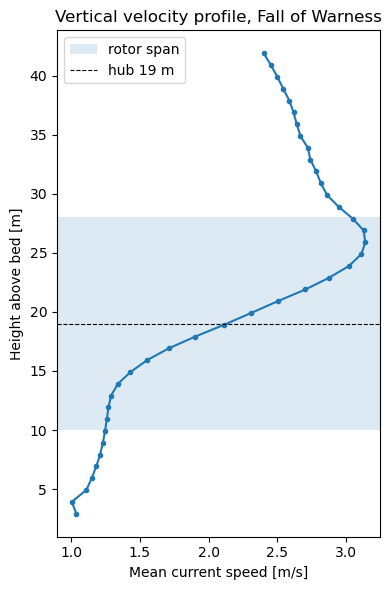

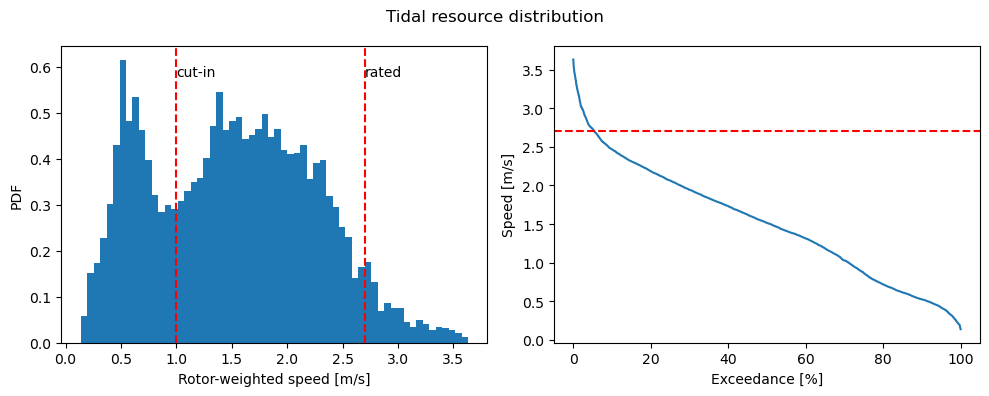

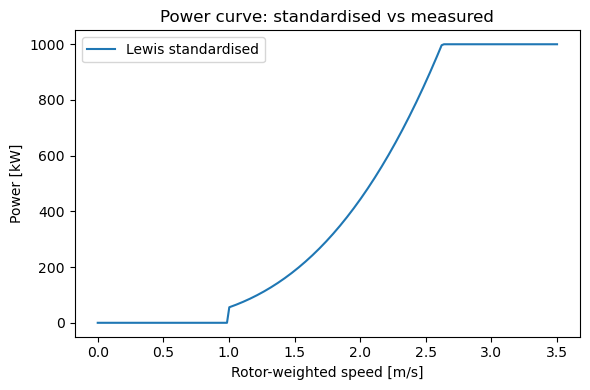

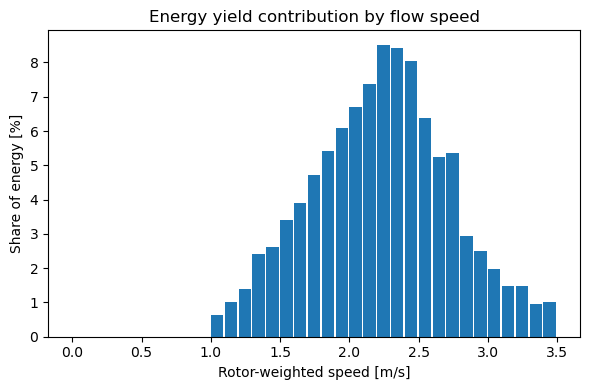

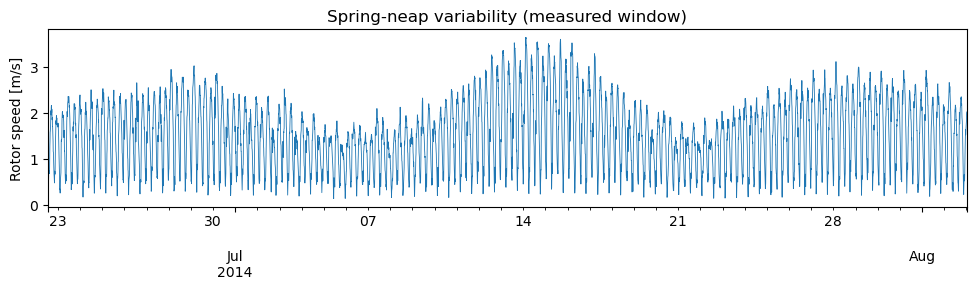

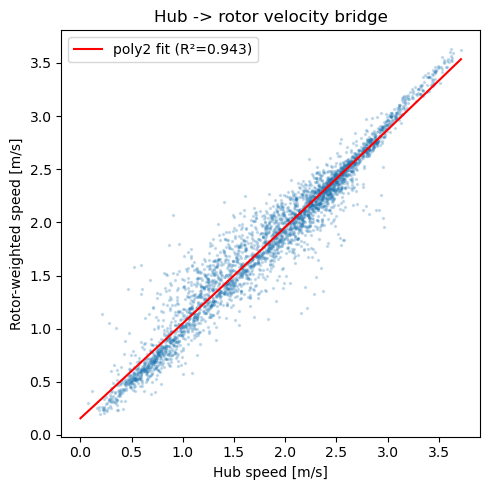

In [9]:
"""
============================================================================
ReDAPT / EMEC Fall of Warness  --  Tidal resource & load-factor pipeline
Starter script (run inside VS Code, stage by stage).

UPDATED after the full variable dump:
  * QC variable names are camelCase in the .nc -> the FULL QARTOD suite is
    present (signalStrength, correlation, percentGood, velocityLimits,
    errorVelocity, echoIntensity, velocityGradient, rocTilts, deployDepth).
    No need to touch the .mat files.
  * VALIDATION GATE now compares LINEAR means (hub-bin & depth-averaged) to
    MD6.1 -- like-for-like. The cube-weighted rotor velocity is kept ONLY for
    the power calculation (because P ~ U^3, the cube-mean is NOT comparable to
    a published "mean current").
  * Rotor cube-weighting now normalises by VALID (non-NaN) bin area per step.
  * diagnose() decomposes the resource so the ~18% gap can be pinned to a
    definition (slack inclusion / reference height) rather than guessed at.

REQUIREMENTS (pip): numpy pandas matplotlib xarray netCDF4 scipy h5py utide
============================================================================
"""

from pathlib import Path
import numpy as np
import pandas as pd

TYPE_A_DIR = Path(r"C:\Users\Steven Tarigan\Tidal dissertation\Download\Field-Measurements PPA Type A")
TYPE_B_DIR = Path(r"C:\Users\Steven Tarigan\Tidal dissertation\Download\Field-Measurements PPA Type B")

# --- CONFIRMED .nc variable names (camelCase) ------------------------------
VARS = dict(
    time="times", u="vel_geo_east", v="vel_geo_north", w="vel_geo_vert",
    pressure="pressure", head_hab="head_hab", bin_dist="bin_dist",
    bin_size="bin_size", num_bins="num_bins", beam_angle="beam_angle",
)
QC_2D = ["qc_signalStrength", "qc_correlation", "qc_percentGood",
         "qc_velocityLimits", "qc_errorVelocity", "qc_echoIntensity",
         "qc_velocityGradient"]            # per-bin flags -> NaN the bin
QC_ROW = ["qc_rocTilts", "qc_deployDepth"]  # per-record flags -> drop the step
QC_PASS = (1, 2)                            # keep 1 (pass) & 2 (not evaluated)
VMAX = 5.0
SLACK = 1.0                                  # m/s, MC7.1 slack threshold

TURBINE = dict(name="DEEP-Gen IV", rated_power_kW=1000.0, rated_speed=2.70, cut_in=1.00,
               rotor_diameter=18.08, capture_area=256.74, hub_above_bed=19.0, cp_max=0.42)
HUB, RROT = TURBINE["hub_above_bed"], TURBINE["rotor_diameter"] / 2.0
SITE_BENCHMARK = dict(mean_current=1.804, mean_flood=1.701, mean_ebb=1.896,
                      mean_spring_peak=3.079, mean_neap_peak=1.744,
                      flood_dir_deg=137.0, ebb_dir_deg=331.0,
                      rho_seawater=1027.0, published_load_factor=0.342)


# ===========================================================================
# STAGE 0  --  DISCOVER + INSPECT
# ===========================================================================
def discover(d: Path):
    nc, mat = sorted(d.rglob("*.nc")), sorted(d.rglob("*.mat"))
    print(f"  {d.name}: {len(nc)} .nc, {len(mat)} .mat")
    return nc, mat


def inspect_netcdf(p: Path):
    import xarray as xr
    ds = xr.open_dataset(p)
    print(f"\n=== {p.name} ===  DIMS {dict(ds.sizes)}")
    print("ALL VARS:", list(ds.variables))
    return ds


def stage0():
    for d in (TYPE_A_DIR, TYPE_B_DIR):
        nc, _ = discover(d)
        if nc:
            inspect_netcdf(nc[0])


# ===========================================================================
# HELPERS
# ===========================================================================
def geometry(ds):
    g = lambda k: float(np.asarray(ds[VARS[k]]).ravel()[0])
    hab, b0, bsz, nb = g("head_hab"), g("bin_dist"), g("bin_size"), int(g("num_bins"))
    beam = g("beam_angle") if VARS["beam_angle"] in ds.variables else 20.0
    z = hab + b0 + np.arange(nb) * bsz          # bin-centre height above bed [m]
    return z, bsz, hab, beam


def select_nc(d: Path, instrument: str):
    return sorted(d.rglob(f"*{instrument}*.nc"))


def qc_masks(ds):
    """Return (bad2d [time,nbins], droprow [time]) from QARTOD flags present."""
    bad2d, droprow = None, None
    for name in QC_2D:
        if name in ds.variables:
            b = ~np.isin(ds[name].values, QC_PASS)
            bad2d = b if bad2d is None else (bad2d | b)
    for name in QC_ROW:
        if name in ds.variables:
            f = ds[name].values
            r = ~np.isin(f, QC_PASS)
            r = r.any(axis=1) if r.ndim == 2 else r      # rocTilts is [time,ndof]
            droprow = r if droprow is None else (droprow | r)
    return bad2d, droprow


# ===========================================================================
# STAGE 1-3 : per-file QC + multiple velocity statistics (memory-safe)
# ===========================================================================
def process_deployment(nc_paths, vmax=VMAX):
    import xarray as xr
    pieces = []
    prof_sum = prof_cnt = None
    z = bsz = beam = hab = None
    for p in sorted(nc_paths):
        ds = xr.open_dataset(p)
        if z is None:
            z, bsz, hab, beam = geometry(ds)
            prof_sum, prof_cnt = np.zeros(len(z)), np.zeros(len(z))
        u = ds[VARS["u"]].values.astype(float)
        v = ds[VARS["v"]].values.astype(float)
        # --- QC ---
        bad2d, droprow = qc_masks(ds)
        if bad2d is not None:
            u, v = np.where(bad2d, np.nan, u), np.where(bad2d, np.nan, v)
        spd = np.hypot(u, v)
        u, v = np.where(spd > vmax, np.nan, u), np.where(spd > vmax, np.nan, v)
        spd = np.hypot(u, v)
        # surface side-lobe mask for depth-avg (rotor band is unaffected)
        pr = ds[VARS["pressure"]].values.astype(float)
        clean_max = hab + pr * np.cos(np.radians(beam))         # [time]
        surf_bad = z[None, :] > clean_max[:, None]
        spd_davg = np.where(surf_bad, np.nan, spd)
        # rows to drop (deploy/recovery, tilts) + pressure fallback
        keep = pr > 0.5 * np.nanmedian(pr)
        if droprow is not None:
            keep &= ~droprow
        # --- profile accumulation (linear mean speed per bin) ---
        prof_sum += np.nansum(np.where(keep[:, None], spd, np.nan), axis=0)
        prof_cnt += np.sum(keep[:, None] & np.isfinite(spd), axis=0)
        # --- rotor cube-weighted velocity (valid-area normalised) ---
        within = (z >= HUB - RROT) & (z <= HUB + RROT)
        chord = 2.0 * np.sqrt(np.clip(RROT**2 - (z[within] - HUB) ** 2, 0, None))
        Ak = (chord * bsz)[None, :]
        Uw = spd[:, within]
        valid = np.isfinite(Uw)
        num = np.nansum((Uw ** 3) * Ak, axis=1)
        den = np.nansum(np.where(valid, Ak, 0.0), axis=1)
        U_rotor = np.where(den > 0, (num / den) ** (1 / 3), np.nan)
        # --- hub-bin linear velocity (for gate + harmonics) ---
        hub_i = int(np.argmin(np.abs(z - HUB)))
        u_hub, v_hub = u[:, hub_i], v[:, hub_i]
        U_hub = np.hypot(u_hub, v_hub)
        drc = (np.degrees(np.arctan2(u_hub, v_hub)) + 360) % 360
        # --- depth-averaged linear speed (surface-masked) ---
        U_davg = np.nanmean(spd_davg, axis=1)

        t = pd.to_datetime(ds[VARS["time"]].values)
        df = pd.DataFrame(dict(U_rotor=U_rotor, U_hub=U_hub, U_davg=U_davg,
                               u_hub=u_hub, v_hub=v_hub, dir=drc), index=t)[keep]
        pieces.append(df)
        ds.close()

    out = pd.concat(pieces).sort_index()
    out = out[~out.index.duplicated(keep="first")]
    profile = pd.Series(prof_sum / np.where(prof_cnt > 0, prof_cnt, np.nan),
                        index=np.round(z, 2), name="mean_speed")
    return out, profile


# ===========================================================================
# STAGE 4  --  RESOURCE SUMMARY + VALIDATION GATE (linear, like-for-like)
# ===========================================================================
def direction_is_flood(d, flood_dir=SITE_BENCHMARK["flood_dir_deg"], window=90):
    return np.abs((d - flood_dir + 180) % 360 - 180) <= window


def resource_summary(df):
    f = direction_is_flood(df["dir"].values)
    hub = df["U_hub"].values
    flow = hub > SLACK                          # non-slack mask
    print("\nVALIDATION GATE -- LINEAR means vs MD6.1 (like-for-like):")
    print(f"  hub mean (all)      : {np.nanmean(hub):.3f}   (published mean 1.804)")
    print(f"  hub mean (non-slack): {np.nanmean(hub[flow]):.3f}")
    print(f"  depth-avg mean (all): {np.nanmean(df['U_davg']):.3f}")
    print(f"  hub flood (non-slack): {np.nanmean(hub[f & flow]):.3f}  (published 1.701)")
    print(f"  hub ebb   (non-slack): {np.nanmean(hub[~f & flow]):.3f}  (published 1.896)")
    print(f"  hub p95 / max       : {np.nanpercentile(hub,95):.3f} / {np.nanmax(hub):.3f}"
          f"   (spring peak 3.079)")
    print(f"  rotor cube-mean(all): {np.nanmean(df['U_rotor']):.3f}   <-- for POWER, not gate")


def diagnose(df, profile):
    print("\nVERTICAL PROFILE (linear mean speed per bin height above bed):")
    for z, s in profile.items():
        if np.isfinite(s):
            bar = "#" * int(s * 20)
            mark = "  <- hub 19 m" if abs(z - HUB) < 0.6 else ""
            print(f"  {z:5.1f} m : {s:5.3f} {bar}{mark}")
    print(f"\n  slack fraction (U_hub<{SLACK}): "
          f"{np.mean(df['U_hub'].values < SLACK):.1%}")


# ===========================================================================
# STAGE 5  --  HARMONIC ANALYSIS + ANNUAL RECONSTRUCTION (uTide)
# ===========================================================================
def harmonic_reconstruct(df10, lat=59.137, target_year=None):
    """Fit tidal harmonics to 10-min hub u,v and reconstruct a representative
    year.  CRITICAL: trend=False -- a secular linear trend fitted to ~44 days
    and then extrapolated years ahead is what blew the reconstruction up
    (LF=1.0). The nodal correction (nodal=True) handles long-period modulation
    properly without extrapolating a spurious trend."""
    import utide
    m = df10[["u_hub", "v_hub"]].dropna()
    coef = utide.solve(m.index, m["u_hub"].values, m["v_hub"].values,
                       lat=lat, method="ols", trend=False, nodal=True,
                       conf_int="none", verbose=False)
    # reconstruct a full year STARTING at the data start (no multi-year extrapolation)
    start = m.index[0].normalize() if target_year is None else pd.Timestamp(f"{target_year}-01-01")
    t_year = pd.date_range(start, start + pd.Timedelta(days=365), freq="10min", inclusive="left")
    rec = utide.reconstruct(t_year, coef, verbose=False)
    return t_year, rec["u"], rec["v"], np.hypot(rec["u"], rec["v"]), coef


def fit_rotor_from_hub(df10):
    """Data-driven bridge: U_rotor ~ poly2(U_hub), learned from the measured
    concurrent data. Returns (poly, R2). Lets us map a reconstructed hub series
    to the rotor power-weighted velocity that the MC7.1 curve expects."""
    m = df10[["U_hub", "U_rotor"]].dropna()
    x, y = m["U_hub"].values, m["U_rotor"].values
    c = np.polyfit(x, y, 2)
    p = np.poly1d(c)
    ss_res = np.sum((y - p(x)) ** 2)
    ss_tot = np.sum((y - y.mean()) ** 2)
    return p, 1 - ss_res / ss_tot


def period_load_factor(df10, curve="lewis", measured_csv=None):
    """PRIMARY validated LF: computed DIRECTLY from the measured ~44-day rotor
    velocity (no reconstruction). The window spans ~3 spring-neap cycles, so the
    period mean is a sound capacity-factor estimate. Robust -- no uTide."""
    U = df10["U_rotor"].dropna().values
    P = (load_measured_curve(measured_csv)(U) if curve == "measured"
         else lewis_power_curve(U, cut_in=TURBINE["cut_in"]))
    lf = load_factor(P)
    print(f"  PERIOD LOAD FACTOR ({curve}, measured 44 d): {lf:.3f}   "
          f"(ReDAPT estimate 0.342)")
    return lf


def annual_load_factor(df10, lat=59.137, year=None, curve="lewis", measured_csv=None):
    """REFINEMENT: harmonics -> representative-year hub series -> rotor bridge
    -> power -> LF. Clamps the bridge input to the observed range and reports
    reconstruction stats so a bad fit is obvious."""
    bridge, r2 = fit_rotor_from_hub(df10)
    print(f"  hub->rotor bridge R^2 = {r2:.3f}")
    _, _, _, Uhub_yr, _ = harmonic_reconstruct(df10, lat, year)
    print(f"  reconstructed hub speed  min/mean/max = "
          f"{np.nanmin(Uhub_yr):.2f}/{np.nanmean(Uhub_yr):.2f}/{np.nanmax(Uhub_yr):.2f} m/s")
    if np.nanmax(Uhub_yr) > 6:
        print("  !! reconstruction implausibly high -- check uTide (trend/time base)")
    # clamp to the observed hub range before applying the bridge (no extrapolation)
    lo, hi = df10["U_hub"].quantile([0.0, 0.999]).values
    Urotor_yr = np.clip(bridge(np.clip(Uhub_yr, lo, hi)), 0, None)
    P = (load_measured_curve(measured_csv)(Urotor_yr) if curve == "measured"
         else lewis_power_curve(Urotor_yr, cut_in=TURBINE["cut_in"]))
    lf = load_factor(P)
    print(f"  ANNUAL LOAD FACTOR ({curve}): {lf:.3f}   (ReDAPT estimate 0.342)")
    return lf, Urotor_yr, P


# ===========================================================================
# STAGE 6  --  POWER CURVES + LOAD FACTOR
# ===========================================================================
def lewis_power_curve(u, Vr=TURBINE["rated_speed"], Pr=TURBINE["rated_power_kW"],
                      cut_in=None, cut_in_frac=0.30, cp=TURBINE["cp_max"],
                      area=TURBINE["capture_area"], rho=SITE_BENCHMARK["rho_seawater"]):
    """Lewis (2021) normalised curve scaled to a device. `cut_in` (absolute m/s)
    overrides cut_in_frac*Vr -- use 1.0 for DEEP-Gen IV (MC7.1), 0.30*Vr generic."""
    u = np.asarray(u, float)
    ci = cut_in if cut_in is not None else cut_in_frac * Vr
    p = 0.5 * rho * area * cp * u**3 / 1000.0
    p = np.where(u < ci, 0.0, p)
    return np.minimum(p, Pr)


def load_measured_curve(csv_path):
    tbl = pd.read_csv(csv_path).sort_values("v_centre")
    v, p = tbl["v_centre"].values, tbl["mean_power_kW"].values
    def curve(u):
        u = np.asarray(u, float)
        out = np.interp(u, v, p, left=0.0, right=TURBINE["rated_power_kW"])
        return np.where(u < TURBINE["cut_in"], 0.0, out)
    return curve


def load_factor(power_kW, rated_kW=TURBINE["rated_power_kW"]):
    return np.nanmean(power_kW) / rated_kW


# ===========================================================================
# STAGE 7  --  MONTE-CARLO UNCERTAINTY
# ===========================================================================
def monte_carlo_lf(speed_series, n=2000):
    rng = np.random.default_rng(42)
    lfs = []
    for _ in range(n):
        p = lewis_power_curve(speed_series, Vr=TURBINE["rated_speed"] + rng.normal(0, 0.05))
        lfs.append(load_factor(p) * rng.uniform(0.85, 0.98))
    return np.array(lfs)


# ===========================================================================
# STAGE 8  --  FIGURES (the ones that earn marks)
# ===========================================================================
def make_figures(df10, profile, measured_csv=None, outdir="figs"):
    import matplotlib.pyplot as plt
    Path(outdir).mkdir(exist_ok=True)
    U = df10["U_rotor"].dropna().values

    # Fig 1: vertical velocity profile (the shear -- a key site finding)
    prof = profile[profile.index <= 42]            # drop side-lobe-contaminated bins
    fig, ax = plt.subplots(figsize=(4, 6))
    ax.plot(prof.values, prof.index, "-o", ms=3)
    ax.axhspan(HUB - RROT, HUB + RROT, alpha=0.15, label="rotor span")
    ax.axhline(HUB, ls="--", c="k", lw=0.8, label="hub 19 m")
    ax.set_xlabel("Mean current speed [m/s]"); ax.set_ylabel("Height above bed [m]")
    ax.set_title("Vertical velocity profile, Fall of Warness"); ax.legend()
    fig.tight_layout(); fig.savefig(f"{outdir}/01_vertical_profile.png", dpi=150)

    # Fig 2: velocity distribution + exceedance, with cut-in & rated marked
    fig, ax = plt.subplots(1, 2, figsize=(10, 4))
    ax[0].hist(U, bins=60, density=True)
    for x, lab in [(TURBINE["cut_in"], "cut-in"), (TURBINE["rated_speed"], "rated")]:
        ax[0].axvline(x, ls="--", c="r"); ax[0].text(x, ax[0].get_ylim()[1]*0.9, lab)
    ax[0].set_xlabel("Rotor-weighted speed [m/s]"); ax[0].set_ylabel("PDF")
    s = np.sort(U)[::-1]; exc = np.arange(1, len(s)+1)/len(s)*100
    ax[1].plot(exc, s); ax[1].set_xlabel("Exceedance [%]"); ax[1].set_ylabel("Speed [m/s]")
    ax[1].axhline(TURBINE["rated_speed"], ls="--", c="r")
    fig.suptitle("Tidal resource distribution"); fig.tight_layout()
    fig.savefig(f"{outdir}/02_resource_distribution.png", dpi=150)

    # Fig 3: power-curve comparison (Lewis standardised vs MC7.1 measured)
    uu = np.linspace(0, 3.5, 200)
    fig, ax = plt.subplots(figsize=(6, 4))
    ax.plot(uu, lewis_power_curve(uu, cut_in=TURBINE["cut_in"]), label="Lewis standardised")
    if measured_csv:
        ax.plot(uu, load_measured_curve(measured_csv)(uu), label="MC7.1 measured")
    ax.set_xlabel("Rotor-weighted speed [m/s]"); ax.set_ylabel("Power [kW]")
    ax.set_title("Power curve: standardised vs measured"); ax.legend()
    fig.tight_layout(); fig.savefig(f"{outdir}/03_power_curves.png", dpi=150)

    # Fig 4: energy yield contribution by speed bin (where the energy comes from)
    bins = np.arange(0, 3.6, 0.1); idx = np.digitize(U, bins)
    P = lewis_power_curve(U, cut_in=TURBINE["cut_in"])
    energy = np.array([P[idx == k].sum() for k in range(1, len(bins))])
    fig, ax = plt.subplots(figsize=(6, 4))
    ax.bar(bins[:-1], energy / energy.sum() * 100, width=0.09, align="edge")
    ax.set_xlabel("Rotor-weighted speed [m/s]"); ax.set_ylabel("Share of energy [%]")
    ax.set_title("Energy yield contribution by flow speed")
    fig.tight_layout(); fig.savefig(f"{outdir}/04_energy_by_speed.png", dpi=150)

    # Fig 5: spring-neap time series (coverage + variability)
    fig, ax = plt.subplots(figsize=(10, 3))
    df10["U_rotor"].plot(ax=ax, lw=0.6)
    ax.set_ylabel("Rotor speed [m/s]"); ax.set_title("Spring-neap variability (measured window)")
    fig.tight_layout(); fig.savefig(f"{outdir}/05_springneap_timeseries.png", dpi=150)

    # Fig 6: hub->rotor bridge scatter with fit (methodological transparency)
    bridge, r2 = fit_rotor_from_hub(df10)
    fig, ax = plt.subplots(figsize=(5, 5))
    ax.scatter(df10["U_hub"], df10["U_rotor"], s=2, alpha=0.2)
    xx = np.linspace(0, df10["U_hub"].max(), 100)
    ax.plot(xx, bridge(xx), "r-", label=f"poly2 fit (R²={r2:.3f})")
    ax.set_xlabel("Hub speed [m/s]"); ax.set_ylabel("Rotor-weighted speed [m/s]")
    ax.set_title("Hub -> rotor velocity bridge"); ax.legend()
    fig.tight_layout(); fig.savefig(f"{outdir}/06_bridge.png", dpi=150)

    print(f"  figures saved to ./{outdir}/")
    plt.show()


# ===========================================================================
def demo_resource(measured_csv=None):
    files = select_nc(TYPE_A_DIR, "ADCP01_NW_Dep5")
    print(f"ADCP01_NW_Dep5: {len(files)} daily .nc files")
    df, profile = process_deployment(files)
    df10 = df.resample("10min").mean()
    resource_summary(df10)
    diagnose(df10, profile)
    print("\nSTAGE 6: load factor")
    period_load_factor(df10, curve="lewis", measured_csv=measured_csv)   # primary
    annual_load_factor(df10, curve="lewis", measured_csv=measured_csv)   # refinement
    print("\nSTAGE 8: figures")
    make_figures(df10, profile, measured_csv=measured_csv)
    return df10, profile


if __name__ == "__main__":
    # stage0()
    df10, profile = demo_resource()   # add measured_csv="mc71_curve.csv" once transcribed

ADCP01_NW_Dep5: 46 daily .nc files


C:\Users\Steven Tarigan\AppData\Local\Temp\ipykernel_36172\464212077.py:150: RuntimeWarning: invalid value encountered in divide
  U_rotor = np.where(den > 0, (num / den) ** (1 / 3), np.nan)
C:\Users\Steven Tarigan\AppData\Local\Temp\ipykernel_36172\464212077.py:157: RuntimeWarning: Mean of empty slice
  U_davg = np.nanmean(spd_davg, axis=1)
C:\Users\Steven Tarigan\AppData\Local\Temp\ipykernel_36172\464212077.py:150: RuntimeWarning: invalid value encountered in divide
  U_rotor = np.where(den > 0, (num / den) ** (1 / 3), np.nan)
C:\Users\Steven Tarigan\AppData\Local\Temp\ipykernel_36172\464212077.py:157: RuntimeWarning: Mean of empty slice
  U_davg = np.nanmean(spd_davg, axis=1)
C:\Users\Steven Tarigan\AppData\Local\Temp\ipykernel_36172\464212077.py:150: RuntimeWarning: invalid value encountered in divide
  U_rotor = np.where(den > 0, (num / den) ** (1 / 3), np.nan)
C:\Users\Steven Tarigan\AppData\Local\Temp\ipykernel_36172\464212077.py:157: RuntimeWarning: Mean of empty slice
  U_davg


VALIDATION GATE -- LINEAR means vs MD6.1 (like-for-like):
  hub mean (all)      : 1.843   (published mean 1.804)
  hub mean (non-slack): 2.103
  depth-avg mean (all): 1.398
  hub flood (non-slack): 2.066  (published 1.701)
  hub ebb   (non-slack): 2.130  (published 1.896)
  hub p95 / max       : 2.990 / 3.718   (spring peak 3.079)
  rotor cube-mean(all): 1.511   <-- for POWER, not gate

VERTICAL PROFILE (linear mean speed per bin height above bed):
    2.9 m : 1.038 ####################
    3.9 m : 1.003 ####################
    4.9 m : 1.109 ######################
    5.9 m : 1.149 ######################
    6.9 m : 1.182 #######################
    7.9 m : 1.210 ########################
    8.9 m : 1.230 ########################
    9.9 m : 1.246 ########################
   10.9 m : 1.259 #########################
   11.9 m : 1.271 #########################
   12.9 m : 1.290 #########################
   13.9 m : 1.340 ##########################
   14.9 m : 1.431 ####################

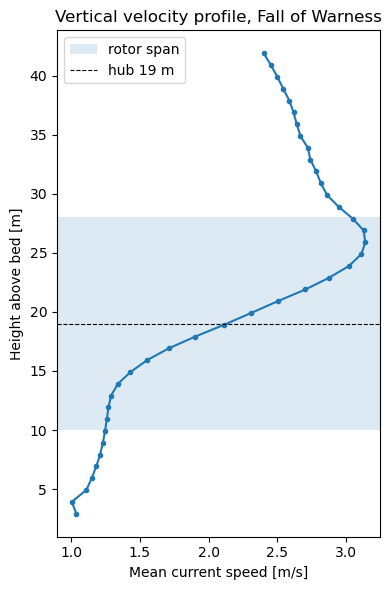

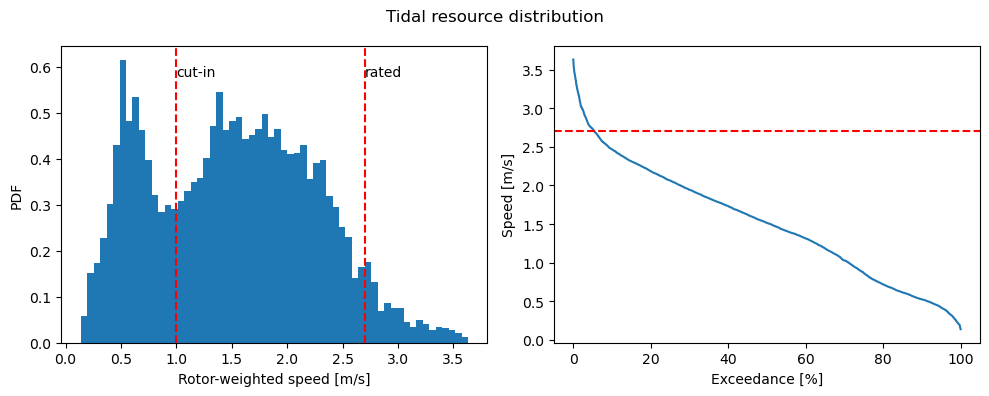

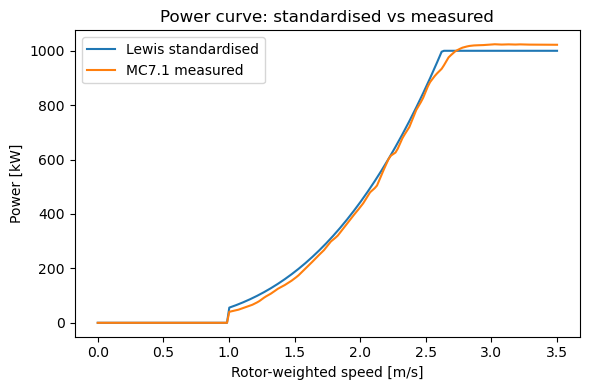

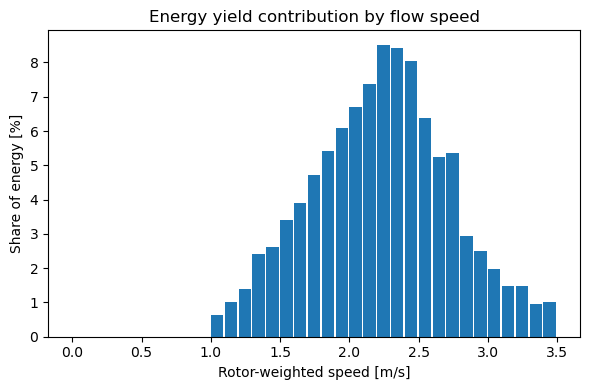

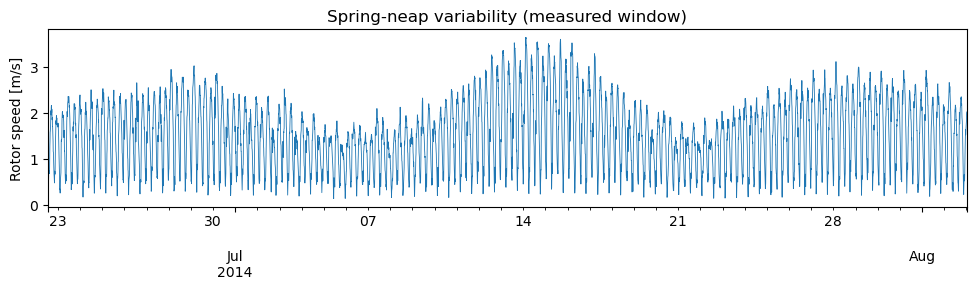

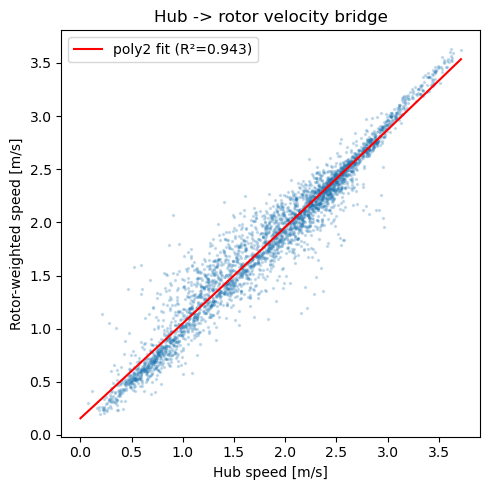

In [10]:
"""
============================================================================
ReDAPT / EMEC Fall of Warness  --  Tidal resource & load-factor pipeline
Starter script (run inside VS Code, stage by stage).

UPDATED after the full variable dump:
  * QC variable names are camelCase in the .nc -> the FULL QARTOD suite is
    present (signalStrength, correlation, percentGood, velocityLimits,
    errorVelocity, echoIntensity, velocityGradient, rocTilts, deployDepth).
    No need to touch the .mat files.
  * VALIDATION GATE now compares LINEAR means (hub-bin & depth-averaged) to
    MD6.1 -- like-for-like. The cube-weighted rotor velocity is kept ONLY for
    the power calculation (because P ~ U^3, the cube-mean is NOT comparable to
    a published "mean current").
  * Rotor cube-weighting now normalises by VALID (non-NaN) bin area per step.
  * diagnose() decomposes the resource so the ~18% gap can be pinned to a
    definition (slack inclusion / reference height) rather than guessed at.

REQUIREMENTS (pip): numpy pandas matplotlib xarray netCDF4 scipy h5py utide
============================================================================
"""

from pathlib import Path
import numpy as np
import pandas as pd

TYPE_A_DIR = Path(r"C:\Users\Steven Tarigan\Tidal dissertation\Download\Field-Measurements PPA Type A")
TYPE_B_DIR = Path(r"C:\Users\Steven Tarigan\Tidal dissertation\Download\Field-Measurements PPA Type B")

# --- CONFIRMED .nc variable names (camelCase) ------------------------------
VARS = dict(
    time="times", u="vel_geo_east", v="vel_geo_north", w="vel_geo_vert",
    pressure="pressure", head_hab="head_hab", bin_dist="bin_dist",
    bin_size="bin_size", num_bins="num_bins", beam_angle="beam_angle",
)
QC_2D = ["qc_signalStrength", "qc_correlation", "qc_percentGood",
         "qc_velocityLimits", "qc_errorVelocity", "qc_echoIntensity",
         "qc_velocityGradient"]            # per-bin flags -> NaN the bin
QC_ROW = ["qc_rocTilts", "qc_deployDepth"]  # per-record flags -> drop the step
QC_PASS = (1, 2)                            # keep 1 (pass) & 2 (not evaluated)
VMAX = 5.0
SLACK = 1.0                                  # m/s, MC7.1 slack threshold

TURBINE = dict(name="DEEP-Gen IV", rated_power_kW=1000.0, rated_speed=2.70, cut_in=1.00,
               rotor_diameter=18.08, capture_area=256.74, hub_above_bed=19.0, cp_max=0.42)
HUB, RROT = TURBINE["hub_above_bed"], TURBINE["rotor_diameter"] / 2.0
SITE_BENCHMARK = dict(mean_current=1.804, mean_flood=1.701, mean_ebb=1.896,
                      mean_spring_peak=3.079, mean_neap_peak=1.744,
                      flood_dir_deg=137.0, ebb_dir_deg=331.0,
                      rho_seawater=1027.0, published_load_factor=0.342)


# ===========================================================================
# STAGE 0  --  DISCOVER + INSPECT
# ===========================================================================
def discover(d: Path):
    nc, mat = sorted(d.rglob("*.nc")), sorted(d.rglob("*.mat"))
    print(f"  {d.name}: {len(nc)} .nc, {len(mat)} .mat")
    return nc, mat


def inspect_netcdf(p: Path):
    import xarray as xr
    ds = xr.open_dataset(p)
    print(f"\n=== {p.name} ===  DIMS {dict(ds.sizes)}")
    print("ALL VARS:", list(ds.variables))
    return ds


def stage0():
    for d in (TYPE_A_DIR, TYPE_B_DIR):
        nc, _ = discover(d)
        if nc:
            inspect_netcdf(nc[0])


# ===========================================================================
# HELPERS
# ===========================================================================
def geometry(ds):
    g = lambda k: float(np.asarray(ds[VARS[k]]).ravel()[0])
    hab, b0, bsz, nb = g("head_hab"), g("bin_dist"), g("bin_size"), int(g("num_bins"))
    beam = g("beam_angle") if VARS["beam_angle"] in ds.variables else 20.0
    z = hab + b0 + np.arange(nb) * bsz          # bin-centre height above bed [m]
    return z, bsz, hab, beam


def select_nc(d: Path, instrument: str):
    return sorted(d.rglob(f"*{instrument}*.nc"))


def qc_masks(ds):
    """Return (bad2d [time,nbins], droprow [time]) from QARTOD flags present."""
    bad2d, droprow = None, None
    for name in QC_2D:
        if name in ds.variables:
            b = ~np.isin(ds[name].values, QC_PASS)
            bad2d = b if bad2d is None else (bad2d | b)
    for name in QC_ROW:
        if name in ds.variables:
            f = ds[name].values
            r = ~np.isin(f, QC_PASS)
            r = r.any(axis=1) if r.ndim == 2 else r      # rocTilts is [time,ndof]
            droprow = r if droprow is None else (droprow | r)
    return bad2d, droprow


# ===========================================================================
# STAGE 1-3 : per-file QC + multiple velocity statistics (memory-safe)
# ===========================================================================
def process_deployment(nc_paths, vmax=VMAX):
    import xarray as xr
    pieces = []
    prof_sum = prof_cnt = None
    z = bsz = beam = hab = None
    for p in sorted(nc_paths):
        ds = xr.open_dataset(p)
        if z is None:
            z, bsz, hab, beam = geometry(ds)
            prof_sum, prof_cnt = np.zeros(len(z)), np.zeros(len(z))
        u = ds[VARS["u"]].values.astype(float)
        v = ds[VARS["v"]].values.astype(float)
        # --- QC ---
        bad2d, droprow = qc_masks(ds)
        if bad2d is not None:
            u, v = np.where(bad2d, np.nan, u), np.where(bad2d, np.nan, v)
        spd = np.hypot(u, v)
        u, v = np.where(spd > vmax, np.nan, u), np.where(spd > vmax, np.nan, v)
        spd = np.hypot(u, v)
        # surface side-lobe mask for depth-avg (rotor band is unaffected)
        pr = ds[VARS["pressure"]].values.astype(float)
        clean_max = hab + pr * np.cos(np.radians(beam))         # [time]
        surf_bad = z[None, :] > clean_max[:, None]
        spd_davg = np.where(surf_bad, np.nan, spd)
        # rows to drop (deploy/recovery, tilts) + pressure fallback
        keep = pr > 0.5 * np.nanmedian(pr)
        if droprow is not None:
            keep &= ~droprow
        # --- profile accumulation (linear mean speed per bin) ---
        prof_sum += np.nansum(np.where(keep[:, None], spd, np.nan), axis=0)
        prof_cnt += np.sum(keep[:, None] & np.isfinite(spd), axis=0)
        # --- rotor cube-weighted velocity (valid-area normalised) ---
        within = (z >= HUB - RROT) & (z <= HUB + RROT)
        chord = 2.0 * np.sqrt(np.clip(RROT**2 - (z[within] - HUB) ** 2, 0, None))
        Ak = (chord * bsz)[None, :]
        Uw = spd[:, within]
        valid = np.isfinite(Uw)
        num = np.nansum((Uw ** 3) * Ak, axis=1)
        den = np.nansum(np.where(valid, Ak, 0.0), axis=1)
        U_rotor = np.where(den > 0, (num / den) ** (1 / 3), np.nan)
        # --- hub-bin linear velocity (for gate + harmonics) ---
        hub_i = int(np.argmin(np.abs(z - HUB)))
        u_hub, v_hub = u[:, hub_i], v[:, hub_i]
        U_hub = np.hypot(u_hub, v_hub)
        drc = (np.degrees(np.arctan2(u_hub, v_hub)) + 360) % 360
        # --- depth-averaged linear speed (surface-masked) ---
        U_davg = np.nanmean(spd_davg, axis=1)

        t = pd.to_datetime(ds[VARS["time"]].values)
        df = pd.DataFrame(dict(U_rotor=U_rotor, U_hub=U_hub, U_davg=U_davg,
                               u_hub=u_hub, v_hub=v_hub, dir=drc), index=t)[keep]
        pieces.append(df)
        ds.close()

    out = pd.concat(pieces).sort_index()
    out = out[~out.index.duplicated(keep="first")]
    profile = pd.Series(prof_sum / np.where(prof_cnt > 0, prof_cnt, np.nan),
                        index=np.round(z, 2), name="mean_speed")
    return out, profile


# ===========================================================================
# STAGE 4  --  RESOURCE SUMMARY + VALIDATION GATE (linear, like-for-like)
# ===========================================================================
def direction_is_flood(d, flood_dir=SITE_BENCHMARK["flood_dir_deg"], window=90):
    return np.abs((d - flood_dir + 180) % 360 - 180) <= window


def resource_summary(df):
    f = direction_is_flood(df["dir"].values)
    hub = df["U_hub"].values
    flow = hub > SLACK                          # non-slack mask
    print("\nVALIDATION GATE -- LINEAR means vs MD6.1 (like-for-like):")
    print(f"  hub mean (all)      : {np.nanmean(hub):.3f}   (published mean 1.804)")
    print(f"  hub mean (non-slack): {np.nanmean(hub[flow]):.3f}")
    print(f"  depth-avg mean (all): {np.nanmean(df['U_davg']):.3f}")
    print(f"  hub flood (non-slack): {np.nanmean(hub[f & flow]):.3f}  (published 1.701)")
    print(f"  hub ebb   (non-slack): {np.nanmean(hub[~f & flow]):.3f}  (published 1.896)")
    print(f"  hub p95 / max       : {np.nanpercentile(hub,95):.3f} / {np.nanmax(hub):.3f}"
          f"   (spring peak 3.079)")
    print(f"  rotor cube-mean(all): {np.nanmean(df['U_rotor']):.3f}   <-- for POWER, not gate")


def diagnose(df, profile):
    print("\nVERTICAL PROFILE (linear mean speed per bin height above bed):")
    for z, s in profile.items():
        if np.isfinite(s):
            bar = "#" * int(s * 20)
            mark = "  <- hub 19 m" if abs(z - HUB) < 0.6 else ""
            print(f"  {z:5.1f} m : {s:5.3f} {bar}{mark}")
    print(f"\n  slack fraction (U_hub<{SLACK}): "
          f"{np.mean(df['U_hub'].values < SLACK):.1%}")


# ===========================================================================
# STAGE 5  --  HARMONIC ANALYSIS + ANNUAL RECONSTRUCTION (uTide)
# ===========================================================================
def harmonic_reconstruct(df10, lat=59.137, target_year=None):
    """Fit tidal harmonics to 10-min hub u,v and reconstruct a representative
    year.  CRITICAL: trend=False -- a secular linear trend fitted to ~44 days
    and then extrapolated years ahead is what blew the reconstruction up
    (LF=1.0). The nodal correction (nodal=True) handles long-period modulation
    properly without extrapolating a spurious trend."""
    import utide
    m = df10[["u_hub", "v_hub"]].dropna()
    coef = utide.solve(m.index, m["u_hub"].values, m["v_hub"].values,
                       lat=lat, method="ols", trend=False, nodal=True,
                       conf_int="none", verbose=False)
    # reconstruct a full year STARTING at the data start (no multi-year extrapolation)
    start = m.index[0].normalize() if target_year is None else pd.Timestamp(f"{target_year}-01-01")
    t_year = pd.date_range(start, start + pd.Timedelta(days=365), freq="10min", inclusive="left")
    rec = utide.reconstruct(t_year, coef, verbose=False)
    return t_year, rec["u"], rec["v"], np.hypot(rec["u"], rec["v"]), coef


def fit_rotor_from_hub(df10):
    """Data-driven bridge: U_rotor ~ poly2(U_hub), learned from the measured
    concurrent data. Returns (poly, R2). Lets us map a reconstructed hub series
    to the rotor power-weighted velocity that the MC7.1 curve expects."""
    m = df10[["U_hub", "U_rotor"]].dropna()
    x, y = m["U_hub"].values, m["U_rotor"].values
    c = np.polyfit(x, y, 2)
    p = np.poly1d(c)
    ss_res = np.sum((y - p(x)) ** 2)
    ss_tot = np.sum((y - y.mean()) ** 2)
    return p, 1 - ss_res / ss_tot


def period_load_factor(df10, curve="lewis", measured_csv=None):
    """PRIMARY validated LF: computed DIRECTLY from the measured ~44-day rotor
    velocity (no reconstruction). The window spans ~3 spring-neap cycles, so the
    period mean is a sound capacity-factor estimate. Robust -- no uTide."""
    U = df10["U_rotor"].dropna().values
    P = (load_measured_curve(measured_csv)(U) if curve == "measured"
         else lewis_power_curve(U, cut_in=TURBINE["cut_in"]))
    lf = load_factor(P)
    print(f"  PERIOD LOAD FACTOR ({curve}, measured 44 d): {lf:.3f}   "
          f"(ReDAPT estimate 0.342)")
    return lf


def annual_load_factor(df10, lat=59.137, year=None, curve="lewis", measured_csv=None):
    """REFINEMENT: harmonics -> representative-year hub series -> rotor bridge
    -> power -> LF. Clamps the bridge input to the observed range and reports
    reconstruction stats so a bad fit is obvious."""
    bridge, r2 = fit_rotor_from_hub(df10)
    print(f"  hub->rotor bridge R^2 = {r2:.3f}")
    _, _, _, Uhub_yr, _ = harmonic_reconstruct(df10, lat, year)
    print(f"  reconstructed hub speed  min/mean/max = "
          f"{np.nanmin(Uhub_yr):.2f}/{np.nanmean(Uhub_yr):.2f}/{np.nanmax(Uhub_yr):.2f} m/s")
    if np.nanmax(Uhub_yr) > 6:
        print("  !! reconstruction implausibly high -- check uTide (trend/time base)")
    # clamp to the observed hub range before applying the bridge (no extrapolation)
    lo, hi = df10["U_hub"].quantile([0.0, 0.999]).values
    Urotor_yr = np.clip(bridge(np.clip(Uhub_yr, lo, hi)), 0, None)
    P = (load_measured_curve(measured_csv)(Urotor_yr) if curve == "measured"
         else lewis_power_curve(Urotor_yr, cut_in=TURBINE["cut_in"]))
    lf = load_factor(P)
    print(f"  ANNUAL LOAD FACTOR ({curve}): {lf:.3f}   (ReDAPT estimate 0.342)")
    return lf, Urotor_yr, P


# ===========================================================================
# STAGE 6  --  POWER CURVES + LOAD FACTOR
# ===========================================================================
def lewis_power_curve(u, Vr=TURBINE["rated_speed"], Pr=TURBINE["rated_power_kW"],
                      cut_in=None, cut_in_frac=0.30, cp=TURBINE["cp_max"],
                      area=TURBINE["capture_area"], rho=SITE_BENCHMARK["rho_seawater"]):
    """Lewis (2021) normalised curve scaled to a device. `cut_in` (absolute m/s)
    overrides cut_in_frac*Vr -- use 1.0 for DEEP-Gen IV (MC7.1), 0.30*Vr generic."""
    u = np.asarray(u, float)
    ci = cut_in if cut_in is not None else cut_in_frac * Vr
    p = 0.5 * rho * area * cp * u**3 / 1000.0
    p = np.where(u < ci, 0.0, p)
    return np.minimum(p, Pr)


def load_measured_curve(csv_path):
    """Measured DEEP-Gen IV curve from MC7.1 Table 14-1 (count-weighted
    flood+ebb combination). CSV columns: v_centre, mean_power_kW.
    Above the last bin the curve plateaus at the measured value (~1022 kW,
    i.e. slightly above the 1 MW rating, as the real machine over-produces)."""
    tbl = pd.read_csv(csv_path).dropna(subset=["mean_power_kW"]).sort_values("v_centre")
    v, p = tbl["v_centre"].values, tbl["mean_power_kW"].values
    def curve(u):
        u = np.asarray(u, float)
        out = np.interp(u, v, p, left=0.0, right=p[-1])
        return np.where(u < TURBINE["cut_in"], 0.0, out)
    return curve


def load_factor(power_kW, rated_kW=TURBINE["rated_power_kW"]):
    return np.nanmean(power_kW) / rated_kW


# ===========================================================================
# STAGE 7  --  MONTE-CARLO UNCERTAINTY
# ===========================================================================
def monte_carlo_lf(speed_series, n=2000):
    rng = np.random.default_rng(42)
    lfs = []
    for _ in range(n):
        p = lewis_power_curve(speed_series, Vr=TURBINE["rated_speed"] + rng.normal(0, 0.05))
        lfs.append(load_factor(p) * rng.uniform(0.85, 0.98))
    return np.array(lfs)


# ===========================================================================
# STAGE 8  --  FIGURES (the ones that earn marks)
# ===========================================================================
def make_figures(df10, profile, measured_csv=None, outdir="figs"):
    import matplotlib.pyplot as plt
    Path(outdir).mkdir(exist_ok=True)
    U = df10["U_rotor"].dropna().values

    # Fig 1: vertical velocity profile (the shear -- a key site finding)
    prof = profile[profile.index <= 42]            # drop side-lobe-contaminated bins
    fig, ax = plt.subplots(figsize=(4, 6))
    ax.plot(prof.values, prof.index, "-o", ms=3)
    ax.axhspan(HUB - RROT, HUB + RROT, alpha=0.15, label="rotor span")
    ax.axhline(HUB, ls="--", c="k", lw=0.8, label="hub 19 m")
    ax.set_xlabel("Mean current speed [m/s]"); ax.set_ylabel("Height above bed [m]")
    ax.set_title("Vertical velocity profile, Fall of Warness"); ax.legend()
    fig.tight_layout(); fig.savefig(f"{outdir}/01_vertical_profile.png", dpi=150)

    # Fig 2: velocity distribution + exceedance, with cut-in & rated marked
    fig, ax = plt.subplots(1, 2, figsize=(10, 4))
    ax[0].hist(U, bins=60, density=True)
    for x, lab in [(TURBINE["cut_in"], "cut-in"), (TURBINE["rated_speed"], "rated")]:
        ax[0].axvline(x, ls="--", c="r"); ax[0].text(x, ax[0].get_ylim()[1]*0.9, lab)
    ax[0].set_xlabel("Rotor-weighted speed [m/s]"); ax[0].set_ylabel("PDF")
    s = np.sort(U)[::-1]; exc = np.arange(1, len(s)+1)/len(s)*100
    ax[1].plot(exc, s); ax[1].set_xlabel("Exceedance [%]"); ax[1].set_ylabel("Speed [m/s]")
    ax[1].axhline(TURBINE["rated_speed"], ls="--", c="r")
    fig.suptitle("Tidal resource distribution"); fig.tight_layout()
    fig.savefig(f"{outdir}/02_resource_distribution.png", dpi=150)

    # Fig 3: power-curve comparison (Lewis standardised vs MC7.1 measured)
    uu = np.linspace(0, 3.5, 200)
    fig, ax = plt.subplots(figsize=(6, 4))
    ax.plot(uu, lewis_power_curve(uu, cut_in=TURBINE["cut_in"]), label="Lewis standardised")
    if measured_csv:
        ax.plot(uu, load_measured_curve(measured_csv)(uu), label="MC7.1 measured")
    ax.set_xlabel("Rotor-weighted speed [m/s]"); ax.set_ylabel("Power [kW]")
    ax.set_title("Power curve: standardised vs measured"); ax.legend()
    fig.tight_layout(); fig.savefig(f"{outdir}/03_power_curves.png", dpi=150)

    # Fig 4: energy yield contribution by speed bin (where the energy comes from)
    bins = np.arange(0, 3.6, 0.1); idx = np.digitize(U, bins)
    P = lewis_power_curve(U, cut_in=TURBINE["cut_in"])
    energy = np.array([P[idx == k].sum() for k in range(1, len(bins))])
    fig, ax = plt.subplots(figsize=(6, 4))
    ax.bar(bins[:-1], energy / energy.sum() * 100, width=0.09, align="edge")
    ax.set_xlabel("Rotor-weighted speed [m/s]"); ax.set_ylabel("Share of energy [%]")
    ax.set_title("Energy yield contribution by flow speed")
    fig.tight_layout(); fig.savefig(f"{outdir}/04_energy_by_speed.png", dpi=150)

    # Fig 5: spring-neap time series (coverage + variability)
    fig, ax = plt.subplots(figsize=(10, 3))
    df10["U_rotor"].plot(ax=ax, lw=0.6)
    ax.set_ylabel("Rotor speed [m/s]"); ax.set_title("Spring-neap variability (measured window)")
    fig.tight_layout(); fig.savefig(f"{outdir}/05_springneap_timeseries.png", dpi=150)

    # Fig 6: hub->rotor bridge scatter with fit (methodological transparency)
    bridge, r2 = fit_rotor_from_hub(df10)
    fig, ax = plt.subplots(figsize=(5, 5))
    ax.scatter(df10["U_hub"], df10["U_rotor"], s=2, alpha=0.2)
    xx = np.linspace(0, df10["U_hub"].max(), 100)
    ax.plot(xx, bridge(xx), "r-", label=f"poly2 fit (R²={r2:.3f})")
    ax.set_xlabel("Hub speed [m/s]"); ax.set_ylabel("Rotor-weighted speed [m/s]")
    ax.set_title("Hub -> rotor velocity bridge"); ax.legend()
    fig.tight_layout(); fig.savefig(f"{outdir}/06_bridge.png", dpi=150)

    print(f"  figures saved to ./{outdir}/")
    plt.show()


# ===========================================================================
def demo_resource(measured_csv="redapt_mc71_power_curve.csv"):
    files = select_nc(TYPE_A_DIR, "ADCP01_NW_Dep5")
    print(f"ADCP01_NW_Dep5: {len(files)} daily .nc files")
    df, profile = process_deployment(files)
    df10 = df.resample("10min").mean()
    resource_summary(df10)
    diagnose(df10, profile)
    print("\nSTAGE 6: load factor  (Lewis standardised vs MC7.1 measured)")
    period_load_factor(df10, curve="lewis")
    annual_load_factor(df10, curve="lewis")
    if measured_csv and Path(measured_csv).exists():
        period_load_factor(df10, curve="measured", measured_csv=measured_csv)
        annual_load_factor(df10, curve="measured", measured_csv=measured_csv)
    else:
        print("  (measured curve skipped -- redapt_mc71_power_curve.csv not found)")
    print("\nSTAGE 8: figures")
    make_figures(df10, profile, measured_csv=measured_csv)
    return df10, profile


if __name__ == "__main__":
    # stage0()
    df10, profile = demo_resource()

ADCP01_NW_Dep5: 89 daily .nc files


C:\Users\Steven Tarigan\AppData\Local\Temp\ipykernel_36172\2768674837.py:150: RuntimeWarning: invalid value encountered in divide
  U_rotor = np.where(den > 0, (num / den) ** (1 / 3), np.nan)
C:\Users\Steven Tarigan\AppData\Local\Temp\ipykernel_36172\2768674837.py:157: RuntimeWarning: Mean of empty slice
  U_davg = np.nanmean(spd_davg, axis=1)
C:\Users\Steven Tarigan\AppData\Local\Temp\ipykernel_36172\2768674837.py:150: RuntimeWarning: invalid value encountered in divide
  U_rotor = np.where(den > 0, (num / den) ** (1 / 3), np.nan)
C:\Users\Steven Tarigan\AppData\Local\Temp\ipykernel_36172\2768674837.py:157: RuntimeWarning: Mean of empty slice
  U_davg = np.nanmean(spd_davg, axis=1)
C:\Users\Steven Tarigan\AppData\Local\Temp\ipykernel_36172\2768674837.py:150: RuntimeWarning: invalid value encountered in divide
  U_rotor = np.where(den > 0, (num / den) ** (1 / 3), np.nan)
C:\Users\Steven Tarigan\AppData\Local\Temp\ipykernel_36172\2768674837.py:157: RuntimeWarning: Mean of empty slice
  


VALIDATION GATE -- LINEAR means vs MD6.1 (like-for-like):
  hub mean (all)      : 2.215   (published mean 1.804)
  hub mean (non-slack): 2.441
  depth-avg mean (all): 1.474
  hub flood (non-slack): 2.330  (published 1.701)
  hub ebb   (non-slack): 2.507  (published 1.896)
  hub p95 / max       : 3.218 / 3.923   (spring peak 3.079)
  rotor cube-mean(all): 1.644   <-- for POWER, not gate

VERTICAL PROFILE (linear mean speed per bin height above bed):
    2.9 m : 1.194 #######################
    3.9 m : 1.219 ########################
    4.9 m : 1.309 ##########################
    5.9 m : 1.345 ##########################
    6.9 m : 1.374 ###########################
    7.9 m : 1.402 ############################
    8.9 m : 1.443 ############################
    9.9 m : 1.514 ##############################
   10.9 m : 1.584 ###############################
   11.9 m : 1.656 #################################
   12.9 m : 1.729 ##################################
   13.9 m : 1.812 #########

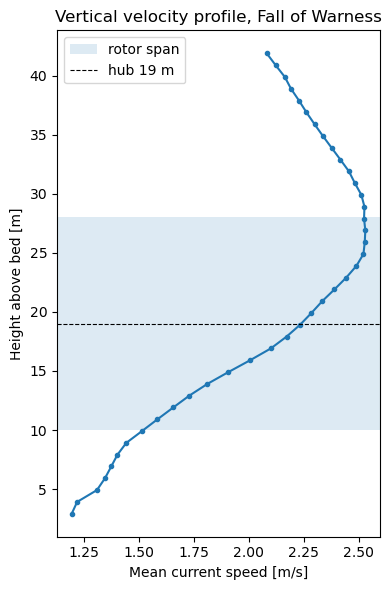

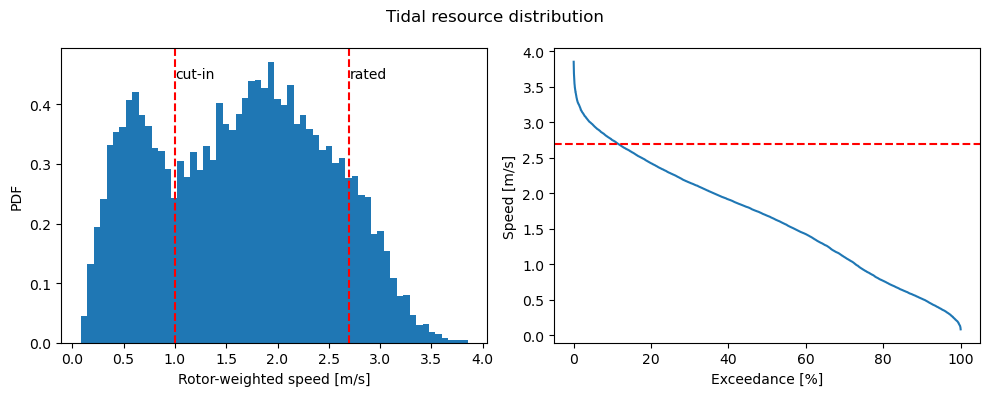

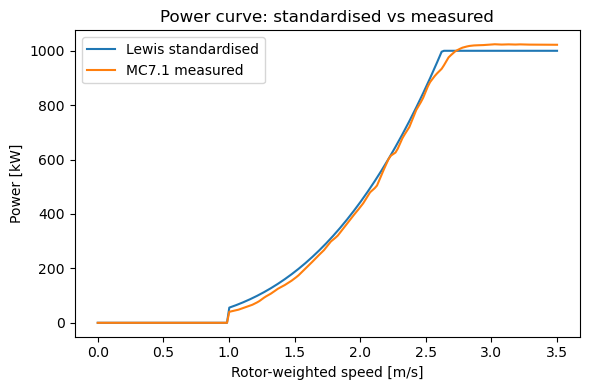

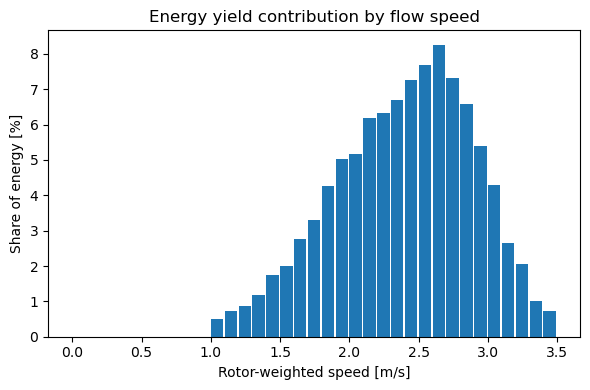

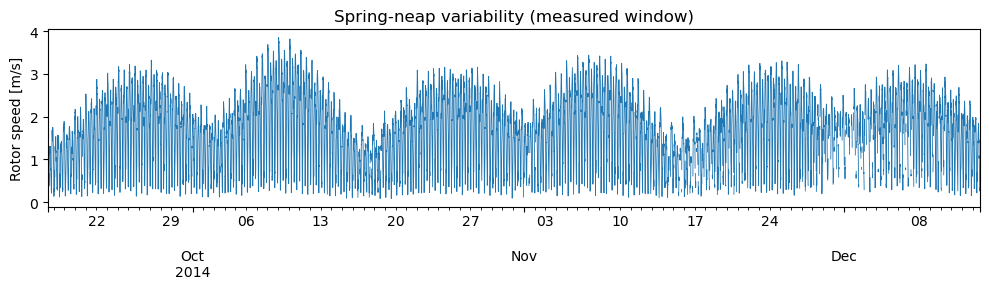

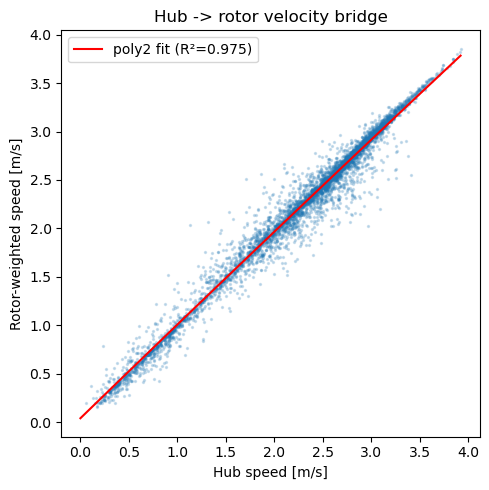

In [11]:
"""
============================================================================
ReDAPT / EMEC Fall of Warness  --  Tidal resource & load-factor pipeline
Starter script (run inside VS Code, stage by stage).

UPDATED after the full variable dump:
  * QC variable names are camelCase in the .nc -> the FULL QARTOD suite is
    present (signalStrength, correlation, percentGood, velocityLimits,
    errorVelocity, echoIntensity, velocityGradient, rocTilts, deployDepth).
    No need to touch the .mat files.
  * VALIDATION GATE now compares LINEAR means (hub-bin & depth-averaged) to
    MD6.1 -- like-for-like. The cube-weighted rotor velocity is kept ONLY for
    the power calculation (because P ~ U^3, the cube-mean is NOT comparable to
    a published "mean current").
  * Rotor cube-weighting now normalises by VALID (non-NaN) bin area per step.
  * diagnose() decomposes the resource so the ~18% gap can be pinned to a
    definition (slack inclusion / reference height) rather than guessed at.

REQUIREMENTS (pip): numpy pandas matplotlib xarray netCDF4 scipy h5py utide
============================================================================
"""

from pathlib import Path
import numpy as np
import pandas as pd

TYPE_A_DIR = Path(r"C:\Users\Steven Tarigan\Tidal dissertation\Download\Field-Measurements PPA Type A")
TYPE_B_DIR = Path(r"C:\Users\Steven Tarigan\Tidal dissertation\Download\Field-Measurements PPA Type B")

# --- CONFIRMED .nc variable names (camelCase) ------------------------------
VARS = dict(
    time="times", u="vel_geo_east", v="vel_geo_north", w="vel_geo_vert",
    pressure="pressure", head_hab="head_hab", bin_dist="bin_dist",
    bin_size="bin_size", num_bins="num_bins", beam_angle="beam_angle",
)
QC_2D = ["qc_signalStrength", "qc_correlation", "qc_percentGood",
         "qc_velocityLimits", "qc_errorVelocity", "qc_echoIntensity",
         "qc_velocityGradient"]            # per-bin flags -> NaN the bin
QC_ROW = ["qc_rocTilts", "qc_deployDepth"]  # per-record flags -> drop the step
QC_PASS = (1, 2)                            # keep 1 (pass) & 2 (not evaluated)
VMAX = 5.0
SLACK = 1.0                                  # m/s, MC7.1 slack threshold

TURBINE = dict(name="DEEP-Gen IV", rated_power_kW=1000.0, rated_speed=2.70, cut_in=1.00,
               rotor_diameter=18.08, capture_area=256.74, hub_above_bed=19.0, cp_max=0.42)
HUB, RROT = TURBINE["hub_above_bed"], TURBINE["rotor_diameter"] / 2.0
SITE_BENCHMARK = dict(mean_current=1.804, mean_flood=1.701, mean_ebb=1.896,
                      mean_spring_peak=3.079, mean_neap_peak=1.744,
                      flood_dir_deg=137.0, ebb_dir_deg=331.0,
                      rho_seawater=1027.0, published_load_factor=0.342)


# ===========================================================================
# STAGE 0  --  DISCOVER + INSPECT
# ===========================================================================
def discover(d: Path):
    nc, mat = sorted(d.rglob("*.nc")), sorted(d.rglob("*.mat"))
    print(f"  {d.name}: {len(nc)} .nc, {len(mat)} .mat")
    return nc, mat


def inspect_netcdf(p: Path):
    import xarray as xr
    ds = xr.open_dataset(p)
    print(f"\n=== {p.name} ===  DIMS {dict(ds.sizes)}")
    print("ALL VARS:", list(ds.variables))
    return ds


def stage0():
    for d in (TYPE_A_DIR, TYPE_B_DIR):
        nc, _ = discover(d)
        if nc:
            inspect_netcdf(nc[0])


# ===========================================================================
# HELPERS
# ===========================================================================
def geometry(ds):
    g = lambda k: float(np.asarray(ds[VARS[k]]).ravel()[0])
    hab, b0, bsz, nb = g("head_hab"), g("bin_dist"), g("bin_size"), int(g("num_bins"))
    beam = g("beam_angle") if VARS["beam_angle"] in ds.variables else 20.0
    z = hab + b0 + np.arange(nb) * bsz          # bin-centre height above bed [m]
    return z, bsz, hab, beam


def select_nc(d: Path, instrument: str):
    return sorted(d.rglob(f"*{instrument}*.nc"))


def qc_masks(ds):
    """Return (bad2d [time,nbins], droprow [time]) from QARTOD flags present."""
    bad2d, droprow = None, None
    for name in QC_2D:
        if name in ds.variables:
            b = ~np.isin(ds[name].values, QC_PASS)
            bad2d = b if bad2d is None else (bad2d | b)
    for name in QC_ROW:
        if name in ds.variables:
            f = ds[name].values
            r = ~np.isin(f, QC_PASS)
            r = r.any(axis=1) if r.ndim == 2 else r      # rocTilts is [time,ndof]
            droprow = r if droprow is None else (droprow | r)
    return bad2d, droprow


# ===========================================================================
# STAGE 1-3 : per-file QC + multiple velocity statistics (memory-safe)
# ===========================================================================
def process_deployment(nc_paths, vmax=VMAX):
    import xarray as xr
    pieces = []
    prof_sum = prof_cnt = None
    z = bsz = beam = hab = None
    for p in sorted(nc_paths):
        ds = xr.open_dataset(p)
        if z is None:
            z, bsz, hab, beam = geometry(ds)
            prof_sum, prof_cnt = np.zeros(len(z)), np.zeros(len(z))
        u = ds[VARS["u"]].values.astype(float)
        v = ds[VARS["v"]].values.astype(float)
        # --- QC ---
        bad2d, droprow = qc_masks(ds)
        if bad2d is not None:
            u, v = np.where(bad2d, np.nan, u), np.where(bad2d, np.nan, v)
        spd = np.hypot(u, v)
        u, v = np.where(spd > vmax, np.nan, u), np.where(spd > vmax, np.nan, v)
        spd = np.hypot(u, v)
        # surface side-lobe mask for depth-avg (rotor band is unaffected)
        pr = ds[VARS["pressure"]].values.astype(float)
        clean_max = hab + pr * np.cos(np.radians(beam))         # [time]
        surf_bad = z[None, :] > clean_max[:, None]
        spd_davg = np.where(surf_bad, np.nan, spd)
        # rows to drop (deploy/recovery, tilts) + pressure fallback
        keep = pr > 0.5 * np.nanmedian(pr)
        if droprow is not None:
            keep &= ~droprow
        # --- profile accumulation (linear mean speed per bin) ---
        prof_sum += np.nansum(np.where(keep[:, None], spd, np.nan), axis=0)
        prof_cnt += np.sum(keep[:, None] & np.isfinite(spd), axis=0)
        # --- rotor cube-weighted velocity (valid-area normalised) ---
        within = (z >= HUB - RROT) & (z <= HUB + RROT)
        chord = 2.0 * np.sqrt(np.clip(RROT**2 - (z[within] - HUB) ** 2, 0, None))
        Ak = (chord * bsz)[None, :]
        Uw = spd[:, within]
        valid = np.isfinite(Uw)
        num = np.nansum((Uw ** 3) * Ak, axis=1)
        den = np.nansum(np.where(valid, Ak, 0.0), axis=1)
        U_rotor = np.where(den > 0, (num / den) ** (1 / 3), np.nan)
        # --- hub-bin linear velocity (for gate + harmonics) ---
        hub_i = int(np.argmin(np.abs(z - HUB)))
        u_hub, v_hub = u[:, hub_i], v[:, hub_i]
        U_hub = np.hypot(u_hub, v_hub)
        drc = (np.degrees(np.arctan2(u_hub, v_hub)) + 360) % 360
        # --- depth-averaged linear speed (surface-masked) ---
        U_davg = np.nanmean(spd_davg, axis=1)

        t = pd.to_datetime(ds[VARS["time"]].values)
        df = pd.DataFrame(dict(U_rotor=U_rotor, U_hub=U_hub, U_davg=U_davg,
                               u_hub=u_hub, v_hub=v_hub, dir=drc), index=t)[keep]
        pieces.append(df)
        ds.close()

    out = pd.concat(pieces).sort_index()
    out = out[~out.index.duplicated(keep="first")]
    profile = pd.Series(prof_sum / np.where(prof_cnt > 0, prof_cnt, np.nan),
                        index=np.round(z, 2), name="mean_speed")
    return out, profile


# ===========================================================================
# STAGE 4  --  RESOURCE SUMMARY + VALIDATION GATE (linear, like-for-like)
# ===========================================================================
def direction_is_flood(d, flood_dir=SITE_BENCHMARK["flood_dir_deg"], window=90):
    return np.abs((d - flood_dir + 180) % 360 - 180) <= window


def resource_summary(df):
    f = direction_is_flood(df["dir"].values)
    hub = df["U_hub"].values
    flow = hub > SLACK                          # non-slack mask
    print("\nVALIDATION GATE -- LINEAR means vs MD6.1 (like-for-like):")
    print(f"  hub mean (all)      : {np.nanmean(hub):.3f}   (published mean 1.804)")
    print(f"  hub mean (non-slack): {np.nanmean(hub[flow]):.3f}")
    print(f"  depth-avg mean (all): {np.nanmean(df['U_davg']):.3f}")
    print(f"  hub flood (non-slack): {np.nanmean(hub[f & flow]):.3f}  (published 1.701)")
    print(f"  hub ebb   (non-slack): {np.nanmean(hub[~f & flow]):.3f}  (published 1.896)")
    print(f"  hub p95 / max       : {np.nanpercentile(hub,95):.3f} / {np.nanmax(hub):.3f}"
          f"   (spring peak 3.079)")
    print(f"  rotor cube-mean(all): {np.nanmean(df['U_rotor']):.3f}   <-- for POWER, not gate")


def diagnose(df, profile):
    print("\nVERTICAL PROFILE (linear mean speed per bin height above bed):")
    for z, s in profile.items():
        if np.isfinite(s):
            bar = "#" * int(s * 20)
            mark = "  <- hub 19 m" if abs(z - HUB) < 0.6 else ""
            print(f"  {z:5.1f} m : {s:5.3f} {bar}{mark}")
    print(f"\n  slack fraction (U_hub<{SLACK}): "
          f"{np.mean(df['U_hub'].values < SLACK):.1%}")


# ===========================================================================
# STAGE 5  --  HARMONIC ANALYSIS + ANNUAL RECONSTRUCTION (uTide)
# ===========================================================================
def harmonic_reconstruct(df10, lat=59.137, target_year=None):
    """Fit tidal harmonics to 10-min hub u,v and reconstruct a representative
    year.  CRITICAL: trend=False -- a secular linear trend fitted to ~44 days
    and then extrapolated years ahead is what blew the reconstruction up
    (LF=1.0). The nodal correction (nodal=True) handles long-period modulation
    properly without extrapolating a spurious trend."""
    import utide
    m = df10[["u_hub", "v_hub"]].dropna()
    coef = utide.solve(m.index, m["u_hub"].values, m["v_hub"].values,
                       lat=lat, method="ols", trend=False, nodal=True,
                       conf_int="none", verbose=False)
    # reconstruct a full year STARTING at the data start (no multi-year extrapolation)
    start = m.index[0].normalize() if target_year is None else pd.Timestamp(f"{target_year}-01-01")
    t_year = pd.date_range(start, start + pd.Timedelta(days=365), freq="10min", inclusive="left")
    rec = utide.reconstruct(t_year, coef, verbose=False)
    return t_year, rec["u"], rec["v"], np.hypot(rec["u"], rec["v"]), coef


def fit_rotor_from_hub(df10):
    """Data-driven bridge: U_rotor ~ poly2(U_hub), learned from the measured
    concurrent data. Returns (poly, R2). Lets us map a reconstructed hub series
    to the rotor power-weighted velocity that the MC7.1 curve expects."""
    m = df10[["U_hub", "U_rotor"]].dropna()
    x, y = m["U_hub"].values, m["U_rotor"].values
    c = np.polyfit(x, y, 2)
    p = np.poly1d(c)
    ss_res = np.sum((y - p(x)) ** 2)
    ss_tot = np.sum((y - y.mean()) ** 2)
    return p, 1 - ss_res / ss_tot


def period_load_factor(df10, curve="lewis", measured_csv=None):
    """PRIMARY validated LF: computed DIRECTLY from the measured ~44-day rotor
    velocity (no reconstruction). The window spans ~3 spring-neap cycles, so the
    period mean is a sound capacity-factor estimate. Robust -- no uTide."""
    U = df10["U_rotor"].dropna().values
    P = (load_measured_curve(measured_csv)(U) if curve == "measured"
         else lewis_power_curve(U, cut_in=TURBINE["cut_in"]))
    lf = load_factor(P)
    print(f"  PERIOD LOAD FACTOR ({curve}, measured 44 d): {lf:.3f}   "
          f"(ReDAPT estimate 0.342)")
    return lf


def annual_load_factor(df10, lat=59.137, year=None, curve="lewis", measured_csv=None):
    """REFINEMENT: harmonics -> representative-year hub series -> rotor bridge
    -> power -> LF. Clamps the bridge input to the observed range and reports
    reconstruction stats so a bad fit is obvious."""
    bridge, r2 = fit_rotor_from_hub(df10)
    print(f"  hub->rotor bridge R^2 = {r2:.3f}")
    _, _, _, Uhub_yr, _ = harmonic_reconstruct(df10, lat, year)
    print(f"  reconstructed hub speed  min/mean/max = "
          f"{np.nanmin(Uhub_yr):.2f}/{np.nanmean(Uhub_yr):.2f}/{np.nanmax(Uhub_yr):.2f} m/s")
    if np.nanmax(Uhub_yr) > 6:
        print("  !! reconstruction implausibly high -- check uTide (trend/time base)")
    # clamp to the observed hub range before applying the bridge (no extrapolation)
    lo, hi = df10["U_hub"].quantile([0.0, 0.999]).values
    Urotor_yr = np.clip(bridge(np.clip(Uhub_yr, lo, hi)), 0, None)
    P = (load_measured_curve(measured_csv)(Urotor_yr) if curve == "measured"
         else lewis_power_curve(Urotor_yr, cut_in=TURBINE["cut_in"]))
    lf = load_factor(P)
    print(f"  ANNUAL LOAD FACTOR ({curve}): {lf:.3f}   (ReDAPT estimate 0.342)")
    return lf, Urotor_yr, P


# ===========================================================================
# STAGE 6  --  POWER CURVES + LOAD FACTOR
# ===========================================================================
def lewis_power_curve(u, Vr=TURBINE["rated_speed"], Pr=TURBINE["rated_power_kW"],
                      cut_in=None, cut_in_frac=0.30, cp=TURBINE["cp_max"],
                      area=TURBINE["capture_area"], rho=SITE_BENCHMARK["rho_seawater"]):
    """Lewis (2021) normalised curve scaled to a device. `cut_in` (absolute m/s)
    overrides cut_in_frac*Vr -- use 1.0 for DEEP-Gen IV (MC7.1), 0.30*Vr generic."""
    u = np.asarray(u, float)
    ci = cut_in if cut_in is not None else cut_in_frac * Vr
    p = 0.5 * rho * area * cp * u**3 / 1000.0
    p = np.where(u < ci, 0.0, p)
    return np.minimum(p, Pr)


def load_measured_curve(csv_path):
    """Measured DEEP-Gen IV curve from MC7.1 Table 14-1 (count-weighted
    flood+ebb combination). CSV columns: v_centre, mean_power_kW.
    Above the last bin the curve plateaus at the measured value (~1022 kW,
    i.e. slightly above the 1 MW rating, as the real machine over-produces)."""
    tbl = pd.read_csv(csv_path).dropna(subset=["mean_power_kW"]).sort_values("v_centre")
    v, p = tbl["v_centre"].values, tbl["mean_power_kW"].values
    def curve(u):
        u = np.asarray(u, float)
        out = np.interp(u, v, p, left=0.0, right=p[-1])
        return np.where(u < TURBINE["cut_in"], 0.0, out)
    return curve


def load_factor(power_kW, rated_kW=TURBINE["rated_power_kW"]):
    return np.nanmean(power_kW) / rated_kW


# ===========================================================================
# STAGE 7  --  MONTE-CARLO UNCERTAINTY
# ===========================================================================
def monte_carlo_lf(speed_series, n=2000):
    rng = np.random.default_rng(42)
    lfs = []
    for _ in range(n):
        p = lewis_power_curve(speed_series, Vr=TURBINE["rated_speed"] + rng.normal(0, 0.05))
        lfs.append(load_factor(p) * rng.uniform(0.85, 0.98))
    return np.array(lfs)


# ===========================================================================
# STAGE 8  --  FIGURES (the ones that earn marks)
# ===========================================================================
def make_figures(df10, profile, measured_csv=None, outdir="figs"):
    import matplotlib.pyplot as plt
    Path(outdir).mkdir(exist_ok=True)
    U = df10["U_rotor"].dropna().values

    # Fig 1: vertical velocity profile (the shear -- a key site finding)
    prof = profile[profile.index <= 42]            # drop side-lobe-contaminated bins
    fig, ax = plt.subplots(figsize=(4, 6))
    ax.plot(prof.values, prof.index, "-o", ms=3)
    ax.axhspan(HUB - RROT, HUB + RROT, alpha=0.15, label="rotor span")
    ax.axhline(HUB, ls="--", c="k", lw=0.8, label="hub 19 m")
    ax.set_xlabel("Mean current speed [m/s]"); ax.set_ylabel("Height above bed [m]")
    ax.set_title("Vertical velocity profile, Fall of Warness"); ax.legend()
    fig.tight_layout(); fig.savefig(f"{outdir}/01_vertical_profile.png", dpi=150)

    # Fig 2: velocity distribution + exceedance, with cut-in & rated marked
    fig, ax = plt.subplots(1, 2, figsize=(10, 4))
    ax[0].hist(U, bins=60, density=True)
    for x, lab in [(TURBINE["cut_in"], "cut-in"), (TURBINE["rated_speed"], "rated")]:
        ax[0].axvline(x, ls="--", c="r"); ax[0].text(x, ax[0].get_ylim()[1]*0.9, lab)
    ax[0].set_xlabel("Rotor-weighted speed [m/s]"); ax[0].set_ylabel("PDF")
    s = np.sort(U)[::-1]; exc = np.arange(1, len(s)+1)/len(s)*100
    ax[1].plot(exc, s); ax[1].set_xlabel("Exceedance [%]"); ax[1].set_ylabel("Speed [m/s]")
    ax[1].axhline(TURBINE["rated_speed"], ls="--", c="r")
    fig.suptitle("Tidal resource distribution"); fig.tight_layout()
    fig.savefig(f"{outdir}/02_resource_distribution.png", dpi=150)

    # Fig 3: power-curve comparison (Lewis standardised vs MC7.1 measured)
    uu = np.linspace(0, 3.5, 200)
    fig, ax = plt.subplots(figsize=(6, 4))
    ax.plot(uu, lewis_power_curve(uu, cut_in=TURBINE["cut_in"]), label="Lewis standardised")
    if measured_csv:
        ax.plot(uu, load_measured_curve(measured_csv)(uu), label="MC7.1 measured")
    ax.set_xlabel("Rotor-weighted speed [m/s]"); ax.set_ylabel("Power [kW]")
    ax.set_title("Power curve: standardised vs measured"); ax.legend()
    fig.tight_layout(); fig.savefig(f"{outdir}/03_power_curves.png", dpi=150)

    # Fig 4: energy yield contribution by speed bin (where the energy comes from)
    bins = np.arange(0, 3.6, 0.1); idx = np.digitize(U, bins)
    P = lewis_power_curve(U, cut_in=TURBINE["cut_in"])
    energy = np.array([P[idx == k].sum() for k in range(1, len(bins))])
    fig, ax = plt.subplots(figsize=(6, 4))
    ax.bar(bins[:-1], energy / energy.sum() * 100, width=0.09, align="edge")
    ax.set_xlabel("Rotor-weighted speed [m/s]"); ax.set_ylabel("Share of energy [%]")
    ax.set_title("Energy yield contribution by flow speed")
    fig.tight_layout(); fig.savefig(f"{outdir}/04_energy_by_speed.png", dpi=150)

    # Fig 5: spring-neap time series (coverage + variability)
    fig, ax = plt.subplots(figsize=(10, 3))
    df10["U_rotor"].plot(ax=ax, lw=0.6)
    ax.set_ylabel("Rotor speed [m/s]"); ax.set_title("Spring-neap variability (measured window)")
    fig.tight_layout(); fig.savefig(f"{outdir}/05_springneap_timeseries.png", dpi=150)

    # Fig 6: hub->rotor bridge scatter with fit (methodological transparency)
    bridge, r2 = fit_rotor_from_hub(df10)
    fig, ax = plt.subplots(figsize=(5, 5))
    ax.scatter(df10["U_hub"], df10["U_rotor"], s=2, alpha=0.2)
    xx = np.linspace(0, df10["U_hub"].max(), 100)
    ax.plot(xx, bridge(xx), "r-", label=f"poly2 fit (R²={r2:.3f})")
    ax.set_xlabel("Hub speed [m/s]"); ax.set_ylabel("Rotor-weighted speed [m/s]")
    ax.set_title("Hub -> rotor velocity bridge"); ax.legend()
    fig.tight_layout(); fig.savefig(f"{outdir}/06_bridge.png", dpi=150)

    print(f"  figures saved to ./{outdir}/")
    plt.show()


# ===========================================================================
def demo_resource(measured_csv="redapt_mc71_power_curve.csv"):
    files = select_nc(TYPE_B_DIR, "ADCPTD7_01_Dep1")
    print(f"ADCP01_NW_Dep5: {len(files)} daily .nc files")
    df, profile = process_deployment(files)
    df10 = df.resample("10min").mean()
    resource_summary(df10)
    diagnose(df10, profile)
    print("\nSTAGE 6: load factor  (Lewis standardised vs MC7.1 measured)")
    period_load_factor(df10, curve="lewis")
    annual_load_factor(df10, curve="lewis")
    if measured_csv and Path(measured_csv).exists():
        period_load_factor(df10, curve="measured", measured_csv=measured_csv)
        annual_load_factor(df10, curve="measured", measured_csv=measured_csv)
    else:
        print("  (measured curve skipped -- redapt_mc71_power_curve.csv not found)")
    print("\nSTAGE 8: figures")
    make_figures(df10, profile, measured_csv=measured_csv)
    return df10, profile


if __name__ == "__main__":
    # stage0()
    df10, profile = demo_resource()

In [15]:
"""
============================================================================
ReDAPT / EMEC Fall of Warness  --  Tidal resource & load-factor pipeline
Starter script (run inside VS Code, stage by stage).

UPDATED after the full variable dump:
  * QC variable names are camelCase in the .nc -> the FULL QARTOD suite is
    present (signalStrength, correlation, percentGood, velocityLimits,
    errorVelocity, echoIntensity, velocityGradient, rocTilts, deployDepth).
    No need to touch the .mat files.
  * VALIDATION GATE now compares LINEAR means (hub-bin & depth-averaged) to
    MD6.1 -- like-for-like. The cube-weighted rotor velocity is kept ONLY for
    the power calculation (because P ~ U^3, the cube-mean is NOT comparable to
    a published "mean current").
  * Rotor cube-weighting now normalises by VALID (non-NaN) bin area per step.
  * diagnose() decomposes the resource so the ~18% gap can be pinned to a
    definition (slack inclusion / reference height) rather than guessed at.

REQUIREMENTS (pip): numpy pandas matplotlib xarray netCDF4 scipy h5py utide
============================================================================
"""

from pathlib import Path
import numpy as np
import pandas as pd

TYPE_A_DIR = Path(r"C:\Users\Steven Tarigan\Tidal dissertation\Download\Field-Measurements PPA Type A")
TYPE_B_DIR = Path(r"C:\Users\Steven Tarigan\Tidal dissertation\Download\Field-Measurements PPA Type B")

# --- CONFIRMED .nc variable names (camelCase) ------------------------------
VARS = dict(
    time="times", u="vel_geo_east", v="vel_geo_north", w="vel_geo_vert",
    pressure="pressure", head_hab="head_hab", bin_dist="bin_dist",
    bin_size="bin_size", num_bins="num_bins", beam_angle="beam_angle",
)
QC_2D = ["qc_signalStrength", "qc_correlation", "qc_percentGood",
         "qc_velocityLimits", "qc_errorVelocity", "qc_echoIntensity",
         "qc_velocityGradient"]            # per-bin flags -> NaN the bin
QC_ROW = ["qc_rocTilts", "qc_deployDepth"]  # per-record flags -> drop the step
QC_PASS = (1, 2)                            # keep 1 (pass) & 2 (not evaluated)
VMAX = 5.0
SLACK = 1.0                                  # m/s, MC7.1 slack threshold

TURBINE = dict(name="DEEP-Gen IV", rated_power_kW=1000.0, rated_speed=2.70, cut_in=1.00,
               rotor_diameter=18.08, capture_area=256.74, hub_above_bed=19.0, cp_max=0.42)
HUB, RROT = TURBINE["hub_above_bed"], TURBINE["rotor_diameter"] / 2.0
SITE_BENCHMARK = dict(mean_current=1.804, mean_flood=1.701, mean_ebb=1.896,
                      mean_spring_peak=3.079, mean_neap_peak=1.744,
                      flood_dir_deg=137.0, ebb_dir_deg=331.0,
                      rho_seawater=1027.0, published_load_factor=0.342)


# ===========================================================================
# STAGE 0  --  DISCOVER + INSPECT
# ===========================================================================
def discover(d: Path):
    nc, mat = sorted(d.rglob("*.nc")), sorted(d.rglob("*.mat"))
    print(f"  {d.name}: {len(nc)} .nc, {len(mat)} .mat")
    return nc, mat


def inspect_netcdf(p: Path):
    import xarray as xr
    ds = xr.open_dataset(p)
    print(f"\n=== {p.name} ===  DIMS {dict(ds.sizes)}")
    print("ALL VARS:", list(ds.variables))
    return ds


def stage0():
    for d in (TYPE_A_DIR, TYPE_B_DIR):
        nc, _ = discover(d)
        if nc:
            inspect_netcdf(nc[0])


# ===========================================================================
# HELPERS
# ===========================================================================
def geometry(ds):
    g = lambda k: float(np.asarray(ds[VARS[k]]).ravel()[0])
    hab, b0, bsz, nb = g("head_hab"), g("bin_dist"), g("bin_size"), int(g("num_bins"))
    beam = g("beam_angle") if VARS["beam_angle"] in ds.variables else 20.0
    z = hab + b0 + np.arange(nb) * bsz          # bin-centre height above bed [m]
    return z, bsz, hab, beam


def select_nc(d: Path, instrument: str):
    return sorted(d.rglob(f"*{instrument}*.nc"))


def get_series(type_dir: Path, instrument: str, cache_dir="cache"):
    """Return (df10, profile) for one deployment, caching both to CSV so the
    heavy raw 1 Hz read happens only once. Delete the cache files to re-process."""
    Path(cache_dir).mkdir(exist_ok=True)
    fcsv = Path(cache_dir) / f"{instrument}_10min.csv"
    fprof = Path(cache_dir) / f"{instrument}_profile.csv"
    if fcsv.exists() and fprof.exists():
        print(f"  [cache] loading {instrument}")
        df10 = pd.read_csv(fcsv, index_col=0, parse_dates=True)
        profile = pd.read_csv(fprof, index_col="z_m")["mean_speed"]
        return df10, profile
    df, profile = process_deployment(select_nc(type_dir, instrument))
    df10 = df.resample("10min").mean()
    df10.to_csv(fcsv)
    profile.rename_axis("z_m").rename("mean_speed").to_csv(fprof)
    print(f"  [cache] saved {instrument}")
    return df10, profile


def qc_masks(ds):
    """Return (bad2d [time,nbins], droprow [time]) from QARTOD flags present."""
    bad2d, droprow = None, None
    for name in QC_2D:
        if name in ds.variables:
            b = ~np.isin(ds[name].values, QC_PASS)
            bad2d = b if bad2d is None else (bad2d | b)
    for name in QC_ROW:
        if name in ds.variables:
            f = ds[name].values
            r = ~np.isin(f, QC_PASS)
            r = r.any(axis=1) if r.ndim == 2 else r      # rocTilts is [time,ndof]
            droprow = r if droprow is None else (droprow | r)
    return bad2d, droprow


# ===========================================================================
# STAGE 1-3 : per-file QC + multiple velocity statistics (memory-safe)
# ===========================================================================
def process_deployment(nc_paths, vmax=VMAX):
    import xarray as xr
    pieces = []
    prof_sum = prof_cnt = None
    z = bsz = beam = hab = None
    paths = sorted(nc_paths)
    n = len(paths)
    print(f"  process_deployment: {n} files")
    for i, p in enumerate(paths):
        if i % 10 == 0:
            print(f"    ...{i}/{n}", flush=True)
        ds = xr.open_dataset(p)
        if z is None:
            z, bsz, hab, beam = geometry(ds)
            prof_sum, prof_cnt = np.zeros(len(z)), np.zeros(len(z))
        u = ds[VARS["u"]].values.astype(float)
        v = ds[VARS["v"]].values.astype(float)
        # --- QC ---
        bad2d, droprow = qc_masks(ds)
        if bad2d is not None:
            u, v = np.where(bad2d, np.nan, u), np.where(bad2d, np.nan, v)
        spd = np.hypot(u, v)
        u, v = np.where(spd > vmax, np.nan, u), np.where(spd > vmax, np.nan, v)
        spd = np.hypot(u, v)
        # surface side-lobe mask for depth-avg (rotor band is unaffected)
        pr = ds[VARS["pressure"]].values.astype(float)
        clean_max = hab + pr * np.cos(np.radians(beam))         # [time]
        surf_bad = z[None, :] > clean_max[:, None]
        spd_davg = np.where(surf_bad, np.nan, spd)
        # rows to drop (deploy/recovery, tilts) + pressure fallback
        keep = pr > 0.5 * np.nanmedian(pr)
        if droprow is not None:
            keep &= ~droprow
        # --- profile accumulation (linear mean speed per bin) ---
        prof_sum += np.nansum(np.where(keep[:, None], spd, np.nan), axis=0)
        prof_cnt += np.sum(keep[:, None] & np.isfinite(spd), axis=0)
        # --- rotor cube-weighted velocity (valid-area normalised) ---
        within = (z >= HUB - RROT) & (z <= HUB + RROT)
        chord = 2.0 * np.sqrt(np.clip(RROT**2 - (z[within] - HUB) ** 2, 0, None))
        Ak = (chord * bsz)[None, :]
        Uw = spd[:, within]
        valid = np.isfinite(Uw)
        num = np.nansum((Uw ** 3) * Ak, axis=1)
        den = np.nansum(np.where(valid, Ak, 0.0), axis=1)
        U_rotor = np.where(den > 0, (num / den) ** (1 / 3), np.nan)
        # --- hub-bin linear velocity (for gate + harmonics) ---
        hub_i = int(np.argmin(np.abs(z - HUB)))
        u_hub, v_hub = u[:, hub_i], v[:, hub_i]
        U_hub = np.hypot(u_hub, v_hub)
        drc = (np.degrees(np.arctan2(u_hub, v_hub)) + 360) % 360
        # --- depth-averaged linear speed (surface-masked) ---
        U_davg = np.nanmean(spd_davg, axis=1)

        t = pd.to_datetime(ds[VARS["time"]].values)
        df = pd.DataFrame(dict(U_rotor=U_rotor, U_hub=U_hub, U_davg=U_davg,
                               u_hub=u_hub, v_hub=v_hub, dir=drc), index=t)[keep]
        pieces.append(df)
        ds.close()

    out = pd.concat(pieces).sort_index()
    out = out[~out.index.duplicated(keep="first")]
    profile = pd.Series(prof_sum / np.where(prof_cnt > 0, prof_cnt, np.nan),
                        index=np.round(z, 2), name="mean_speed")
    return out, profile


# ===========================================================================
# STAGE 4  --  RESOURCE SUMMARY + VALIDATION GATE (linear, like-for-like)
# ===========================================================================
def direction_is_flood(d, flood_dir=SITE_BENCHMARK["flood_dir_deg"], window=90):
    return np.abs((d - flood_dir + 180) % 360 - 180) <= window


def resource_summary(df):
    f = direction_is_flood(df["dir"].values)
    hub = df["U_hub"].values
    flow = hub > SLACK                          # non-slack mask
    print("\nVALIDATION GATE -- LINEAR means vs MD6.1 (like-for-like):")
    print(f"  hub mean (all)      : {np.nanmean(hub):.3f}   (published mean 1.804)")
    print(f"  hub mean (non-slack): {np.nanmean(hub[flow]):.3f}")
    print(f"  depth-avg mean (all): {np.nanmean(df['U_davg']):.3f}")
    print(f"  hub flood (non-slack): {np.nanmean(hub[f & flow]):.3f}  (published 1.701)")
    print(f"  hub ebb   (non-slack): {np.nanmean(hub[~f & flow]):.3f}  (published 1.896)")
    print(f"  hub p95 / max       : {np.nanpercentile(hub,95):.3f} / {np.nanmax(hub):.3f}"
          f"   (spring peak 3.079)")
    print(f"  rotor cube-mean(all): {np.nanmean(df['U_rotor']):.3f}   <-- for POWER, not gate")


def diagnose(df, profile):
    print("\nVERTICAL PROFILE (linear mean speed per bin height above bed):")
    for z, s in profile.items():
        if np.isfinite(s):
            bar = "#" * int(s * 20)
            mark = "  <- hub 19 m" if abs(z - HUB) < 0.6 else ""
            print(f"  {z:5.1f} m : {s:5.3f} {bar}{mark}")
    print(f"\n  slack fraction (U_hub<{SLACK}): "
          f"{np.mean(df['U_hub'].values < SLACK):.1%}")


# ===========================================================================
# STAGE 5  --  HARMONIC ANALYSIS + ANNUAL RECONSTRUCTION (uTide)
# ===========================================================================
def harmonic_reconstruct(df10, lat=59.137, target_year=None):
    """Fit tidal harmonics to 10-min hub u,v and reconstruct a representative
    year.  CRITICAL: trend=False -- a secular linear trend fitted to ~44 days
    and then extrapolated years ahead is what blew the reconstruction up
    (LF=1.0). The nodal correction (nodal=True) handles long-period modulation
    properly without extrapolating a spurious trend."""
    import utide
    m = df10[["u_hub", "v_hub"]].dropna()
    coef = utide.solve(m.index, m["u_hub"].values, m["v_hub"].values,
                       lat=lat, method="ols", trend=False, nodal=True,
                       conf_int="none", verbose=False)
    # reconstruct a full year STARTING at the data start (no multi-year extrapolation)
    start = m.index[0].normalize() if target_year is None else pd.Timestamp(f"{target_year}-01-01")
    t_year = pd.date_range(start, start + pd.Timedelta(days=365), freq="10min", inclusive="left")
    rec = utide.reconstruct(t_year, coef, verbose=False)
    return t_year, rec["u"], rec["v"], np.hypot(rec["u"], rec["v"]), coef


def fit_rotor_from_hub(df10):
    """Data-driven bridge: U_rotor ~ poly2(U_hub), learned from the measured
    concurrent data. Returns (poly, R2). Lets us map a reconstructed hub series
    to the rotor power-weighted velocity that the MC7.1 curve expects."""
    m = df10[["U_hub", "U_rotor"]].dropna()
    x, y = m["U_hub"].values, m["U_rotor"].values
    c = np.polyfit(x, y, 2)
    p = np.poly1d(c)
    ss_res = np.sum((y - p(x)) ** 2)
    ss_tot = np.sum((y - y.mean()) ** 2)
    return p, 1 - ss_res / ss_tot


def period_load_factor(df10, curve="lewis", measured_csv=None):
    """PRIMARY validated LF: computed DIRECTLY from the measured ~44-day rotor
    velocity (no reconstruction). The window spans ~3 spring-neap cycles, so the
    period mean is a sound capacity-factor estimate. Robust -- no uTide."""
    U = df10["U_rotor"].dropna().values
    P = (load_measured_curve(measured_csv)(U) if curve == "measured"
         else lewis_power_curve(U, cut_in=TURBINE["cut_in"]))
    lf = load_factor(P)
    print(f"  PERIOD LOAD FACTOR ({curve}, measured 44 d): {lf:.3f}   "
          f"(ReDAPT estimate 0.342)")
    return lf


def annual_load_factor(df10, lat=59.137, year=None, curve="lewis", measured_csv=None):
    """REFINEMENT: harmonics -> representative-year hub series -> rotor bridge
    -> power -> LF. Clamps the bridge input to the observed range and reports
    reconstruction stats so a bad fit is obvious."""
    bridge, r2 = fit_rotor_from_hub(df10)
    print(f"  hub->rotor bridge R^2 = {r2:.3f}")
    _, _, _, Uhub_yr, _ = harmonic_reconstruct(df10, lat, year)
    print(f"  reconstructed hub speed  min/mean/max = "
          f"{np.nanmin(Uhub_yr):.2f}/{np.nanmean(Uhub_yr):.2f}/{np.nanmax(Uhub_yr):.2f} m/s")
    if np.nanmax(Uhub_yr) > 6:
        print("  !! reconstruction implausibly high -- check uTide (trend/time base)")
    # clamp to the observed hub range before applying the bridge (no extrapolation)
    lo, hi = df10["U_hub"].quantile([0.0, 0.999]).values
    Urotor_yr = np.clip(bridge(np.clip(Uhub_yr, lo, hi)), 0, None)
    P = (load_measured_curve(measured_csv)(Urotor_yr) if curve == "measured"
         else lewis_power_curve(Urotor_yr, cut_in=TURBINE["cut_in"]))
    lf = load_factor(P)
    print(f"  ANNUAL LOAD FACTOR ({curve}): {lf:.3f}   (ReDAPT estimate 0.342)")
    return lf, Urotor_yr, P


# ===========================================================================
# STAGE 6  --  POWER CURVES + LOAD FACTOR
# ===========================================================================
def lewis_power_curve(u, Vr=TURBINE["rated_speed"], Pr=TURBINE["rated_power_kW"],
                      cut_in=None, cut_in_frac=0.30, cp=TURBINE["cp_max"],
                      area=TURBINE["capture_area"], rho=SITE_BENCHMARK["rho_seawater"]):
    """Lewis (2021) normalised curve scaled to a device. `cut_in` (absolute m/s)
    overrides cut_in_frac*Vr -- use 1.0 for DEEP-Gen IV (MC7.1), 0.30*Vr generic."""
    u = np.asarray(u, float)
    ci = cut_in if cut_in is not None else cut_in_frac * Vr
    p = 0.5 * rho * area * cp * u**3 / 1000.0
    p = np.where(u < ci, 0.0, p)
    return np.minimum(p, Pr)


def load_measured_curve(csv_path):
    """Measured DEEP-Gen IV curve from MC7.1 Table 14-1 (count-weighted
    flood+ebb combination). CSV columns: v_centre, mean_power_kW.
    Above the last bin the curve plateaus at the measured value (~1022 kW,
    i.e. slightly above the 1 MW rating, as the real machine over-produces)."""
    tbl = pd.read_csv(csv_path).dropna(subset=["mean_power_kW"]).sort_values("v_centre")
    v, p = tbl["v_centre"].values, tbl["mean_power_kW"].values
    def curve(u):
        u = np.asarray(u, float)
        out = np.interp(u, v, p, left=0.0, right=p[-1])
        return np.where(u < TURBINE["cut_in"], 0.0, out)
    return curve


def load_factor(power_kW, rated_kW=TURBINE["rated_power_kW"]):
    return np.nanmean(power_kW) / rated_kW


# ===========================================================================
# STAGE 7  --  MONTE-CARLO UNCERTAINTY
# ===========================================================================
def monte_carlo_lf(speed_series, n=2000):
    rng = np.random.default_rng(42)
    lfs = []
    for _ in range(n):
        p = lewis_power_curve(speed_series, Vr=TURBINE["rated_speed"] + rng.normal(0, 0.05))
        lfs.append(load_factor(p) * rng.uniform(0.85, 0.98))
    return np.array(lfs)


# ===========================================================================
# STAGE 8  --  FIGURES (the ones that earn marks)
# ===========================================================================
def make_figures(df10, profile, measured_csv=None, outdir="figs"):
    import matplotlib.pyplot as plt
    Path(outdir).mkdir(parents=True, exist_ok=True)
    U = df10["U_rotor"].dropna().values

    # Fig 1: vertical velocity profile (the shear -- a key site finding)
    prof = profile[profile.index <= 42]            # drop side-lobe-contaminated bins
    fig, ax = plt.subplots(figsize=(4, 6))
    ax.plot(prof.values, prof.index, "-o", ms=3)
    ax.axhspan(HUB - RROT, HUB + RROT, alpha=0.15, label="rotor span")
    ax.axhline(HUB, ls="--", c="k", lw=0.8, label="hub 19 m")
    ax.set_xlabel("Mean current speed [m/s]"); ax.set_ylabel("Height above bed [m]")
    ax.set_title("Vertical velocity profile, Fall of Warness"); ax.legend()
    fig.tight_layout(); fig.savefig(f"{outdir}/01_vertical_profile.png", dpi=150)

    # Fig 2: velocity distribution + exceedance, with cut-in & rated marked
    fig, ax = plt.subplots(1, 2, figsize=(10, 4))
    ax[0].hist(U, bins=60, density=True)
    for x, lab in [(TURBINE["cut_in"], "cut-in"), (TURBINE["rated_speed"], "rated")]:
        ax[0].axvline(x, ls="--", c="r"); ax[0].text(x, ax[0].get_ylim()[1]*0.9, lab)
    ax[0].set_xlabel("Rotor-weighted speed [m/s]"); ax[0].set_ylabel("PDF")
    s = np.sort(U)[::-1]; exc = np.arange(1, len(s)+1)/len(s)*100
    ax[1].plot(exc, s); ax[1].set_xlabel("Exceedance [%]"); ax[1].set_ylabel("Speed [m/s]")
    ax[1].axhline(TURBINE["rated_speed"], ls="--", c="r")
    fig.suptitle("Tidal resource distribution"); fig.tight_layout()
    fig.savefig(f"{outdir}/02_resource_distribution.png", dpi=150)

    # Fig 3: power-curve comparison (Lewis standardised vs MC7.1 measured)
    uu = np.linspace(0, 3.5, 200)
    fig, ax = plt.subplots(figsize=(6, 4))
    ax.plot(uu, lewis_power_curve(uu, cut_in=TURBINE["cut_in"]), label="Lewis standardised")
    if measured_csv:
        ax.plot(uu, load_measured_curve(measured_csv)(uu), label="MC7.1 measured")
    ax.set_xlabel("Rotor-weighted speed [m/s]"); ax.set_ylabel("Power [kW]")
    ax.set_title("Power curve: standardised vs measured"); ax.legend()
    fig.tight_layout(); fig.savefig(f"{outdir}/03_power_curves.png", dpi=150)

    # Fig 4: energy yield contribution by speed bin (where the energy comes from)
    bins = np.arange(0, 3.6, 0.1); idx = np.digitize(U, bins)
    P = lewis_power_curve(U, cut_in=TURBINE["cut_in"])
    energy = np.array([P[idx == k].sum() for k in range(1, len(bins))])
    fig, ax = plt.subplots(figsize=(6, 4))
    ax.bar(bins[:-1], energy / energy.sum() * 100, width=0.09, align="edge")
    ax.set_xlabel("Rotor-weighted speed [m/s]"); ax.set_ylabel("Share of energy [%]")
    ax.set_title("Energy yield contribution by flow speed")
    fig.tight_layout(); fig.savefig(f"{outdir}/04_energy_by_speed.png", dpi=150)

    # Fig 5: spring-neap time series (coverage + variability)
    fig, ax = plt.subplots(figsize=(10, 3))
    df10["U_rotor"].plot(ax=ax, lw=0.6)
    ax.set_ylabel("Rotor speed [m/s]"); ax.set_title("Spring-neap variability (measured window)")
    fig.tight_layout(); fig.savefig(f"{outdir}/05_springneap_timeseries.png", dpi=150)

    # Fig 6: hub->rotor bridge scatter with fit (methodological transparency)
    bridge, r2 = fit_rotor_from_hub(df10)
    fig, ax = plt.subplots(figsize=(5, 5))
    ax.scatter(df10["U_hub"], df10["U_rotor"], s=2, alpha=0.2)
    xx = np.linspace(0, df10["U_hub"].max(), 100)
    ax.plot(xx, bridge(xx), "r-", label=f"poly2 fit (R²={r2:.3f})")
    ax.set_xlabel("Hub speed [m/s]"); ax.set_ylabel("Rotor-weighted speed [m/s]")
    ax.set_title("Hub -> rotor velocity bridge"); ax.legend()
    fig.tight_layout(); fig.savefig(f"{outdir}/06_bridge.png", dpi=150)

    print(f"  figures saved to ./{outdir}/")
    plt.close("all")     # save-only: don't block the batch run between deployments


# ===========================================================================
# ORCHESTRATION  --  run everything end to end (no manual edits needed)
# ===========================================================================
def demo_resource(type_dir, instrument, label, measured_csv="redapt_mc71_power_curve.csv"):
    """Full pipeline for ONE deployment: resource summary + validation gate,
    profile diagnostic, load factor (Lewis vs measured), and figures.
    Uses the cache so the raw 1 Hz read happens only once per deployment."""
    print(f"\n{'='*64}\n{label}  ({instrument})\n{'='*64}")
    df10, profile = get_series(type_dir, instrument)
    resource_summary(df10)
    diagnose(df10, profile)
    print("\nSTAGE 6: load factor  (Lewis standardised vs MC7.1 measured)")
    period_load_factor(df10, curve="lewis")
    annual_load_factor(df10, curve="lewis")
    if measured_csv and Path(measured_csv).exists():
        period_load_factor(df10, curve="measured", measured_csv=measured_csv)
        annual_load_factor(df10, curve="measured", measured_csv=measured_csv)
    else:
        print("  (measured curve skipped -- redapt_mc71_power_curve.csv not found)")
    print("\nSTAGE 8: figures")
    make_figures(df10, profile, measured_csv=measured_csv, outdir=f"figs/{label}")
    return df10, profile


def site_load_factor(measured_csv="redapt_mc71_power_curve.csv"):
    """Site estimate from BOTH campaigns, using the cached 10-min series (fast).
    Combines the two SEASONAL load factors as a duration-weighted mean, with the
    A-B range as the uncertainty band -- more defensible than mixing two
    different ADCP placements into a single harmonic fit."""
    a10, _ = get_series(TYPE_A_DIR, "ADCP01_NW_Dep5")
    b10, _ = get_series(TYPE_B_DIR, "ADCPTD7_01_Dep1")
    print("\n-- Type A (summer) --"); lfa = period_load_factor(a10, "measured", measured_csv)
    print("-- Type B (autumn) --"); lfb = period_load_factor(b10, "measured", measured_csv)
    na, nb = a10["U_rotor"].notna().sum(), b10["U_rotor"].notna().sum()
    comb = (lfa * na + lfb * nb) / (na + nb)
    print(f"\n  SITE LF (measured): duration-weighted {comb:.3f} | "
          f"seasonal range {min(lfa, lfb):.3f}-{max(lfa, lfb):.3f} | ReDAPT 0.342")
    print("  (note: only 2 of 4 seasons sampled -> the true annual value lies "
          "within this range; a full year would be needed to pin it exactly)")
    return lfa, lfb, comb


def main():
    # stage0()                       # uncomment to re-inspect the raw files
    demo_resource(TYPE_A_DIR, "ADCP01_NW_Dep5",  "TypeA_summer")
    demo_resource(TYPE_B_DIR, "ADCPTD7_01_Dep1", "TypeB_autumn")
    site_load_factor()               # fast: both series are now cached


if __name__ == "__main__":
    main()


TypeA_summer  (ADCP01_NW_Dep5)
  process_deployment: 46 files
    ...0/46


C:\Users\Steven Tarigan\AppData\Local\Temp\ipykernel_36172\1680480715.py:174: RuntimeWarning: invalid value encountered in divide
  U_rotor = np.where(den > 0, (num / den) ** (1 / 3), np.nan)
C:\Users\Steven Tarigan\AppData\Local\Temp\ipykernel_36172\1680480715.py:181: RuntimeWarning: Mean of empty slice
  U_davg = np.nanmean(spd_davg, axis=1)
C:\Users\Steven Tarigan\AppData\Local\Temp\ipykernel_36172\1680480715.py:174: RuntimeWarning: invalid value encountered in divide
  U_rotor = np.where(den > 0, (num / den) ** (1 / 3), np.nan)
C:\Users\Steven Tarigan\AppData\Local\Temp\ipykernel_36172\1680480715.py:181: RuntimeWarning: Mean of empty slice
  U_davg = np.nanmean(spd_davg, axis=1)
C:\Users\Steven Tarigan\AppData\Local\Temp\ipykernel_36172\1680480715.py:174: RuntimeWarning: invalid value encountered in divide
  U_rotor = np.where(den > 0, (num / den) ** (1 / 3), np.nan)
C:\Users\Steven Tarigan\AppData\Local\Temp\ipykernel_36172\1680480715.py:181: RuntimeWarning: Mean of empty slice
  

    ...10/46


C:\Users\Steven Tarigan\AppData\Local\Temp\ipykernel_36172\1680480715.py:174: RuntimeWarning: invalid value encountered in divide
  U_rotor = np.where(den > 0, (num / den) ** (1 / 3), np.nan)
C:\Users\Steven Tarigan\AppData\Local\Temp\ipykernel_36172\1680480715.py:181: RuntimeWarning: Mean of empty slice
  U_davg = np.nanmean(spd_davg, axis=1)
C:\Users\Steven Tarigan\AppData\Local\Temp\ipykernel_36172\1680480715.py:174: RuntimeWarning: invalid value encountered in divide
  U_rotor = np.where(den > 0, (num / den) ** (1 / 3), np.nan)
C:\Users\Steven Tarigan\AppData\Local\Temp\ipykernel_36172\1680480715.py:181: RuntimeWarning: Mean of empty slice
  U_davg = np.nanmean(spd_davg, axis=1)
C:\Users\Steven Tarigan\AppData\Local\Temp\ipykernel_36172\1680480715.py:174: RuntimeWarning: invalid value encountered in divide
  U_rotor = np.where(den > 0, (num / den) ** (1 / 3), np.nan)
C:\Users\Steven Tarigan\AppData\Local\Temp\ipykernel_36172\1680480715.py:181: RuntimeWarning: Mean of empty slice
  

    ...20/46


...

    ...70/89


C:\Users\Steven Tarigan\AppData\Local\Temp\ipykernel_36172\1680480715.py:174: RuntimeWarning: invalid value encountered in divide
  U_rotor = np.where(den > 0, (num / den) ** (1 / 3), np.nan)
C:\Users\Steven Tarigan\AppData\Local\Temp\ipykernel_36172\1680480715.py:181: RuntimeWarning: Mean of empty slice
  U_davg = np.nanmean(spd_davg, axis=1)
C:\Users\Steven Tarigan\AppData\Local\Temp\ipykernel_36172\1680480715.py:174: RuntimeWarning: invalid value encountered in divide
  U_rotor = np.where(den > 0, (num / den) ** (1 / 3), np.nan)
C:\Users\Steven Tarigan\AppData\Local\Temp\ipykernel_36172\1680480715.py:181: RuntimeWarning: Mean of empty slice
  U_davg = np.nanmean(spd_davg, axis=1)
C:\Users\Steven Tarigan\AppData\Local\Temp\ipykernel_36172\1680480715.py:174: RuntimeWarning: invalid value encountered in divide
  U_rotor = np.where(den > 0, (num / den) ** (1 / 3), np.nan)
C:\Users\Steven Tarigan\AppData\Local\Temp\ipykernel_36172\1680480715.py:181: RuntimeWarning: Mean of empty slice
  

    ...80/89


C:\Users\Steven Tarigan\AppData\Local\Temp\ipykernel_36172\1680480715.py:174: RuntimeWarning: invalid value encountered in divide
  U_rotor = np.where(den > 0, (num / den) ** (1 / 3), np.nan)
C:\Users\Steven Tarigan\AppData\Local\Temp\ipykernel_36172\1680480715.py:181: RuntimeWarning: Mean of empty slice
  U_davg = np.nanmean(spd_davg, axis=1)
C:\Users\Steven Tarigan\AppData\Local\Temp\ipykernel_36172\1680480715.py:174: RuntimeWarning: invalid value encountered in divide
  U_rotor = np.where(den > 0, (num / den) ** (1 / 3), np.nan)
C:\Users\Steven Tarigan\AppData\Local\Temp\ipykernel_36172\1680480715.py:181: RuntimeWarning: Mean of empty slice
  U_davg = np.nanmean(spd_davg, axis=1)
C:\Users\Steven Tarigan\AppData\Local\Temp\ipykernel_36172\1680480715.py:174: RuntimeWarning: invalid value encountered in divide
  U_rotor = np.where(den > 0, (num / den) ** (1 / 3), np.nan)
C:\Users\Steven Tarigan\AppData\Local\Temp\ipykernel_36172\1680480715.py:181: RuntimeWarning: Mean of empty slice
  

  [cache] saved ADCPTD7_01_Dep1

VALIDATION GATE -- LINEAR means vs MD6.1 (like-for-like):
  hub mean (all)      : 2.215   (published mean 1.804)
  hub mean (non-slack): 2.441
  depth-avg mean (all): 1.474
  hub flood (non-slack): 2.330  (published 1.701)
  hub ebb   (non-slack): 2.507  (published 1.896)
  hub p95 / max       : 3.218 / 3.923   (spring peak 3.079)
  rotor cube-mean(all): 1.644   <-- for POWER, not gate

VERTICAL PROFILE (linear mean speed per bin height above bed):
    2.9 m : 1.194 #######################
    3.9 m : 1.219 ########################
    4.9 m : 1.309 ##########################
    5.9 m : 1.345 ##########################
    6.9 m : 1.374 ###########################
    7.9 m : 1.402 ############################
    8.9 m : 1.443 ############################
    9.9 m : 1.514 ##############################
   10.9 m : 1.584 ###############################
   11.9 m : 1.656 #################################
   12.9 m : 1.729 ##############################

In [16]:
from pathlib import Path

import geopandas as gpd
from shapely.geometry import Point

shp_path = Path(r"C:\Users\Steven Tarigan\Tidal dissertation\Download\tide-shp\Tide.shp")

gdf = gpd.read_file(shp_path)

print(f"Rows: {len(gdf)}")
print(f"Columns: {list(gdf.columns)}")
print(f"CRS: {gdf.crs}")
print("Bounds:", gdf.total_bounds)

# Location of interest in WGS84 (lon, lat)
query_lon = -3.14
query_lat = 58.66

# Convert the point into the shapefile CRS before searching
query_point = gpd.GeoSeries([Point(query_lon, query_lat)], crs="EPSG:4326").to_crs(gdf.crs).iloc[0]

# Try to find the polygon that contains the point; if none, use the nearest one
match = gdf[gdf.contains(query_point)]
if match.empty:
    nearest_idx = gdf.distance(query_point).idxmin()
    match = gdf.loc[[nearest_idx]]
    relation = "nearest"
else:
    relation = "containing"

print(f"Query point ({query_lat}, {query_lon}) in EPSG:4326")
print(f"Using {relation} feature(s):")
display(match[["ID", "DISTANCE", "Depth", "Data_Depth", "MEAN_S_RNG", "MEAN_N_RNG", "MEAN_SP_PC", "MEAN_NE_PC", "AV_POW", "AV_NE_POW", "AV_SP_POW", "geometry"]])

# Print every available attribute for the matched feature
row = match.iloc[0]
print("\nAll parameters for this location:")
for column in gdf.columns:
    value = row[column]
    print(f"{column}: {value}")
import geopandas as gpd
from shapely.geometry import Point

gdf = gpd.read_file(shp_path)
pt = gpd.GeoSeries([Point(-3.143, 58.658)], crs="EPSG:4326").to_crs(gdf.crs).iloc[0]

near = gdf[gdf.intersects(pt.buffer(2000))].copy()       # cells within 2 km of the array
near["dist_m"] = near.geometry.distance(pt)
cols = ["ID", "Depth", "MEAN_SP_PC", "MEAN_NE_PC", "AV_SP_POW", "dist_m"]
print(near.sort_values("dist_m")[cols].head(12).to_string())
print("\nResource across cells within 2 km of MeyGen:")
for c in ["MEAN_SP_PC", "MEAN_NE_PC", "Depth"]:
    print(f"  {c}: min {near[c].min():.2f}  mean {near[c].mean():.2f}  max {near[c].max():.2f}")

Rows: 169709
Columns: ['ID', 'DISTANCE', 'LAT_1', 'LONG_', 'Depth', 'Data_Depth', 'MEAN_S_RNG', 'MEAN_N_RNG', 'MEAN_SP_PC', 'MEAN_NE_PC', 'AV_POW', 'AV_NE_POW', 'AV_SP_POW', 'geometry']
CRS: EPSG:32631
Bounds: [-423933.9502 5425713.8933  525052.7262 6823201.6476]
Query point (58.66, -3.14) in EPSG:4326
Using containing feature(s):


,ID,DISTANCE,Depth,Data_Depth,MEAN_S_RNG,MEAN_N_RNG,MEAN_SP_PC,MEAN_NE_PC,AV_POW,AV_NE_POW,AV_SP_POW,geometry
64862,72693,0.616,19.0,9.3,3.2,1.47,3.12,1.62,3.861,2.187,15.551,"POLYGON ((143404.316 6517448.665, 143574.651 6..."



All parameters for this location:
ID: 72693
DISTANCE: 0.616
LAT_1: 58.65833
LONG_: -3.1375
Depth: 19.0
Data_Depth: 9.3
MEAN_S_RNG: 3.2
MEAN_N_RNG: 1.47
MEAN_SP_PC: 3.12
MEAN_NE_PC: 1.62
AV_POW: 3.861
AV_NE_POW: 2.187
AV_SP_POW: 15.551
geometry: POLYGON ((143404.31630000006 6517448.6647, 143574.65139999986 6519299.496200001, 145020.97919999994 6519166.6483, 144851.3387000002 6517315.7793000005, 143404.31630000006 6517448.6647))
          ID  Depth  MEAN_SP_PC  MEAN_NE_PC  AV_SP_POW       dist_m
64862  72693   19.0        3.12        1.62     15.551     0.000000
64861  72405   19.0        2.67        1.40      9.788   406.769065
64951  72694   17.0        3.52        1.82     22.452   966.543161
64863  72987   19.0        3.31        1.72     18.542  1046.008538
64813  72406   28.0        2.41        1.26      7.225  1048.583136
64952  72988   16.0        4.06        2.07     34.484  1424.058957
64860  72127   17.0        2.32        1.23      6.402  1859.563184

Resource across cells w

In [17]:
import geopandas as gpd
from shapely.geometry import Point

gdf = gpd.read_file(shp_path)
pt = gpd.GeoSeries([Point(-3.143, 58.658)], crs="EPSG:4326").to_crs(gdf.crs).iloc[0]

near = gdf[gdf.intersects(pt.buffer(2000))].copy()       # cells within 2 km of the array
near["dist_m"] = near.geometry.distance(pt)
cols = ["ID", "Depth", "MEAN_SP_PC", "MEAN_NE_PC", "AV_SP_POW", "dist_m"]
print(near.sort_values("dist_m")[cols].head(12).to_string())
print("\nResource across cells within 2 km of MeyGen:")
for c in ["MEAN_SP_PC", "MEAN_NE_PC", "Depth"]:
    print(f"  {c}: min {near[c].min():.2f}  mean {near[c].mean():.2f}  max {near[c].max():.2f}")

          ID  Depth  MEAN_SP_PC  MEAN_NE_PC  AV_SP_POW       dist_m
64862  72693   19.0        3.12        1.62     15.551     0.000000
64861  72405   19.0        2.67        1.40      9.788   406.769065
64951  72694   17.0        3.52        1.82     22.452   966.543161
64863  72987   19.0        3.31        1.72     18.542  1046.008538
64813  72406   28.0        2.41        1.26      7.225  1048.583136
64952  72988   16.0        4.06        2.07     34.484  1424.058957
64860  72127   17.0        2.32        1.23      6.402  1859.563184

Resource across cells within 2 km of MeyGen:
  MEAN_SP_PC: min 2.32  mean 3.06  max 4.06
  MEAN_NE_PC: min 1.23  mean 1.59  max 2.07
  Depth: min 16.00  mean 19.29  max 28.00


In [19]:
"""
============================================================================
ReDAPT / EMEC Fall of Warness  --  Tidal resource & load-factor pipeline
Starter script (run inside VS Code, stage by stage).

UPDATED after the full variable dump:
  * QC variable names are camelCase in the .nc -> the FULL QARTOD suite is
    present (signalStrength, correlation, percentGood, velocityLimits,
    errorVelocity, echoIntensity, velocityGradient, rocTilts, deployDepth).
    No need to touch the .mat files.
  * VALIDATION GATE now compares LINEAR means (hub-bin & depth-averaged) to
    MD6.1 -- like-for-like. The cube-weighted rotor velocity is kept ONLY for
    the power calculation (because P ~ U^3, the cube-mean is NOT comparable to
    a published "mean current").
  * Rotor cube-weighting now normalises by VALID (non-NaN) bin area per step.
  * diagnose() decomposes the resource so the ~18% gap can be pinned to a
    definition (slack inclusion / reference height) rather than guessed at.

REQUIREMENTS (pip): numpy pandas matplotlib xarray netCDF4 scipy h5py utide
============================================================================
"""

from pathlib import Path
import numpy as np
import pandas as pd

TYPE_A_DIR = Path(r"C:\Users\Steven Tarigan\Tidal dissertation\Download\Field-Measurements PPA Type A")
TYPE_B_DIR = Path(r"C:\Users\Steven Tarigan\Tidal dissertation\Download\Field-Measurements PPA Type B")

# --- CONFIRMED .nc variable names (camelCase) ------------------------------
VARS = dict(
    time="times", u="vel_geo_east", v="vel_geo_north", w="vel_geo_vert",
    pressure="pressure", head_hab="head_hab", bin_dist="bin_dist",
    bin_size="bin_size", num_bins="num_bins", beam_angle="beam_angle",
)
QC_2D = ["qc_signalStrength", "qc_correlation", "qc_percentGood",
         "qc_velocityLimits", "qc_errorVelocity", "qc_echoIntensity",
         "qc_velocityGradient"]            # per-bin flags -> NaN the bin
QC_ROW = ["qc_rocTilts", "qc_deployDepth"]  # per-record flags -> drop the step
QC_PASS = (1, 2)                            # keep 1 (pass) & 2 (not evaluated)
VMAX = 5.0
SLACK = 1.0                                  # m/s, MC7.1 slack threshold

TURBINE = dict(name="DEEP-Gen IV", rated_power_kW=1000.0, rated_speed=2.70, cut_in=1.00,
               rotor_diameter=18.08, capture_area=256.74, hub_above_bed=19.0, cp_max=0.42)
HUB, RROT = TURBINE["hub_above_bed"], TURBINE["rotor_diameter"] / 2.0
SITE_BENCHMARK = dict(mean_current=1.804, mean_flood=1.701, mean_ebb=1.896,
                      mean_spring_peak=3.079, mean_neap_peak=1.744,
                      flood_dir_deg=137.0, ebb_dir_deg=331.0,
                      rho_seawater=1027.0, published_load_factor=0.342)


# ===========================================================================
# STAGE 0  --  DISCOVER + INSPECT
# ===========================================================================
def discover(d: Path):
    nc, mat = sorted(d.rglob("*.nc")), sorted(d.rglob("*.mat"))
    print(f"  {d.name}: {len(nc)} .nc, {len(mat)} .mat")
    return nc, mat


def inspect_netcdf(p: Path):
    import xarray as xr
    ds = xr.open_dataset(p)
    print(f"\n=== {p.name} ===  DIMS {dict(ds.sizes)}")
    print("ALL VARS:", list(ds.variables))
    return ds


def stage0():
    for d in (TYPE_A_DIR, TYPE_B_DIR):
        nc, _ = discover(d)
        if nc:
            inspect_netcdf(nc[0])


# ===========================================================================
# HELPERS
# ===========================================================================
def geometry(ds):
    g = lambda k: float(np.asarray(ds[VARS[k]]).ravel()[0])
    hab, b0, bsz, nb = g("head_hab"), g("bin_dist"), g("bin_size"), int(g("num_bins"))
    beam = g("beam_angle") if VARS["beam_angle"] in ds.variables else 20.0
    z = hab + b0 + np.arange(nb) * bsz          # bin-centre height above bed [m]
    return z, bsz, hab, beam


def select_nc(d: Path, instrument: str):
    return sorted(d.rglob(f"*{instrument}*.nc"))


def get_series(type_dir: Path, instrument: str, cache_dir="cache"):
    """Return (df10, profile) for one deployment, caching both to CSV so the
    heavy raw 1 Hz read happens only once. Delete the cache files to re-process."""
    Path(cache_dir).mkdir(exist_ok=True)
    fcsv = Path(cache_dir) / f"{instrument}_10min.csv"
    fprof = Path(cache_dir) / f"{instrument}_profile.csv"
    if fcsv.exists() and fprof.exists():
        print(f"  [cache] loading {instrument}")
        df10 = pd.read_csv(fcsv, index_col=0, parse_dates=True)
        profile = pd.read_csv(fprof, index_col="z_m")["mean_speed"]
        return df10, profile
    df, profile = process_deployment(select_nc(type_dir, instrument))
    df10 = df.resample("10min").mean()
    df10.to_csv(fcsv)
    profile.rename_axis("z_m").rename("mean_speed").to_csv(fprof)
    print(f"  [cache] saved {instrument}")
    return df10, profile


def qc_masks(ds):
    """Return (bad2d [time,nbins], droprow [time]) from QARTOD flags present."""
    bad2d, droprow = None, None
    for name in QC_2D:
        if name in ds.variables:
            b = ~np.isin(ds[name].values, QC_PASS)
            bad2d = b if bad2d is None else (bad2d | b)
    for name in QC_ROW:
        if name in ds.variables:
            f = ds[name].values
            r = ~np.isin(f, QC_PASS)
            r = r.any(axis=1) if r.ndim == 2 else r      # rocTilts is [time,ndof]
            droprow = r if droprow is None else (droprow | r)
    return bad2d, droprow


# ===========================================================================
# STAGE 1-3 : per-file QC + multiple velocity statistics (memory-safe)
# ===========================================================================
def process_deployment(nc_paths, vmax=VMAX):
    import xarray as xr
    pieces = []
    prof_sum = prof_cnt = None
    z = bsz = beam = hab = None
    paths = sorted(nc_paths)
    n = len(paths)
    print(f"  process_deployment: {n} files")
    for i, p in enumerate(paths):
        if i % 10 == 0:
            print(f"    ...{i}/{n}", flush=True)
        ds = xr.open_dataset(p)
        if z is None:
            z, bsz, hab, beam = geometry(ds)
            prof_sum, prof_cnt = np.zeros(len(z)), np.zeros(len(z))
        u = ds[VARS["u"]].values.astype(float)
        v = ds[VARS["v"]].values.astype(float)
        # --- QC ---
        bad2d, droprow = qc_masks(ds)
        if bad2d is not None:
            u, v = np.where(bad2d, np.nan, u), np.where(bad2d, np.nan, v)
        spd = np.hypot(u, v)
        u, v = np.where(spd > vmax, np.nan, u), np.where(spd > vmax, np.nan, v)
        spd = np.hypot(u, v)
        # surface side-lobe mask for depth-avg (rotor band is unaffected)
        pr = ds[VARS["pressure"]].values.astype(float)
        clean_max = hab + pr * np.cos(np.radians(beam))         # [time]
        surf_bad = z[None, :] > clean_max[:, None]
        spd_davg = np.where(surf_bad, np.nan, spd)
        # rows to drop (deploy/recovery, tilts) + pressure fallback
        keep = pr > 0.5 * np.nanmedian(pr)
        if droprow is not None:
            keep &= ~droprow
        # --- profile accumulation (linear mean speed per bin) ---
        prof_sum += np.nansum(np.where(keep[:, None], spd, np.nan), axis=0)
        prof_cnt += np.sum(keep[:, None] & np.isfinite(spd), axis=0)
        # --- rotor cube-weighted velocity (valid-area normalised) ---
        within = (z >= HUB - RROT) & (z <= HUB + RROT)
        chord = 2.0 * np.sqrt(np.clip(RROT**2 - (z[within] - HUB) ** 2, 0, None))
        Ak = (chord * bsz)[None, :]
        Uw = spd[:, within]
        valid = np.isfinite(Uw)
        num = np.nansum((Uw ** 3) * Ak, axis=1)
        den = np.nansum(np.where(valid, Ak, 0.0), axis=1)
        U_rotor = np.where(den > 0, (num / den) ** (1 / 3), np.nan)
        # --- hub-bin linear velocity (for gate + harmonics) ---
        hub_i = int(np.argmin(np.abs(z - HUB)))
        u_hub, v_hub = u[:, hub_i], v[:, hub_i]
        U_hub = np.hypot(u_hub, v_hub)
        drc = (np.degrees(np.arctan2(u_hub, v_hub)) + 360) % 360
        # --- depth-averaged linear speed (surface-masked) ---
        U_davg = np.nanmean(spd_davg, axis=1)

        t = pd.to_datetime(ds[VARS["time"]].values)
        df = pd.DataFrame(dict(U_rotor=U_rotor, U_hub=U_hub, U_davg=U_davg,
                               u_hub=u_hub, v_hub=v_hub, dir=drc), index=t)[keep]
        pieces.append(df)
        ds.close()

    out = pd.concat(pieces).sort_index()
    out = out[~out.index.duplicated(keep="first")]
    profile = pd.Series(prof_sum / np.where(prof_cnt > 0, prof_cnt, np.nan),
                        index=np.round(z, 2), name="mean_speed")
    return out, profile


# ===========================================================================
# STAGE 4  --  RESOURCE SUMMARY + VALIDATION GATE (linear, like-for-like)
# ===========================================================================
def direction_is_flood(d, flood_dir=SITE_BENCHMARK["flood_dir_deg"], window=90):
    return np.abs((d - flood_dir + 180) % 360 - 180) <= window


def resource_summary(df):
    f = direction_is_flood(df["dir"].values)
    hub = df["U_hub"].values
    flow = hub > SLACK                          # non-slack mask
    print("\nVALIDATION GATE -- LINEAR means vs MD6.1 (like-for-like):")
    print(f"  hub mean (all)      : {np.nanmean(hub):.3f}   (published mean 1.804)")
    print(f"  hub mean (non-slack): {np.nanmean(hub[flow]):.3f}")
    print(f"  depth-avg mean (all): {np.nanmean(df['U_davg']):.3f}")
    print(f"  hub flood (non-slack): {np.nanmean(hub[f & flow]):.3f}  (published 1.701)")
    print(f"  hub ebb   (non-slack): {np.nanmean(hub[~f & flow]):.3f}  (published 1.896)")
    print(f"  hub p95 / max       : {np.nanpercentile(hub,95):.3f} / {np.nanmax(hub):.3f}"
          f"   (spring peak 3.079)")
    print(f"  rotor cube-mean(all): {np.nanmean(df['U_rotor']):.3f}   <-- for POWER, not gate")


def diagnose(df, profile):
    print("\nVERTICAL PROFILE (linear mean speed per bin height above bed):")
    for z, s in profile.items():
        if np.isfinite(s):
            bar = "#" * int(s * 20)
            mark = "  <- hub 19 m" if abs(z - HUB) < 0.6 else ""
            print(f"  {z:5.1f} m : {s:5.3f} {bar}{mark}")
    print(f"\n  slack fraction (U_hub<{SLACK}): "
          f"{np.mean(df['U_hub'].values < SLACK):.1%}")


# ===========================================================================
# STAGE 5  --  HARMONIC ANALYSIS + ANNUAL RECONSTRUCTION (uTide)
# ===========================================================================
def harmonic_reconstruct(df10, lat=59.137, target_year=None):
    """Fit tidal harmonics to 10-min hub u,v and reconstruct a representative
    year.  CRITICAL: trend=False -- a secular linear trend fitted to ~44 days
    and then extrapolated years ahead is what blew the reconstruction up
    (LF=1.0). The nodal correction (nodal=True) handles long-period modulation
    properly without extrapolating a spurious trend."""
    import utide
    m = df10[["u_hub", "v_hub"]].dropna()
    coef = utide.solve(m.index, m["u_hub"].values, m["v_hub"].values,
                       lat=lat, method="ols", trend=False, nodal=True,
                       conf_int="none", verbose=False)
    # reconstruct a full year STARTING at the data start (no multi-year extrapolation)
    start = m.index[0].normalize() if target_year is None else pd.Timestamp(f"{target_year}-01-01")
    t_year = pd.date_range(start, start + pd.Timedelta(days=365), freq="10min", inclusive="left")
    rec = utide.reconstruct(t_year, coef, verbose=False)
    return t_year, rec["u"], rec["v"], np.hypot(rec["u"], rec["v"]), coef


def fit_rotor_from_hub(df10):
    """Data-driven bridge: U_rotor ~ poly2(U_hub), learned from the measured
    concurrent data. Returns (poly, R2). Lets us map a reconstructed hub series
    to the rotor power-weighted velocity that the MC7.1 curve expects."""
    m = df10[["U_hub", "U_rotor"]].dropna()
    x, y = m["U_hub"].values, m["U_rotor"].values
    c = np.polyfit(x, y, 2)
    p = np.poly1d(c)
    ss_res = np.sum((y - p(x)) ** 2)
    ss_tot = np.sum((y - y.mean()) ** 2)
    return p, 1 - ss_res / ss_tot


def period_load_factor(df10, curve="lewis", measured_csv=None):
    """PRIMARY validated LF: computed DIRECTLY from the measured ~44-day rotor
    velocity (no reconstruction). The window spans ~3 spring-neap cycles, so the
    period mean is a sound capacity-factor estimate. Robust -- no uTide."""
    U = df10["U_rotor"].dropna().values
    P = (load_measured_curve(measured_csv)(U) if curve == "measured"
         else lewis_power_curve(U, cut_in=TURBINE["cut_in"]))
    lf = load_factor(P)
    print(f"  PERIOD LOAD FACTOR ({curve}, measured 44 d): {lf:.3f}   "
          f"(ReDAPT estimate 0.342)")
    return lf


def annual_load_factor(df10, lat=59.137, year=None, curve="lewis", measured_csv=None):
    """REFINEMENT: harmonics -> representative-year hub series -> rotor bridge
    -> power -> LF. Clamps the bridge input to the observed range and reports
    reconstruction stats so a bad fit is obvious."""
    bridge, r2 = fit_rotor_from_hub(df10)
    print(f"  hub->rotor bridge R^2 = {r2:.3f}")
    _, _, _, Uhub_yr, _ = harmonic_reconstruct(df10, lat, year)
    print(f"  reconstructed hub speed  min/mean/max = "
          f"{np.nanmin(Uhub_yr):.2f}/{np.nanmean(Uhub_yr):.2f}/{np.nanmax(Uhub_yr):.2f} m/s")
    if np.nanmax(Uhub_yr) > 6:
        print("  !! reconstruction implausibly high -- check uTide (trend/time base)")
    # clamp to the observed hub range before applying the bridge (no extrapolation)
    lo, hi = df10["U_hub"].quantile([0.0, 0.999]).values
    Urotor_yr = np.clip(bridge(np.clip(Uhub_yr, lo, hi)), 0, None)
    P = (load_measured_curve(measured_csv)(Urotor_yr) if curve == "measured"
         else lewis_power_curve(Urotor_yr, cut_in=TURBINE["cut_in"]))
    lf = load_factor(P)
    print(f"  ANNUAL LOAD FACTOR ({curve}): {lf:.3f}   (ReDAPT estimate 0.342)")
    return lf, Urotor_yr, P


# ===========================================================================
# STAGE 6  --  POWER CURVES + LOAD FACTOR
# ===========================================================================
def lewis_power_curve(u, Vr=TURBINE["rated_speed"], Pr=TURBINE["rated_power_kW"],
                      cut_in=None, cut_in_frac=0.30, cp=TURBINE["cp_max"],
                      area=TURBINE["capture_area"], rho=SITE_BENCHMARK["rho_seawater"]):
    """Lewis (2021) normalised curve scaled to a device. `cut_in` (absolute m/s)
    overrides cut_in_frac*Vr -- use 1.0 for DEEP-Gen IV (MC7.1), 0.30*Vr generic."""
    u = np.asarray(u, float)
    ci = cut_in if cut_in is not None else cut_in_frac * Vr
    p = 0.5 * rho * area * cp * u**3 / 1000.0
    p = np.where(u < ci, 0.0, p)
    return np.minimum(p, Pr)


def load_measured_curve(csv_path):
    """Measured DEEP-Gen IV curve from MC7.1 Table 14-1 (count-weighted
    flood+ebb combination). CSV columns: v_centre, mean_power_kW.
    Above the last bin the curve plateaus at the measured value (~1022 kW,
    i.e. slightly above the 1 MW rating, as the real machine over-produces)."""
    tbl = pd.read_csv(csv_path).dropna(subset=["mean_power_kW"]).sort_values("v_centre")
    v, p = tbl["v_centre"].values, tbl["mean_power_kW"].values
    def curve(u):
        u = np.asarray(u, float)
        out = np.interp(u, v, p, left=0.0, right=p[-1])
        return np.where(u < TURBINE["cut_in"], 0.0, out)
    return curve


def load_factor(power_kW, rated_kW=TURBINE["rated_power_kW"]):
    return np.nanmean(power_kW) / rated_kW


# ===========================================================================
# STAGE 7  --  MONTE-CARLO UNCERTAINTY
# ===========================================================================
def monte_carlo_lf(speed_series, n=2000):
    rng = np.random.default_rng(42)
    lfs = []
    for _ in range(n):
        p = lewis_power_curve(speed_series, Vr=TURBINE["rated_speed"] + rng.normal(0, 0.05))
        lfs.append(load_factor(p) * rng.uniform(0.85, 0.98))
    return np.array(lfs)


# ===========================================================================
# STAGE 8  --  FIGURES (the ones that earn marks)
# ===========================================================================
def make_figures(df10, profile, measured_csv=None, outdir="figs"):
    import matplotlib.pyplot as plt
    Path(outdir).mkdir(parents=True, exist_ok=True)
    U = df10["U_rotor"].dropna().values

    # Fig 1: vertical velocity profile (the shear -- a key site finding)
    prof = profile[profile.index <= 42]            # drop side-lobe-contaminated bins
    fig, ax = plt.subplots(figsize=(4, 6))
    ax.plot(prof.values, prof.index, "-o", ms=3)
    ax.axhspan(HUB - RROT, HUB + RROT, alpha=0.15, label="rotor span")
    ax.axhline(HUB, ls="--", c="k", lw=0.8, label="hub 19 m")
    ax.set_xlabel("Mean current speed [m/s]"); ax.set_ylabel("Height above bed [m]")
    ax.set_title("Vertical velocity profile, Fall of Warness"); ax.legend()
    fig.tight_layout(); fig.savefig(f"{outdir}/01_vertical_profile.png", dpi=150)

    # Fig 2: velocity distribution + exceedance, with cut-in & rated marked
    fig, ax = plt.subplots(1, 2, figsize=(10, 4))
    ax[0].hist(U, bins=60, density=True)
    for x, lab in [(TURBINE["cut_in"], "cut-in"), (TURBINE["rated_speed"], "rated")]:
        ax[0].axvline(x, ls="--", c="r"); ax[0].text(x, ax[0].get_ylim()[1]*0.9, lab)
    ax[0].set_xlabel("Rotor-weighted speed [m/s]"); ax[0].set_ylabel("PDF")
    s = np.sort(U)[::-1]; exc = np.arange(1, len(s)+1)/len(s)*100
    ax[1].plot(exc, s); ax[1].set_xlabel("Exceedance [%]"); ax[1].set_ylabel("Speed [m/s]")
    ax[1].axhline(TURBINE["rated_speed"], ls="--", c="r")
    fig.suptitle("Tidal resource distribution"); fig.tight_layout()
    fig.savefig(f"{outdir}/02_resource_distribution.png", dpi=150)

    # Fig 3: power-curve comparison (Lewis standardised vs MC7.1 measured)
    uu = np.linspace(0, 3.5, 200)
    fig, ax = plt.subplots(figsize=(6, 4))
    ax.plot(uu, lewis_power_curve(uu, cut_in=TURBINE["cut_in"]), label="Lewis standardised")
    if measured_csv:
        ax.plot(uu, load_measured_curve(measured_csv)(uu), label="MC7.1 measured")
    ax.set_xlabel("Rotor-weighted speed [m/s]"); ax.set_ylabel("Power [kW]")
    ax.set_title("Power curve: standardised vs measured"); ax.legend()
    fig.tight_layout(); fig.savefig(f"{outdir}/03_power_curves.png", dpi=150)

    # Fig 4: energy yield contribution by speed bin (where the energy comes from)
    bins = np.arange(0, 3.6, 0.1); idx = np.digitize(U, bins)
    P = lewis_power_curve(U, cut_in=TURBINE["cut_in"])
    energy = np.array([P[idx == k].sum() for k in range(1, len(bins))])
    fig, ax = plt.subplots(figsize=(6, 4))
    ax.bar(bins[:-1], energy / energy.sum() * 100, width=0.09, align="edge")
    ax.set_xlabel("Rotor-weighted speed [m/s]"); ax.set_ylabel("Share of energy [%]")
    ax.set_title("Energy yield contribution by flow speed")
    fig.tight_layout(); fig.savefig(f"{outdir}/04_energy_by_speed.png", dpi=150)

    # Fig 5: spring-neap time series (coverage + variability)
    fig, ax = plt.subplots(figsize=(10, 3))
    df10["U_rotor"].plot(ax=ax, lw=0.6)
    ax.set_ylabel("Rotor speed [m/s]"); ax.set_title("Spring-neap variability (measured window)")
    fig.tight_layout(); fig.savefig(f"{outdir}/05_springneap_timeseries.png", dpi=150)

    # Fig 6: hub->rotor bridge scatter with fit (methodological transparency)
    bridge, r2 = fit_rotor_from_hub(df10)
    fig, ax = plt.subplots(figsize=(5, 5))
    ax.scatter(df10["U_hub"], df10["U_rotor"], s=2, alpha=0.2)
    xx = np.linspace(0, df10["U_hub"].max(), 100)
    ax.plot(xx, bridge(xx), "r-", label=f"poly2 fit (R²={r2:.3f})")
    ax.set_xlabel("Hub speed [m/s]"); ax.set_ylabel("Rotor-weighted speed [m/s]")
    ax.set_title("Hub -> rotor velocity bridge"); ax.legend()
    fig.tight_layout(); fig.savefig(f"{outdir}/06_bridge.png", dpi=150)

    print(f"  figures saved to ./{outdir}/")
    plt.close("all")     # save-only: don't block the batch run between deployments


# ===========================================================================
# MEYGEN  --  CfD APPLICATION SITE (Inner Sound, Pentland Firth)
# Resource from coarse public ABPmer (no in-situ ADCP); turbine = AR1500.
# Demonstrates (1) graceful degradation of coarse public data and
# (2) the idealised-vs-realised gap validated against REF + Coles.
# ===========================================================================
AR1500 = dict(rated_power_kW=1500.0, rated_speed=3.0, cut_in=1.0,
              rotor_diameter=18.0, capture_area=np.pi * 9.0**2, cp_max=0.42)
MEYGEN_REF = dict(alf=0.267, rlf=0.178, coles_modelled=0.39)   # REF Ness of Quoys + Coles 2021
# ABPmer mean spring / neap peak current [m/s] for cells within 2 km of the array
MEYGEN_RESOURCE = {"nearest cell":        (3.12, 1.62),
                   "average of cells":    (3.06, 1.59),
                   "slowest cell":        (2.32, 1.23),
                   "channel-core cell":   (4.06, 2.07)}


def reconstruct_velocity(spring_peak, neap_peak, days=365, dt_min=10):
    """Parametric tidal current from ABPmer spring/neap peak speeds: an M2
    semidiurnal oscillation whose peak amplitude is modulated between the neap
    and spring peak over the 14.77-day spring-neap cycle. (Distribution SHAPE
    can later be refined with the EMEC ADCP -- the 'transfer-shape' bridge.)"""
    t = np.arange(0, days, dt_min / 1440.0)
    A = 0.5 * (spring_peak + neap_peak) + 0.5 * (spring_peak - neap_peak) * np.cos(2 * np.pi * t / 14.77)
    return np.abs(A * np.sin(2 * np.pi * t / 0.5176))


def meygen_idealised_lf(spring_peak, neap_peak):
    U = reconstruct_velocity(spring_peak, neap_peak)
    P = lewis_power_curve(U, Vr=AR1500["rated_speed"], Pr=AR1500["rated_power_kW"],
                          cut_in=AR1500["cut_in"], cp=AR1500["cp_max"],
                          area=AR1500["capture_area"])
    return load_factor(P, AR1500["rated_power_kW"])


def meygen(resource=MEYGEN_RESOURCE):
    print(f"\n{'='*64}\nMeyGen / Inner Sound  --  CfD application site (AR1500)\n{'='*64}")
    print("Idealised LF vs ABPmer cell choice (graceful-degradation check):")
    for lab, (sp, ne) in resource.items():
        lf = meygen_idealised_lf(sp, ne)
        flag = "  << below REF realised -> this cell UNDERESTIMATES" if lf < MEYGEN_REF["alf"] else ""
        print(f"  {lab:18s} SP={sp:4.2f} NE={ne:4.2f}: idealised LF = {lf:.3f}{flag}")
    core = meygen_idealised_lf(*resource["channel-core cell"])
    print(f"\n  channel-core idealised {core:.3f}  ~  Coles modelled {MEYGEN_REF['coles_modelled']}"
          f"  (independent agreement, public data only)")
    gap = core - MEYGEN_REF["alf"]
    print(f"  idealised {core:.3f} -> REF realised {MEYGEN_REF['alf']} (ALF) : "
          f"derating gap {gap:.3f} (~{gap/core*100:.0f}% from availability/downtime/losses)")
    return core


# ===========================================================================
# ORCHESTRATION  --  run everything end to end (no manual edits needed)
# ===========================================================================
def demo_resource(type_dir, instrument, label, measured_csv="redapt_mc71_power_curve.csv"):
    """Full pipeline for ONE deployment: resource summary + validation gate,
    profile diagnostic, load factor (Lewis vs measured), and figures.
    Uses the cache so the raw 1 Hz read happens only once per deployment."""
    print(f"\n{'='*64}\n{label}  ({instrument})\n{'='*64}")
    df10, profile = get_series(type_dir, instrument)
    resource_summary(df10)
    diagnose(df10, profile)
    print("\nSTAGE 6: load factor  (Lewis standardised vs MC7.1 measured)")
    period_load_factor(df10, curve="lewis")
    annual_load_factor(df10, curve="lewis")
    if measured_csv and Path(measured_csv).exists():
        period_load_factor(df10, curve="measured", measured_csv=measured_csv)
        annual_load_factor(df10, curve="measured", measured_csv=measured_csv)
    else:
        print("  (measured curve skipped -- redapt_mc71_power_curve.csv not found)")
    print("\nSTAGE 8: figures")
    make_figures(df10, profile, measured_csv=measured_csv, outdir=f"figs/{label}")
    return df10, profile


def site_load_factor(measured_csv="redapt_mc71_power_curve.csv"):
    """Site estimate from BOTH campaigns, using the cached 10-min series (fast).
    Combines the two SEASONAL load factors as a duration-weighted mean, with the
    A-B range as the uncertainty band -- more defensible than mixing two
    different ADCP placements into a single harmonic fit."""
    a10, _ = get_series(TYPE_A_DIR, "ADCP01_NW_Dep5")
    b10, _ = get_series(TYPE_B_DIR, "ADCPTD7_01_Dep1")
    print("\n-- Type A (summer) --"); lfa = period_load_factor(a10, "measured", measured_csv)
    print("-- Type B (autumn) --"); lfb = period_load_factor(b10, "measured", measured_csv)
    na, nb = a10["U_rotor"].notna().sum(), b10["U_rotor"].notna().sum()
    comb = (lfa * na + lfb * nb) / (na + nb)
    print(f"\n  SITE LF (measured): duration-weighted {comb:.3f} | "
          f"seasonal range {min(lfa, lfb):.3f}-{max(lfa, lfb):.3f} | ReDAPT 0.342")
    print("  (note: only 2 of 4 seasons sampled -> the true annual value lies "
          "within this range; a full year would be needed to pin it exactly)")
    return lfa, lfb, comb


def main():
    # stage0()                       # uncomment to re-inspect the raw files
    demo_resource(TYPE_A_DIR, "ADCP01_NW_Dep5",  "TypeA_summer")
    demo_resource(TYPE_B_DIR, "ADCPTD7_01_Dep1", "TypeB_autumn")
    site_load_factor()               # EMEC anchor: validated load factor + range
    meygen()                         # CfD application site: graceful degradation + idealised-vs-realised


if __name__ == "__main__":
    main()


TypeA_summer  (ADCP01_NW_Dep5)
  [cache] loading ADCP01_NW_Dep5

VALIDATION GATE -- LINEAR means vs MD6.1 (like-for-like):
  hub mean (all)      : 1.843   (published mean 1.804)
  hub mean (non-slack): 2.103
  depth-avg mean (all): 1.398
  hub flood (non-slack): 2.066  (published 1.701)
  hub ebb   (non-slack): 2.130  (published 1.896)
  hub p95 / max       : 2.990 / 3.718   (spring peak 3.079)
  rotor cube-mean(all): 1.511   <-- for POWER, not gate

VERTICAL PROFILE (linear mean speed per bin height above bed):
    2.9 m : 1.038 ####################
    3.9 m : 1.003 ####################
    4.9 m : 1.109 ######################
    5.9 m : 1.149 ######################
    6.9 m : 1.182 #######################
    7.9 m : 1.210 ########################
    8.9 m : 1.230 ########################
    9.9 m : 1.246 ########################
   10.9 m : 1.259 #########################
   11.9 m : 1.271 #########################
   12.9 m : 1.290 #########################
   13.9 m : 1.340 

In [20]:
"""
============================================================================
ReDAPT / EMEC Fall of Warness  --  Tidal resource & load-factor pipeline
Starter script (run inside VS Code, stage by stage).

UPDATED after the full variable dump:
  * QC variable names are camelCase in the .nc -> the FULL QARTOD suite is
    present (signalStrength, correlation, percentGood, velocityLimits,
    errorVelocity, echoIntensity, velocityGradient, rocTilts, deployDepth).
    No need to touch the .mat files.
  * VALIDATION GATE now compares LINEAR means (hub-bin & depth-averaged) to
    MD6.1 -- like-for-like. The cube-weighted rotor velocity is kept ONLY for
    the power calculation (because P ~ U^3, the cube-mean is NOT comparable to
    a published "mean current").
  * Rotor cube-weighting now normalises by VALID (non-NaN) bin area per step.
  * diagnose() decomposes the resource so the ~18% gap can be pinned to a
    definition (slack inclusion / reference height) rather than guessed at.

REQUIREMENTS (pip): numpy pandas matplotlib xarray netCDF4 scipy h5py utide
============================================================================
"""

from pathlib import Path
import numpy as np
import pandas as pd

TYPE_A_DIR = Path(r"C:\Users\Steven Tarigan\Tidal dissertation\Download\Field-Measurements PPA Type A")
TYPE_B_DIR = Path(r"C:\Users\Steven Tarigan\Tidal dissertation\Download\Field-Measurements PPA Type B")

# --- CONFIRMED .nc variable names (camelCase) ------------------------------
VARS = dict(
    time="times", u="vel_geo_east", v="vel_geo_north", w="vel_geo_vert",
    pressure="pressure", head_hab="head_hab", bin_dist="bin_dist",
    bin_size="bin_size", num_bins="num_bins", beam_angle="beam_angle",
)
QC_2D = ["qc_signalStrength", "qc_correlation", "qc_percentGood",
         "qc_velocityLimits", "qc_errorVelocity", "qc_echoIntensity",
         "qc_velocityGradient"]            # per-bin flags -> NaN the bin
QC_ROW = ["qc_rocTilts", "qc_deployDepth"]  # per-record flags -> drop the step
QC_PASS = (1, 2)                            # keep 1 (pass) & 2 (not evaluated)
VMAX = 5.0
SLACK = 1.0                                  # m/s, MC7.1 slack threshold

TURBINE = dict(name="DEEP-Gen IV", rated_power_kW=1000.0, rated_speed=2.70, cut_in=1.00,
               rotor_diameter=18.08, capture_area=256.74, hub_above_bed=19.0, cp_max=0.42)
HUB, RROT = TURBINE["hub_above_bed"], TURBINE["rotor_diameter"] / 2.0
SITE_BENCHMARK = dict(mean_current=1.804, mean_flood=1.701, mean_ebb=1.896,
                      mean_spring_peak=3.079, mean_neap_peak=1.744,
                      flood_dir_deg=137.0, ebb_dir_deg=331.0,
                      rho_seawater=1027.0, published_load_factor=0.342)


# ===========================================================================
# STAGE 0  --  DISCOVER + INSPECT
# ===========================================================================
def discover(d: Path):
    nc, mat = sorted(d.rglob("*.nc")), sorted(d.rglob("*.mat"))
    print(f"  {d.name}: {len(nc)} .nc, {len(mat)} .mat")
    return nc, mat


def inspect_netcdf(p: Path):
    import xarray as xr
    ds = xr.open_dataset(p)
    print(f"\n=== {p.name} ===  DIMS {dict(ds.sizes)}")
    print("ALL VARS:", list(ds.variables))
    return ds


def stage0():
    for d in (TYPE_A_DIR, TYPE_B_DIR):
        nc, _ = discover(d)
        if nc:
            inspect_netcdf(nc[0])


# ===========================================================================
# HELPERS
# ===========================================================================
def geometry(ds):
    g = lambda k: float(np.asarray(ds[VARS[k]]).ravel()[0])
    hab, b0, bsz, nb = g("head_hab"), g("bin_dist"), g("bin_size"), int(g("num_bins"))
    beam = g("beam_angle") if VARS["beam_angle"] in ds.variables else 20.0
    z = hab + b0 + np.arange(nb) * bsz          # bin-centre height above bed [m]
    return z, bsz, hab, beam


def select_nc(d: Path, instrument: str):
    return sorted(d.rglob(f"*{instrument}*.nc"))


def get_series(type_dir: Path, instrument: str, cache_dir="cache"):
    """Return (df10, profile) for one deployment, caching both to CSV so the
    heavy raw 1 Hz read happens only once. Delete the cache files to re-process."""
    Path(cache_dir).mkdir(exist_ok=True)
    fcsv = Path(cache_dir) / f"{instrument}_10min.csv"
    fprof = Path(cache_dir) / f"{instrument}_profile.csv"
    if fcsv.exists() and fprof.exists():
        print(f"  [cache] loading {instrument}")
        df10 = pd.read_csv(fcsv, index_col=0, parse_dates=True)
        profile = pd.read_csv(fprof, index_col="z_m")["mean_speed"]
        return df10, profile
    df, profile = process_deployment(select_nc(type_dir, instrument))
    df10 = df.resample("10min").mean()
    df10.to_csv(fcsv)
    profile.rename_axis("z_m").rename("mean_speed").to_csv(fprof)
    print(f"  [cache] saved {instrument}")
    return df10, profile


def qc_masks(ds):
    """Return (bad2d [time,nbins], droprow [time]) from QARTOD flags present."""
    bad2d, droprow = None, None
    for name in QC_2D:
        if name in ds.variables:
            b = ~np.isin(ds[name].values, QC_PASS)
            bad2d = b if bad2d is None else (bad2d | b)
    for name in QC_ROW:
        if name in ds.variables:
            f = ds[name].values
            r = ~np.isin(f, QC_PASS)
            r = r.any(axis=1) if r.ndim == 2 else r      # rocTilts is [time,ndof]
            droprow = r if droprow is None else (droprow | r)
    return bad2d, droprow


# ===========================================================================
# STAGE 1-3 : per-file QC + multiple velocity statistics (memory-safe)
# ===========================================================================
def process_deployment(nc_paths, vmax=VMAX):
    import xarray as xr
    pieces = []
    prof_sum = prof_cnt = None
    z = bsz = beam = hab = None
    paths = sorted(nc_paths)
    n = len(paths)
    print(f"  process_deployment: {n} files")
    for i, p in enumerate(paths):
        if i % 10 == 0:
            print(f"    ...{i}/{n}", flush=True)
        ds = xr.open_dataset(p)
        if z is None:
            z, bsz, hab, beam = geometry(ds)
            prof_sum, prof_cnt = np.zeros(len(z)), np.zeros(len(z))
        u = ds[VARS["u"]].values.astype(float)
        v = ds[VARS["v"]].values.astype(float)
        # --- QC ---
        bad2d, droprow = qc_masks(ds)
        if bad2d is not None:
            u, v = np.where(bad2d, np.nan, u), np.where(bad2d, np.nan, v)
        spd = np.hypot(u, v)
        u, v = np.where(spd > vmax, np.nan, u), np.where(spd > vmax, np.nan, v)
        spd = np.hypot(u, v)
        # surface side-lobe mask for depth-avg (rotor band is unaffected)
        pr = ds[VARS["pressure"]].values.astype(float)
        clean_max = hab + pr * np.cos(np.radians(beam))         # [time]
        surf_bad = z[None, :] > clean_max[:, None]
        spd_davg = np.where(surf_bad, np.nan, spd)
        # rows to drop (deploy/recovery, tilts) + pressure fallback
        keep = pr > 0.5 * np.nanmedian(pr)
        if droprow is not None:
            keep &= ~droprow
        # --- profile accumulation (linear mean speed per bin) ---
        prof_sum += np.nansum(np.where(keep[:, None], spd, np.nan), axis=0)
        prof_cnt += np.sum(keep[:, None] & np.isfinite(spd), axis=0)
        # --- rotor cube-weighted velocity (valid-area normalised) ---
        within = (z >= HUB - RROT) & (z <= HUB + RROT)
        chord = 2.0 * np.sqrt(np.clip(RROT**2 - (z[within] - HUB) ** 2, 0, None))
        Ak = (chord * bsz)[None, :]
        Uw = spd[:, within]
        valid = np.isfinite(Uw)
        num = np.nansum((Uw ** 3) * Ak, axis=1)
        den = np.nansum(np.where(valid, Ak, 0.0), axis=1)
        U_rotor = np.where(den > 0, (num / den) ** (1 / 3), np.nan)
        # --- hub-bin linear velocity (for gate + harmonics) ---
        hub_i = int(np.argmin(np.abs(z - HUB)))
        u_hub, v_hub = u[:, hub_i], v[:, hub_i]
        U_hub = np.hypot(u_hub, v_hub)
        drc = (np.degrees(np.arctan2(u_hub, v_hub)) + 360) % 360
        # --- depth-averaged linear speed (surface-masked) ---
        U_davg = np.nanmean(spd_davg, axis=1)

        t = pd.to_datetime(ds[VARS["time"]].values)
        df = pd.DataFrame(dict(U_rotor=U_rotor, U_hub=U_hub, U_davg=U_davg,
                               u_hub=u_hub, v_hub=v_hub, dir=drc), index=t)[keep]
        pieces.append(df)
        ds.close()

    out = pd.concat(pieces).sort_index()
    out = out[~out.index.duplicated(keep="first")]
    profile = pd.Series(prof_sum / np.where(prof_cnt > 0, prof_cnt, np.nan),
                        index=np.round(z, 2), name="mean_speed")
    return out, profile


# ===========================================================================
# STAGE 4  --  RESOURCE SUMMARY + VALIDATION GATE (linear, like-for-like)
# ===========================================================================
def direction_is_flood(d, flood_dir=SITE_BENCHMARK["flood_dir_deg"], window=90):
    return np.abs((d - flood_dir + 180) % 360 - 180) <= window


def resource_summary(df):
    f = direction_is_flood(df["dir"].values)
    hub = df["U_hub"].values
    flow = hub > SLACK                          # non-slack mask
    print("\nVALIDATION GATE -- LINEAR means vs MD6.1 (like-for-like):")
    print(f"  hub mean (all)      : {np.nanmean(hub):.3f}   (published mean 1.804)")
    print(f"  hub mean (non-slack): {np.nanmean(hub[flow]):.3f}")
    print(f"  depth-avg mean (all): {np.nanmean(df['U_davg']):.3f}")
    print(f"  hub flood (non-slack): {np.nanmean(hub[f & flow]):.3f}  (published 1.701)")
    print(f"  hub ebb   (non-slack): {np.nanmean(hub[~f & flow]):.3f}  (published 1.896)")
    print(f"  hub p95 / max       : {np.nanpercentile(hub,95):.3f} / {np.nanmax(hub):.3f}"
          f"   (spring peak 3.079)")
    print(f"  rotor cube-mean(all): {np.nanmean(df['U_rotor']):.3f}   <-- for POWER, not gate")


def diagnose(df, profile):
    print("\nVERTICAL PROFILE (linear mean speed per bin height above bed):")
    for z, s in profile.items():
        if np.isfinite(s):
            bar = "#" * int(s * 20)
            mark = "  <- hub 19 m" if abs(z - HUB) < 0.6 else ""
            print(f"  {z:5.1f} m : {s:5.3f} {bar}{mark}")
    print(f"\n  slack fraction (U_hub<{SLACK}): "
          f"{np.mean(df['U_hub'].values < SLACK):.1%}")


# ===========================================================================
# STAGE 5  --  HARMONIC ANALYSIS + ANNUAL RECONSTRUCTION (uTide)
# ===========================================================================
def harmonic_reconstruct(df10, lat=59.137, target_year=None):
    """Fit tidal harmonics to 10-min hub u,v and reconstruct a representative
    year.  CRITICAL: trend=False -- a secular linear trend fitted to ~44 days
    and then extrapolated years ahead is what blew the reconstruction up
    (LF=1.0). The nodal correction (nodal=True) handles long-period modulation
    properly without extrapolating a spurious trend."""
    import utide
    m = df10[["u_hub", "v_hub"]].dropna()
    coef = utide.solve(m.index, m["u_hub"].values, m["v_hub"].values,
                       lat=lat, method="ols", trend=False, nodal=True,
                       conf_int="none", verbose=False)
    # reconstruct a full year STARTING at the data start (no multi-year extrapolation)
    start = m.index[0].normalize() if target_year is None else pd.Timestamp(f"{target_year}-01-01")
    t_year = pd.date_range(start, start + pd.Timedelta(days=365), freq="10min", inclusive="left")
    rec = utide.reconstruct(t_year, coef, verbose=False)
    return t_year, rec["u"], rec["v"], np.hypot(rec["u"], rec["v"]), coef


def fit_rotor_from_hub(df10):
    """Data-driven bridge: U_rotor ~ poly2(U_hub), learned from the measured
    concurrent data. Returns (poly, R2). Lets us map a reconstructed hub series
    to the rotor power-weighted velocity that the MC7.1 curve expects."""
    m = df10[["U_hub", "U_rotor"]].dropna()
    x, y = m["U_hub"].values, m["U_rotor"].values
    c = np.polyfit(x, y, 2)
    p = np.poly1d(c)
    ss_res = np.sum((y - p(x)) ** 2)
    ss_tot = np.sum((y - y.mean()) ** 2)
    return p, 1 - ss_res / ss_tot


def period_load_factor(df10, curve="lewis", measured_csv=None, scale=1.0):
    """PRIMARY validated LF: computed DIRECTLY from the measured ~44-day rotor
    velocity (no reconstruction). `scale` rescales the resource (e.g. to the
    site long-term mean) for a representativeness correction."""
    U = df10["U_rotor"].dropna().values * scale
    P = (load_measured_curve(measured_csv)(U) if curve == "measured"
         else lewis_power_curve(U, cut_in=TURBINE["cut_in"]))
    lf = load_factor(P)
    tag = f", x{scale:.2f}" if abs(scale - 1.0) > 1e-6 else ""
    print(f"  PERIOD LOAD FACTOR ({curve}{tag}): {lf:.3f}   (ReDAPT estimate 0.342)")
    return lf


def annual_load_factor(df10, lat=59.137, year=None, curve="lewis", measured_csv=None):
    """REFINEMENT: harmonics -> representative-year hub series -> rotor bridge
    -> power -> LF. Clamps the bridge input to the observed range and reports
    reconstruction stats so a bad fit is obvious."""
    bridge, r2 = fit_rotor_from_hub(df10)
    print(f"  hub->rotor bridge R^2 = {r2:.3f}")
    _, _, _, Uhub_yr, _ = harmonic_reconstruct(df10, lat, year)
    print(f"  reconstructed hub speed  min/mean/max = "
          f"{np.nanmin(Uhub_yr):.2f}/{np.nanmean(Uhub_yr):.2f}/{np.nanmax(Uhub_yr):.2f} m/s")
    if np.nanmax(Uhub_yr) > 6:
        print("  !! reconstruction implausibly high -- check uTide (trend/time base)")
    # clamp to the observed hub range before applying the bridge (no extrapolation)
    lo, hi = df10["U_hub"].quantile([0.0, 0.999]).values
    Urotor_yr = np.clip(bridge(np.clip(Uhub_yr, lo, hi)), 0, None)
    P = (load_measured_curve(measured_csv)(Urotor_yr) if curve == "measured"
         else lewis_power_curve(Urotor_yr, cut_in=TURBINE["cut_in"]))
    lf = load_factor(P)
    print(f"  ANNUAL LOAD FACTOR ({curve}): {lf:.3f}   (ReDAPT estimate 0.342)")
    return lf, Urotor_yr, P


# ===========================================================================
# STAGE 6  --  POWER CURVES + LOAD FACTOR
# ===========================================================================
def lewis_power_curve(u, Vr=TURBINE["rated_speed"], Pr=TURBINE["rated_power_kW"],
                      cut_in=None, cut_in_frac=0.30, cp=TURBINE["cp_max"],
                      area=TURBINE["capture_area"], rho=SITE_BENCHMARK["rho_seawater"]):
    """Lewis (2021) normalised curve scaled to a device. `cut_in` (absolute m/s)
    overrides cut_in_frac*Vr -- use 1.0 for DEEP-Gen IV (MC7.1), 0.30*Vr generic."""
    u = np.asarray(u, float)
    ci = cut_in if cut_in is not None else cut_in_frac * Vr
    p = 0.5 * rho * area * cp * u**3 / 1000.0
    p = np.where(u < ci, 0.0, p)
    return np.minimum(p, Pr)


def load_measured_curve(csv_path):
    """Measured DEEP-Gen IV curve from MC7.1 Table 14-1 (count-weighted
    flood+ebb combination). CSV columns: v_centre, mean_power_kW.
    Above the last bin the curve plateaus at the measured value (~1022 kW,
    i.e. slightly above the 1 MW rating, as the real machine over-produces)."""
    tbl = pd.read_csv(csv_path).dropna(subset=["mean_power_kW"]).sort_values("v_centre")
    v, p = tbl["v_centre"].values, tbl["mean_power_kW"].values
    def curve(u):
        u = np.asarray(u, float)
        out = np.interp(u, v, p, left=0.0, right=p[-1])
        return np.where(u < TURBINE["cut_in"], 0.0, out)
    return curve


def load_factor(power_kW, rated_kW=TURBINE["rated_power_kW"]):
    return np.nanmean(power_kW) / rated_kW


# ===========================================================================
# STAGE 7  --  MONTE-CARLO UNCERTAINTY
# ===========================================================================
def monte_carlo_lf(speed_series, n=2000):
    rng = np.random.default_rng(42)
    lfs = []
    for _ in range(n):
        p = lewis_power_curve(speed_series, Vr=TURBINE["rated_speed"] + rng.normal(0, 0.05))
        lfs.append(load_factor(p) * rng.uniform(0.85, 0.98))
    return np.array(lfs)


# ===========================================================================
# STAGE 8  --  FIGURES (the ones that earn marks)
# ===========================================================================
def make_figures(df10, profile, measured_csv=None, outdir="figs"):
    import matplotlib.pyplot as plt
    Path(outdir).mkdir(parents=True, exist_ok=True)
    U = df10["U_rotor"].dropna().values

    # Fig 1: vertical velocity profile (the shear -- a key site finding)
    prof = profile[profile.index <= 42]            # drop side-lobe-contaminated bins
    fig, ax = plt.subplots(figsize=(4, 6))
    ax.plot(prof.values, prof.index, "-o", ms=3)
    ax.axhspan(HUB - RROT, HUB + RROT, alpha=0.15, label="rotor span")
    ax.axhline(HUB, ls="--", c="k", lw=0.8, label="hub 19 m")
    ax.set_xlabel("Mean current speed [m/s]"); ax.set_ylabel("Height above bed [m]")
    ax.set_title("Vertical velocity profile, Fall of Warness"); ax.legend()
    fig.tight_layout(); fig.savefig(f"{outdir}/01_vertical_profile.png", dpi=150)

    # Fig 2: velocity distribution + exceedance, with cut-in & rated marked
    fig, ax = plt.subplots(1, 2, figsize=(10, 4))
    ax[0].hist(U, bins=60, density=True)
    for x, lab in [(TURBINE["cut_in"], "cut-in"), (TURBINE["rated_speed"], "rated")]:
        ax[0].axvline(x, ls="--", c="r"); ax[0].text(x, ax[0].get_ylim()[1]*0.9, lab)
    ax[0].set_xlabel("Rotor-weighted speed [m/s]"); ax[0].set_ylabel("PDF")
    s = np.sort(U)[::-1]; exc = np.arange(1, len(s)+1)/len(s)*100
    ax[1].plot(exc, s); ax[1].set_xlabel("Exceedance [%]"); ax[1].set_ylabel("Speed [m/s]")
    ax[1].axhline(TURBINE["rated_speed"], ls="--", c="r")
    fig.suptitle("Tidal resource distribution"); fig.tight_layout()
    fig.savefig(f"{outdir}/02_resource_distribution.png", dpi=150)

    # Fig 3: power-curve comparison (Lewis standardised vs MC7.1 measured)
    uu = np.linspace(0, 3.5, 200)
    fig, ax = plt.subplots(figsize=(6, 4))
    ax.plot(uu, lewis_power_curve(uu, cut_in=TURBINE["cut_in"]), label="Lewis standardised")
    if measured_csv:
        ax.plot(uu, load_measured_curve(measured_csv)(uu), label="MC7.1 measured")
    ax.set_xlabel("Rotor-weighted speed [m/s]"); ax.set_ylabel("Power [kW]")
    ax.set_title("Power curve: standardised vs measured"); ax.legend()
    fig.tight_layout(); fig.savefig(f"{outdir}/03_power_curves.png", dpi=150)

    # Fig 4: energy yield contribution by speed bin (where the energy comes from)
    bins = np.arange(0, 3.6, 0.1); idx = np.digitize(U, bins)
    P = lewis_power_curve(U, cut_in=TURBINE["cut_in"])
    energy = np.array([P[idx == k].sum() for k in range(1, len(bins))])
    fig, ax = plt.subplots(figsize=(6, 4))
    ax.bar(bins[:-1], energy / energy.sum() * 100, width=0.09, align="edge")
    ax.set_xlabel("Rotor-weighted speed [m/s]"); ax.set_ylabel("Share of energy [%]")
    ax.set_title("Energy yield contribution by flow speed")
    fig.tight_layout(); fig.savefig(f"{outdir}/04_energy_by_speed.png", dpi=150)

    # Fig 5: spring-neap time series (coverage + variability)
    fig, ax = plt.subplots(figsize=(10, 3))
    df10["U_rotor"].plot(ax=ax, lw=0.6)
    ax.set_ylabel("Rotor speed [m/s]"); ax.set_title("Spring-neap variability (measured window)")
    fig.tight_layout(); fig.savefig(f"{outdir}/05_springneap_timeseries.png", dpi=150)

    # Fig 6: hub->rotor bridge scatter with fit (methodological transparency)
    bridge, r2 = fit_rotor_from_hub(df10)
    fig, ax = plt.subplots(figsize=(5, 5))
    ax.scatter(df10["U_hub"], df10["U_rotor"], s=2, alpha=0.2)
    xx = np.linspace(0, df10["U_hub"].max(), 100)
    ax.plot(xx, bridge(xx), "r-", label=f"poly2 fit (R²={r2:.3f})")
    ax.set_xlabel("Hub speed [m/s]"); ax.set_ylabel("Rotor-weighted speed [m/s]")
    ax.set_title("Hub -> rotor velocity bridge"); ax.legend()
    fig.tight_layout(); fig.savefig(f"{outdir}/06_bridge.png", dpi=150)

    print(f"  figures saved to ./{outdir}/")
    plt.close("all")     # save-only: don't block the batch run between deployments


# ===========================================================================
# MEYGEN  --  CfD APPLICATION SITE (Inner Sound, Pentland Firth)
# Resource from coarse public ABPmer (no in-situ ADCP); turbine = AR1500.
# Demonstrates (1) graceful degradation of coarse public data and
# (2) the idealised-vs-realised gap validated against REF + Coles.
# ===========================================================================
AR1500 = dict(rated_power_kW=1500.0, rated_speed=3.0, cut_in=1.0,
              rotor_diameter=18.0, capture_area=np.pi * 9.0**2, cp_max=0.42)
MEYGEN_REF = dict(alf=0.267, rlf=0.178, coles_modelled=0.39)   # REF Ness of Quoys + Coles 2021
# ABPmer mean spring / neap peak current [m/s] for cells within 2 km of the array
MEYGEN_RESOURCE = {"nearest cell":        (3.12, 1.62),
                   "average of cells":    (3.06, 1.59),
                   "slowest cell":        (2.32, 1.23),
                   "channel-core cell":   (4.06, 2.07)}


def reconstruct_velocity(spring_peak, neap_peak, days=365, dt_min=10):
    """Parametric tidal current from ABPmer spring/neap peak speeds: an M2
    semidiurnal oscillation whose peak amplitude is modulated between the neap
    and spring peak over the 14.77-day spring-neap cycle. (Distribution SHAPE
    can later be refined with the EMEC ADCP -- the 'transfer-shape' bridge.)"""
    t = np.arange(0, days, dt_min / 1440.0)
    A = 0.5 * (spring_peak + neap_peak) + 0.5 * (spring_peak - neap_peak) * np.cos(2 * np.pi * t / 14.77)
    return np.abs(A * np.sin(2 * np.pi * t / 0.5176))


def meygen_idealised_lf(spring_peak, neap_peak):
    U = reconstruct_velocity(spring_peak, neap_peak)
    P = lewis_power_curve(U, Vr=AR1500["rated_speed"], Pr=AR1500["rated_power_kW"],
                          cut_in=AR1500["cut_in"], cp=AR1500["cp_max"],
                          area=AR1500["capture_area"])
    return load_factor(P, AR1500["rated_power_kW"])


def meygen(resource=MEYGEN_RESOURCE):
    print(f"\n{'='*64}\nMeyGen / Inner Sound  --  CfD application site (AR1500)\n{'='*64}")
    print("Idealised LF vs ABPmer cell choice (graceful-degradation check):")
    for lab, (sp, ne) in resource.items():
        lf = meygen_idealised_lf(sp, ne)
        flag = "  << below REF realised -> this cell UNDERESTIMATES" if lf < MEYGEN_REF["alf"] else ""
        print(f"  {lab:18s} SP={sp:4.2f} NE={ne:4.2f}: idealised LF = {lf:.3f}{flag}")
    core = meygen_idealised_lf(*resource["channel-core cell"])
    print(f"\n  channel-core idealised {core:.3f}  ~  Coles modelled {MEYGEN_REF['coles_modelled']}"
          f"  (independent agreement, public data only)")
    gap = core - MEYGEN_REF["alf"]
    print(f"  idealised {core:.3f} -> REF realised {MEYGEN_REF['alf']} (ALF) : "
          f"derating gap {gap:.3f} (~{gap/core*100:.0f}% from availability/downtime/losses)")
    return core


# ===========================================================================
# ORCHESTRATION  --  run everything end to end (no manual edits needed)
# ===========================================================================
def demo_resource(type_dir, instrument, label, measured_csv="redapt_mc71_power_curve.csv"):
    """Full pipeline for ONE deployment: resource summary + validation gate,
    profile diagnostic, load factor (Lewis vs measured), and figures.
    Uses the cache so the raw 1 Hz read happens only once per deployment."""
    print(f"\n{'='*64}\n{label}  ({instrument})\n{'='*64}")
    df10, profile = get_series(type_dir, instrument)
    resource_summary(df10)
    diagnose(df10, profile)
    print("\nSTAGE 6: load factor  (Lewis standardised vs MC7.1 measured)")
    period_load_factor(df10, curve="lewis")
    annual_load_factor(df10, curve="lewis")
    if measured_csv and Path(measured_csv).exists():
        period_load_factor(df10, curve="measured", measured_csv=measured_csv)
        annual_load_factor(df10, curve="measured", measured_csv=measured_csv)
    else:
        print("  (measured curve skipped -- redapt_mc71_power_curve.csv not found)")
    print("\nSTAGE 8: figures")
    make_figures(df10, profile, measured_csv=measured_csv, outdir=f"figs/{label}")
    return df10, profile


def site_load_factor(measured_csv="redapt_mc71_power_curve.csv"):
    """Site estimate from BOTH campaigns, using the cached 10-min series (fast).
    Reports the raw seasonal LFs (range = uncertainty) AND a representativeness-
    corrected estimate that scales each window's resource to the MD6.1 long-term
    mean (1.804 m/s), so an energetic/quiet window is referenced to climatology."""
    a10, _ = get_series(TYPE_A_DIR, "ADCP01_NW_Dep5")
    b10, _ = get_series(TYPE_B_DIR, "ADCPTD7_01_Dep1")
    print("\n-- raw seasonal --")
    print("Type A (summer):"); lfa = period_load_factor(a10, "measured", measured_csv)
    print("Type B (autumn):"); lfb = period_load_factor(b10, "measured", measured_csv)
    na, nb = a10["U_rotor"].notna().sum(), b10["U_rotor"].notna().sum()
    comb = (lfa * na + lfb * nb) / (na + nb)
    print(f"  raw site LF: duration-weighted {comb:.3f} | range {min(lfa,lfb):.3f}-{max(lfa,lfb):.3f}")

    tgt = SITE_BENCHMARK["mean_current"]
    sa, sb = tgt / a10["U_hub"].mean(), tgt / b10["U_hub"].mean()
    print(f"\n-- representativeness-corrected to MD6.1 long-term mean ({tgt} m/s) --")
    print(f"  (A hub mean {a10['U_hub'].mean():.2f} -> scale {sa:.2f};  "
          f"B hub mean {b10['U_hub'].mean():.2f} -> scale {sb:.2f})")
    print("Type A:"); lfa_c = period_load_factor(a10, "measured", measured_csv, scale=sa)
    print("Type B:"); lfb_c = period_load_factor(b10, "measured", measured_csv, scale=sb)
    comb_c = (lfa_c * na + lfb_c * nb) / (na + nb)
    print(f"\n  SITE LF: raw {comb:.3f} (range {min(lfa,lfb):.3f}-{max(lfa,lfb):.3f}) | "
          f"climatology-anchored {comb_c:.3f} | ReDAPT 0.342 (autumn-derived)")
    return lfa, lfb, comb, comb_c


def main():
    # stage0()                       # uncomment to re-inspect the raw files
    demo_resource(TYPE_A_DIR, "ADCP01_NW_Dep5",  "TypeA_summer")
    demo_resource(TYPE_B_DIR, "ADCPTD7_01_Dep1", "TypeB_autumn")
    site_load_factor()               # EMEC anchor: validated load factor + range
    meygen()                         # CfD application site: graceful degradation + idealised-vs-realised


if __name__ == "__main__":
    main()


TypeA_summer  (ADCP01_NW_Dep5)
  [cache] loading ADCP01_NW_Dep5

VALIDATION GATE -- LINEAR means vs MD6.1 (like-for-like):
  hub mean (all)      : 1.843   (published mean 1.804)
  hub mean (non-slack): 2.103
  depth-avg mean (all): 1.398
  hub flood (non-slack): 2.066  (published 1.701)
  hub ebb   (non-slack): 2.130  (published 1.896)
  hub p95 / max       : 2.990 / 3.718   (spring peak 3.079)
  rotor cube-mean(all): 1.511   <-- for POWER, not gate

VERTICAL PROFILE (linear mean speed per bin height above bed):
    2.9 m : 1.038 ####################
    3.9 m : 1.003 ####################
    4.9 m : 1.109 ######################
    5.9 m : 1.149 ######################
    6.9 m : 1.182 #######################
    7.9 m : 1.210 ########################
    8.9 m : 1.230 ########################
    9.9 m : 1.246 ########################
   10.9 m : 1.259 #########################
   11.9 m : 1.271 #########################
   12.9 m : 1.290 #########################
   13.9 m : 1.340 

In [2]:
%run redapt_adcp_pipeline.py


TypeA_summer  (ADCP01_NW_Dep5)
  [cache] loading ADCP01_NW_Dep5

VALIDATION GATE -- LINEAR means vs MD6.1 (like-for-like):
  hub mean (all)      : 1.843   (published mean 1.804)
  hub mean (non-slack): 2.103
  depth-avg mean (all): 1.398
  hub flood (non-slack): 2.066  (published 1.701)
  hub ebb   (non-slack): 2.130  (published 1.896)
  hub p95 / max       : 2.990 / 3.718   (spring peak 3.079)
  rotor cube-mean(all): 1.511   <-- for POWER, not gate

VERTICAL PROFILE (linear mean speed per bin height above bed):
    2.9 m : 1.038 ####################
    3.9 m : 1.003 ####################
    4.9 m : 1.109 ######################
    5.9 m : 1.149 ######################
    6.9 m : 1.182 #######################
    7.9 m : 1.210 ########################
    8.9 m : 1.230 ########################
    9.9 m : 1.246 ########################
   10.9 m : 1.259 #########################
   11.9 m : 1.271 #########################
   12.9 m : 1.290 #########################
   13.9 m : 1.340 

C:\Users\Steven Tarigan\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\numpy\lib\_format_impl.py:838: VisibleDeprecationWarning: dtype(): align should be passed as Python or NumPy boolean but got `align=0`. Did you mean to pass a tuple to create a subarray type? (Deprecated NumPy 2.4)
  array = pickle.load(fp, **pickle_kwargs)


  reconstructed hub speed  min/mean/max = 0.01/1.47/3.58 m/s
  ANNUAL LOAD FACTOR (lewis): 0.282   (ReDAPT estimate 0.342)
  PERIOD LOAD FACTOR (measured): 0.287   (ReDAPT estimate 0.342)
  hub->rotor bridge R^2 = 0.943
  reconstructed hub speed  min/mean/max = 0.01/1.47/3.58 m/s
  ANNUAL LOAD FACTOR (measured): 0.271   (ReDAPT estimate 0.342)

STAGE 8: figures
  figures saved to ./figs/TypeA_summer/
  EDA figure -> figs/EDA/eda_adcp_TypeA_summer.png

TypeB_autumn  (ADCPTD7_01_Dep1)
  [cache] loading ADCPTD7_01_Dep1

VALIDATION GATE -- LINEAR means vs MD6.1 (like-for-like):
  hub mean (all)      : 2.215   (published mean 1.804)
  hub mean (non-slack): 2.441
  depth-avg mean (all): 1.474
  hub flood (non-slack): 2.330  (published 1.701)
  hub ebb   (non-slack): 2.507  (published 1.896)
  hub p95 / max       : 3.218 / 3.923   (spring peak 3.079)
  rotor cube-mean(all): 1.644   <-- for POWER, not gate

VERTICAL PROFILE (linear mean speed per bin height above bed):
    2.9 m : 1.194 ######

In [3]:
%run redapt_adcp_pipeline.py


TypeA_summer  (ADCP01_NW_Dep5)
  [cache] loading ADCP01_NW_Dep5

VALIDATION GATE -- LINEAR means vs MD6.1 (like-for-like):
  hub mean (all)      : 1.843   (published mean 1.804)
  hub mean (non-slack): 2.103
  depth-avg mean (all): 1.398
  hub flood (non-slack): 2.066  (published 1.701)
  hub ebb   (non-slack): 2.130  (published 1.896)
  hub p95 / max       : 2.990 / 3.718   (spring peak 3.079)
  rotor cube-mean(all): 1.511   <-- for POWER, not gate

VERTICAL PROFILE (linear mean speed per bin height above bed):
    2.9 m : 1.038 ####################
    3.9 m : 1.003 ####################
    4.9 m : 1.109 ######################
    5.9 m : 1.149 ######################
    6.9 m : 1.182 #######################
    7.9 m : 1.210 ########################
    8.9 m : 1.230 ########################
    9.9 m : 1.246 ########################
   10.9 m : 1.259 #########################
   11.9 m : 1.271 #########################
   12.9 m : 1.290 #########################
   13.9 m : 1.340 

In [4]:
%run redapt_adcp_pipeline.py


TypeA_summer  (ADCP01_NW_Dep5)
  [cache] loading ADCP01_NW_Dep5

VALIDATION GATE -- LINEAR means vs MD6.1 (like-for-like):
  hub mean (all)      : 1.843   (published mean 1.804)
  hub mean (non-slack): 2.103
  depth-avg mean (all): 1.398
  hub flood (non-slack): 2.066  (published 1.701)
  hub ebb   (non-slack): 2.130  (published 1.896)
  hub p95 / max       : 2.990 / 3.718   (spring peak 3.079)
  rotor cube-mean(all): 1.511   <-- for POWER, not gate

VERTICAL PROFILE (linear mean speed per bin height above bed):
    2.9 m : 1.038 ####################
    3.9 m : 1.003 ####################
    4.9 m : 1.109 ######################
    5.9 m : 1.149 ######################
    6.9 m : 1.182 #######################
    7.9 m : 1.210 ########################
    8.9 m : 1.230 ########################
    9.9 m : 1.246 ########################
   10.9 m : 1.259 #########################
   11.9 m : 1.271 #########################
   12.9 m : 1.290 #########################
   13.9 m : 1.340 

In [1]:
%run redapt_adcp_pipeline.py


TypeA_summer  (ADCP01_NW_Dep5)
  [cache] loading ADCP01_NW_Dep5

VALIDATION GATE -- LINEAR means vs MD6.1 (like-for-like):
  hub mean (all)      : 1.843   (published mean 1.804)
  hub mean (non-slack): 2.103
  depth-avg mean (all): 1.398
  hub flood (non-slack): 2.066  (published 1.701)
  hub ebb   (non-slack): 2.130  (published 1.896)
  hub p95 / max       : 2.990 / 3.718   (spring peak 3.079)
  rotor cube-mean(all): 1.511   <-- for POWER, not gate

VERTICAL PROFILE (linear mean speed per bin height above bed):
    2.9 m : 1.038 ####################
    3.9 m : 1.003 ####################
    4.9 m : 1.109 ######################
    5.9 m : 1.149 ######################
    6.9 m : 1.182 #######################
    7.9 m : 1.210 ########################
    8.9 m : 1.230 ########################
    9.9 m : 1.246 ########################
   10.9 m : 1.259 #########################
   11.9 m : 1.271 #########################
   12.9 m : 1.290 #########################
   13.9 m : 1.340 

C:\Users\Steven Tarigan\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\numpy\lib\_format_impl.py:838: VisibleDeprecationWarning: dtype(): align should be passed as Python or NumPy boolean but got `align=0`. Did you mean to pass a tuple to create a subarray type? (Deprecated NumPy 2.4)
  array = pickle.load(fp, **pickle_kwargs)


  reconstructed hub speed  min/mean/max = 0.01/1.47/3.58 m/s
  ANNUAL LOAD FACTOR (lewis): 0.282   (ReDAPT estimate 0.342)
  PERIOD LOAD FACTOR (measured): 0.287   (ReDAPT estimate 0.342)
  hub->rotor bridge R^2 = 0.943
  reconstructed hub speed  min/mean/max = 0.01/1.47/3.58 m/s
  ANNUAL LOAD FACTOR (measured): 0.271   (ReDAPT estimate 0.342)

STAGE 8: figures
  figures saved to ./figs/TypeA_summer/
  EDA figure -> figs/EDA/eda_adcp_TypeA_summer.png
  power-modelling figure -> figs/EDA/power_modelling_TypeA_summer.png  (load factor 0.287)

TypeB_autumn  (ADCPTD7_01_Dep1)
  [cache] loading ADCPTD7_01_Dep1

VALIDATION GATE -- LINEAR means vs MD6.1 (like-for-like):
  hub mean (all)      : 2.215   (published mean 1.804)
  hub mean (non-slack): 2.441
  depth-avg mean (all): 1.474
  hub flood (non-slack): 2.330  (published 1.701)
  hub ebb   (non-slack): 2.507  (published 1.896)
  hub p95 / max       : 3.218 / 3.923   (spring peak 3.079)
  rotor cube-mean(all): 1.644   <-- for POWER, not ga

In [2]:
%pip install scikit-learn

Defaulting to user installation because normal site-packages is not writeable
  Using cached joblib-1.5.3-py3-none-any.whl.metadata (5.5 kB)
  Using cached threadpoolctl-3.6.0-py3-none-any.whl.metadata (13 kB)
   ---------------------------------------- 0.0/8.2 MB ? eta -:--:--
   -- ------------------------------------- 0.5/8.2 MB 3.7 MB/s eta 0:00:03
   -------- ------------------------------- 1.8/8.2 MB 5.1 MB/s eta 0:00:02
   ---------------- ----------------------- 3.4/8.2 MB 6.0 MB/s eta 0:00:01
   ------------------------ --------------- 5.0/8.2 MB 6.3 MB/s eta 0:00:01
   ------------------------------ --------- 6.3/8.2 MB 6.4 MB/s eta 0:00:01
   ---------------------------------------  8.1/8.2 MB 6.8 MB/s eta 0:00:01
   ---------------------------------------- 8.2/8.2 MB 6.5 MB/s  0:00:01
Using cached joblib-1.5.3-py3-none-any.whl (309 kB)
Using cached threadpoolctl-3.6.0-py3-none-any.whl (18 kB)

   ---------- ----------------------------- 1/4 [narwhals]
   ---------- --------

In [4]:
%run redapt_adcp_pipeline.py


TypeA_summer  (ADCP01_NW_Dep5)
  [cache] loading ADCP01_NW_Dep5

VALIDATION GATE -- LINEAR means vs MD6.1 (like-for-like):
  hub mean (all)      : 1.843   (published mean 1.804)
  hub mean (non-slack): 2.103
  depth-avg mean (all): 1.398
  hub flood (non-slack): 2.066  (published 1.701)
  hub ebb   (non-slack): 2.130  (published 1.896)
  hub p95 / max       : 2.990 / 3.718   (spring peak 3.079)
  rotor cube-mean(all): 1.511   <-- for POWER, not gate

VERTICAL PROFILE (linear mean speed per bin height above bed):
    2.9 m : 1.038 ####################
    3.9 m : 1.003 ####################
    4.9 m : 1.109 ######################
    5.9 m : 1.149 ######################
    6.9 m : 1.182 #######################
    7.9 m : 1.210 ########################
    8.9 m : 1.230 ########################
    9.9 m : 1.246 ########################
   10.9 m : 1.259 #########################
   11.9 m : 1.271 #########################
   12.9 m : 1.290 #########################
   13.9 m : 1.340 

In [5]:
%run redapt_adcp_pipeline.py


TypeA_summer  (ADCP01_NW_Dep5)
  [cache] loading ADCP01_NW_Dep5

VALIDATION GATE -- LINEAR means vs MD6.1 (like-for-like):
  hub mean (all)      : 1.843   (published mean 1.804)
  hub mean (non-slack): 2.103
  depth-avg mean (all): 1.398
  hub flood (non-slack): 2.066  (published 1.701)
  hub ebb   (non-slack): 2.130  (published 1.896)
  hub p95 / max       : 2.990 / 3.718   (spring peak 3.079)
  rotor cube-mean(all): 1.511   <-- for POWER, not gate

VERTICAL PROFILE (linear mean speed per bin height above bed):
    2.9 m : 1.038 ####################
    3.9 m : 1.003 ####################
    4.9 m : 1.109 ######################
    5.9 m : 1.149 ######################
    6.9 m : 1.182 #######################
    7.9 m : 1.210 ########################
    8.9 m : 1.230 ########################
    9.9 m : 1.246 ########################
   10.9 m : 1.259 #########################
   11.9 m : 1.271 #########################
   12.9 m : 1.290 #########################
   13.9 m : 1.340 

In [2]:
%run redapt_adcp_pipeline.py


TypeA_summer  (ADCP01_NW_Dep5)
  [cache] loading ADCP01_NW_Dep5

VALIDATION GATE -- LINEAR means vs MD6.1 (like-for-like):
  hub mean (all)      : 1.843   (published mean 1.804)
  hub mean (non-slack): 2.103
  depth-avg mean (all): 1.398
  hub flood (non-slack): 2.066  (published 1.701)
  hub ebb   (non-slack): 2.130  (published 1.896)
  hub p95 / max       : 2.990 / 3.718   (spring peak 3.079)
  rotor cube-mean(all): 1.511   <-- for POWER, not gate

VERTICAL PROFILE (linear mean speed per bin height above bed):
    2.9 m : 1.038 ####################
    3.9 m : 1.003 ####################
    4.9 m : 1.109 ######################
    5.9 m : 1.149 ######################
    6.9 m : 1.182 #######################
    7.9 m : 1.210 ########################
    8.9 m : 1.230 ########################
    9.9 m : 1.246 ########################
   10.9 m : 1.259 #########################
   11.9 m : 1.271 #########################
   12.9 m : 1.290 #########################
   13.9 m : 1.340 

In [1]:
%run redapt_adcp_pipeline.py


TypeA_summer  (ADCP01_NW_Dep5)
  [cache] loading ADCP01_NW_Dep5

VALIDATION GATE -- LINEAR means vs MD6.1 (like-for-like):
  hub mean (all)      : 1.843   (published mean 1.804)
  hub mean (non-slack): 2.103
  depth-avg mean (all): 1.398
  hub flood (non-slack): 2.066  (published 1.701)
  hub ebb   (non-slack): 2.130  (published 1.896)
  hub p95 / max       : 2.990 / 3.718   (spring peak 3.079)
  rotor cube-mean(all): 1.511   <-- for POWER, not gate

VERTICAL PROFILE (linear mean speed per bin height above bed):
    2.9 m : 1.038 ####################
    3.9 m : 1.003 ####################
    4.9 m : 1.109 ######################
    5.9 m : 1.149 ######################
    6.9 m : 1.182 #######################
    7.9 m : 1.210 ########################
    8.9 m : 1.230 ########################
    9.9 m : 1.246 ########################
   10.9 m : 1.259 #########################
   11.9 m : 1.271 #########################
   12.9 m : 1.290 #########################
   13.9 m : 1.340 

C:\Users\Steven Tarigan\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\numpy\lib\_format_impl.py:838: VisibleDeprecationWarning: dtype(): align should be passed as Python or NumPy boolean but got `align=0`. Did you mean to pass a tuple to create a subarray type? (Deprecated NumPy 2.4)
  array = pickle.load(fp, **pickle_kwargs)


  reconstructed hub speed  min/mean/max = 0.01/1.47/3.58 m/s
  ANNUAL LOAD FACTOR (lewis): 0.282   (ReDAPT estimate 0.342)
  PERIOD LOAD FACTOR (measured): 0.287   (ReDAPT estimate 0.342)
  hub->rotor bridge R^2 = 0.943
  reconstructed hub speed  min/mean/max = 0.01/1.47/3.58 m/s
  ANNUAL LOAD FACTOR (measured): 0.271   (ReDAPT estimate 0.342)

STAGE 8: figures
  figures saved to ./figs/TypeA_summer/
  EDA figure -> figs/EDA/eda_adcp_TypeA_summer.png
  power-modelling figure -> figs/EDA/power_modelling_TypeA_summer.png  (load factor 0.287)

TypeB_autumn  (ADCPTD7_01_Dep1)
  [cache] loading ADCPTD7_01_Dep1

VALIDATION GATE -- LINEAR means vs MD6.1 (like-for-like):
  hub mean (all)      : 2.215   (published mean 1.804)
  hub mean (non-slack): 2.441
  depth-avg mean (all): 1.474
  hub flood (non-slack): 2.330  (published 1.701)
  hub ebb   (non-slack): 2.507  (published 1.896)
  hub p95 / max       : 3.218 / 3.923   (spring peak 3.079)
  rotor cube-mean(all): 1.644   <-- for POWER, not ga

In [1]:
import glob, os
for f in glob.glob("cache/*_10min_v2.csv"):
    os.remove(f); print("deleted", f)

deleted cache\ADCP01_NW_Dep5_10min_v2.csv
deleted cache\ADCPTD7_01_Dep1_10min_v2.csv


In [2]:
%run redapt_adcp_pipeline.py


TypeA_summer  (ADCP01_NW_Dep5)
  process_deployment: 46 files
    ...0/46


C:\Users\Steven Tarigan\Tidal dissertation\redapt_adcp_pipeline.py:230: RuntimeWarning: invalid value encountered in divide
  U_rotor = np.where(den > 0, (num / den) ** (1 / 3), np.nan)
C:\Users\Steven Tarigan\Tidal dissertation\redapt_adcp_pipeline.py:237: RuntimeWarning: Mean of empty slice
  U_davg = np.nanmean(spd_davg, axis=1)
C:\Users\Steven Tarigan\Tidal dissertation\redapt_adcp_pipeline.py:230: RuntimeWarning: invalid value encountered in divide
  U_rotor = np.where(den > 0, (num / den) ** (1 / 3), np.nan)
C:\Users\Steven Tarigan\Tidal dissertation\redapt_adcp_pipeline.py:237: RuntimeWarning: Mean of empty slice
  U_davg = np.nanmean(spd_davg, axis=1)
C:\Users\Steven Tarigan\Tidal dissertation\redapt_adcp_pipeline.py:230: RuntimeWarning: invalid value encountered in divide
  U_rotor = np.where(den > 0, (num / den) ** (1 / 3), np.nan)
C:\Users\Steven Tarigan\Tidal dissertation\redapt_adcp_pipeline.py:237: RuntimeWarning: Mean of empty slice
  U_davg = np.nanmean(spd_davg, axis=1

    ...10/46


C:\Users\Steven Tarigan\Tidal dissertation\redapt_adcp_pipeline.py:230: RuntimeWarning: invalid value encountered in divide
  U_rotor = np.where(den > 0, (num / den) ** (1 / 3), np.nan)
C:\Users\Steven Tarigan\Tidal dissertation\redapt_adcp_pipeline.py:237: RuntimeWarning: Mean of empty slice
  U_davg = np.nanmean(spd_davg, axis=1)
C:\Users\Steven Tarigan\Tidal dissertation\redapt_adcp_pipeline.py:230: RuntimeWarning: invalid value encountered in divide
  U_rotor = np.where(den > 0, (num / den) ** (1 / 3), np.nan)
C:\Users\Steven Tarigan\Tidal dissertation\redapt_adcp_pipeline.py:237: RuntimeWarning: Mean of empty slice
  U_davg = np.nanmean(spd_davg, axis=1)
C:\Users\Steven Tarigan\Tidal dissertation\redapt_adcp_pipeline.py:230: RuntimeWarning: invalid value encountered in divide
  U_rotor = np.where(den > 0, (num / den) ** (1 / 3), np.nan)
C:\Users\Steven Tarigan\Tidal dissertation\redapt_adcp_pipeline.py:237: RuntimeWarning: Mean of empty slice
  U_davg = np.nanmean(spd_davg, axis=1

    ...20/46


...

    ...70/89


C:\Users\Steven Tarigan\Tidal dissertation\redapt_adcp_pipeline.py:230: RuntimeWarning: invalid value encountered in divide
  U_rotor = np.where(den > 0, (num / den) ** (1 / 3), np.nan)
C:\Users\Steven Tarigan\Tidal dissertation\redapt_adcp_pipeline.py:237: RuntimeWarning: Mean of empty slice
  U_davg = np.nanmean(spd_davg, axis=1)
C:\Users\Steven Tarigan\Tidal dissertation\redapt_adcp_pipeline.py:230: RuntimeWarning: invalid value encountered in divide
  U_rotor = np.where(den > 0, (num / den) ** (1 / 3), np.nan)
C:\Users\Steven Tarigan\Tidal dissertation\redapt_adcp_pipeline.py:237: RuntimeWarning: Mean of empty slice
  U_davg = np.nanmean(spd_davg, axis=1)
C:\Users\Steven Tarigan\Tidal dissertation\redapt_adcp_pipeline.py:230: RuntimeWarning: invalid value encountered in divide
  U_rotor = np.where(den > 0, (num / den) ** (1 / 3), np.nan)
C:\Users\Steven Tarigan\Tidal dissertation\redapt_adcp_pipeline.py:237: RuntimeWarning: Mean of empty slice
  U_davg = np.nanmean(spd_davg, axis=1

    ...80/89


C:\Users\Steven Tarigan\Tidal dissertation\redapt_adcp_pipeline.py:230: RuntimeWarning: invalid value encountered in divide
  U_rotor = np.where(den > 0, (num / den) ** (1 / 3), np.nan)
C:\Users\Steven Tarigan\Tidal dissertation\redapt_adcp_pipeline.py:237: RuntimeWarning: Mean of empty slice
  U_davg = np.nanmean(spd_davg, axis=1)
C:\Users\Steven Tarigan\Tidal dissertation\redapt_adcp_pipeline.py:230: RuntimeWarning: invalid value encountered in divide
  U_rotor = np.where(den > 0, (num / den) ** (1 / 3), np.nan)
C:\Users\Steven Tarigan\Tidal dissertation\redapt_adcp_pipeline.py:237: RuntimeWarning: Mean of empty slice
  U_davg = np.nanmean(spd_davg, axis=1)
C:\Users\Steven Tarigan\Tidal dissertation\redapt_adcp_pipeline.py:230: RuntimeWarning: invalid value encountered in divide
  U_rotor = np.where(den > 0, (num / den) ** (1 / 3), np.nan)
C:\Users\Steven Tarigan\Tidal dissertation\redapt_adcp_pipeline.py:237: RuntimeWarning: Mean of empty slice
  U_davg = np.nanmean(spd_davg, axis=1

  [TI ADCPTD7_01_Dep1] common grid 2s -> expect 300/window, keep if >= 105: 1924 windows kept, 10565 too sparse, 69 slack
  [cache] saved ADCPTD7_01_Dep1

VALIDATION GATE -- LINEAR means vs MD6.1 (like-for-like):
  hub mean (all)      : 2.215   (published mean 1.804)
  hub mean (non-slack): 2.441
  depth-avg mean (all): 1.474
  hub flood (non-slack): 2.330  (published 1.701)
  hub ebb   (non-slack): 2.507  (published 1.896)
  hub p95 / max       : 3.218 / 3.923   (spring peak 3.079)
  rotor cube-mean(all): 1.644   <-- for POWER, not gate

VERTICAL PROFILE (linear mean speed per bin height above bed):
    2.9 m : 1.194 #######################
    3.9 m : 1.219 ########################
    4.9 m : 1.309 ##########################
    5.9 m : 1.345 ##########################
    6.9 m : 1.374 ###########################
    7.9 m : 1.402 ############################
    8.9 m : 1.443 ############################
    9.9 m : 1.514 ##############################
   10.9 m : 1.584 ##########

In [3]:
%run redapt_adcp_pipeline.py


TypeA_summer  (ADCP01_NW_Dep5)
  [cache] loading ADCP01_NW_Dep5

VALIDATION GATE -- LINEAR means vs MD6.1 (like-for-like):
  hub mean (all)      : 1.843   (published mean 1.804)
  hub mean (non-slack): 2.103
  depth-avg mean (all): 1.398
  hub flood (non-slack): 2.066  (published 1.701)
  hub ebb   (non-slack): 2.130  (published 1.896)
  hub p95 / max       : 2.990 / 3.718   (spring peak 3.079)
  rotor cube-mean(all): 1.511   <-- for POWER, not gate

VERTICAL PROFILE (linear mean speed per bin height above bed):
    2.9 m : 1.038 ####################
    3.9 m : 1.003 ####################
    4.9 m : 1.109 ######################
    5.9 m : 1.149 ######################
    6.9 m : 1.182 #######################
    7.9 m : 1.210 ########################
    8.9 m : 1.230 ########################
    9.9 m : 1.246 ########################
   10.9 m : 1.259 #########################
   11.9 m : 1.271 #########################
   12.9 m : 1.290 #########################
   13.9 m : 1.340 

In [4]:
%run redapt_adcp_pipeline.py


TypeA_summer  (ADCP01_NW_Dep5)
  [cache] loading ADCP01_NW_Dep5

VALIDATION GATE -- LINEAR means vs MD6.1 (like-for-like):
  hub mean (all)      : 1.843   (published mean 1.804)
  hub mean (non-slack): 2.103
  depth-avg mean (all): 1.398
  hub flood (non-slack): 2.066  (published 1.701)
  hub ebb   (non-slack): 2.130  (published 1.896)
  hub p95 / max       : 2.990 / 3.718   (spring peak 3.079)
  rotor cube-mean(all): 1.511   <-- for POWER, not gate

VERTICAL PROFILE (linear mean speed per bin height above bed):
    2.9 m : 1.038 ####################
    3.9 m : 1.003 ####################
    4.9 m : 1.109 ######################
    5.9 m : 1.149 ######################
    6.9 m : 1.182 #######################
    7.9 m : 1.210 ########################
    8.9 m : 1.230 ########################
    9.9 m : 1.246 ########################
   10.9 m : 1.259 #########################
   11.9 m : 1.271 #########################
   12.9 m : 1.290 #########################
   13.9 m : 1.340 

In [5]:
%run redapt_adcp_pipeline.py


TypeA_summer  (ADCP01_NW_Dep5)
  [cache] loading ADCP01_NW_Dep5

VALIDATION GATE -- LINEAR means vs MD6.1 (like-for-like):
  hub mean (all)      : 1.843   (published mean 1.804)
  hub mean (non-slack): 2.103
  depth-avg mean (all): 1.398
  hub flood (non-slack): 2.066  (published 1.701)
  hub ebb   (non-slack): 2.130  (published 1.896)
  hub p95 / max       : 2.990 / 3.718   (spring peak 3.079)
  rotor cube-mean(all): 1.511   <-- for POWER, not gate

VERTICAL PROFILE (linear mean speed per bin height above bed):
    2.9 m : 1.038 ####################
    3.9 m : 1.003 ####################
    4.9 m : 1.109 ######################
    5.9 m : 1.149 ######################
    6.9 m : 1.182 #######################
    7.9 m : 1.210 ########################
    8.9 m : 1.230 ########################
    9.9 m : 1.246 ########################
   10.9 m : 1.259 #########################
   11.9 m : 1.271 #########################
   12.9 m : 1.290 #########################
   13.9 m : 1.340 

In [6]:
pip freeze | grep -iE "numpy|scipy|pandas|scikit-learn|matplotlib|xarray|utide|netCDF4|openpyxl"

Note: you may need to restart the kernel to use updated packages.


'grep' is not recognized as an internal or external command,
operable program or batch file.


In [7]:
%run redapt_adcp_pipeline.py


TypeA_summer  (ADCP01_NW_Dep5)
  [cache] loading ADCP01_NW_Dep5

VALIDATION GATE -- LINEAR means vs MD6.1 (like-for-like):
  hub mean (all)      : 1.843   (published mean 1.804)
  hub mean (non-slack): 2.103
  depth-avg mean (all): 1.398
  hub flood (non-slack): 2.066  (published 1.701)
  hub ebb   (non-slack): 2.130  (published 1.896)
  hub p95 / max       : 2.990 / 3.718   (spring peak 3.079)
  rotor cube-mean(all): 1.511   <-- for POWER, not gate

VERTICAL PROFILE (linear mean speed per bin height above bed):
    2.9 m : 1.038 ####################
    3.9 m : 1.003 ####################
    4.9 m : 1.109 ######################
    5.9 m : 1.149 ######################
    6.9 m : 1.182 #######################
    7.9 m : 1.210 ########################
    8.9 m : 1.230 ########################
    9.9 m : 1.246 ########################
   10.9 m : 1.259 #########################
   11.9 m : 1.271 #########################
   12.9 m : 1.290 #########################
   13.9 m : 1.340 

In [8]:
%run redapt_adcp_pipeline.py


TypeA_summer  (ADCP01_NW_Dep5)
  [cache] loading ADCP01_NW_Dep5

VALIDATION GATE -- LINEAR means vs MD6.1 (like-for-like):
  hub mean (all)      : 1.843   (published mean 1.804)
  hub mean (non-slack): 2.103
  depth-avg mean (all): 1.398
  hub flood (non-slack): 2.066  (published 1.701)
  hub ebb   (non-slack): 2.130  (published 1.896)
  hub p95 / max       : 2.990 / 3.718   (spring peak 3.079)
  rotor cube-mean(all): 1.511   <-- for POWER, not gate

VERTICAL PROFILE (linear mean speed per bin height above bed):
    2.9 m : 1.038 ####################
    3.9 m : 1.003 ####################
    4.9 m : 1.109 ######################
    5.9 m : 1.149 ######################
    6.9 m : 1.182 #######################
    7.9 m : 1.210 ########################
    8.9 m : 1.230 ########################
    9.9 m : 1.246 ########################
   10.9 m : 1.259 #########################
   11.9 m : 1.271 #########################
   12.9 m : 1.290 #########################
   13.9 m : 1.340 